# APRAU 2026/27 - Trabalho 1
## Grupo 22 - notebook completo

**Dataset:** `dataset_grupo_22.csv`, 2000 perfis de pacientes, 33 *features* e 2 variáveis alvo,
`target_regression` (contínua) e `target_class` (três categorias: `DI_HY`, `HT`, `DI_HT`).

Este notebook reúne as quatro partes do trabalho pela ordem do enunciado. As secções estão numeradas de
forma contínua, de 0 a 26, e as referências cruzadas no texto usam essa numeração.

### Índice

**Parte 1 - Análise Exploratória de Dados** *(enunciado, secção 2)*
| | |
|---|---|
| 0 | Dicionário de variáveis |
| 1 | Estatística descritiva |
| 2 | Análise univariada |
| 3 | Análise bivariada |
| 4 | Síntese e preparação para as fases seguintes |

**Parte 2 - Regressão Linear** *(enunciado, secção 3)*
| | |
|---|---|
| 5 | Preparação dos dados |
| 6 | Regressão Linear Simples |
| 7 | Regressão Linear Múltipla |
| 8 | Avaliação final no conjunto de teste |
| 9 | Comparação, discussão e conclusões |

**Parte 3 - Classificação** *(enunciado, secção 4)*
| | |
|---|---|
| 10 | Preparação dos dados |
| 11 | Regressão Logística vs LDA |
| 12 | Métodos de reamostragem |
| 13 | Como é que o método de reamostragem afeta a variância? |
| 14 | Qual é o método mais adequado? |
| 15 | Conclusões e escolha do método |

**Parte 4 - Seleção de Features** *(enunciado, secção 5)*
| | |
|---|---|
| 16 | Enquadramento |
| 17 | Preparação dos dados |
| 18 | Os três modelos regularizados |
| 19 | Exploração de diferentes valores de C |
| 20 | Escolha de C por validação cruzada |
| 21 | Refinamento de C no intervalo mais favorável |
| 22 | Coeficientes e variáveis selecionadas |
| 23 | Conjunto completo vs. conjuntos reduzidos |
| 24 | Efeito do balanceamento das classes |
| 25 | Discussão |
| 26 | Referências |

### Convenções usadas em todo o trabalho

- **Semente aleatória 22** em todas as partes, para os resultados serem reproduzíveis.
- **Quatro colunas removidas logo à partida** em todas as partes que ajustam modelos:
  `calcium_baseline` (constante), `systolic_index` e `age_normalized` (reproduções exatas de outras
  colunas) e `ldl_alternative` (valores de `ldl` trocados de linha). As razões estão demonstradas na
  secção 3.2.
- **A padronização é sempre ajustada dentro de cada partição** de treino e só depois aplicada à de
  validação ou de teste. Os ciclos de validação cruzada estão escritos explicitamente, sem `Pipeline`,
  para que esse ponto seja visível no código.
- **Cada parte recarrega o dataset e constrói a sua própria matriz de preditores**, pelo que pode ser
  executada e lida de forma independente. O notebook corre de cima para baixo num único *kernel*.
- **Cada bloco de código é precedido pela intenção e seguido das conclusões**, com os números citados a
  corresponderem sempre aos valores efetivamente produzidos pela célula anterior.

# Parte 1: Análise Exploratória de Dados (EDA)

**Dataset:** `dataset_grupo_22.csv` - 2000 perfis de pacientes, 33 *features* e 2 variáveis alvo.

### Objetivo

1. **Estatística descritiva**: qualidade dos dados, tipos, medidas de tendência central e dispersão.
2. **Análise univariada**: distribuição de cada feature e das duas variáveis alvo.
3. **Análise bivariada**: correlação entre features e relação de cada feature com `target_regression` (regressão) e `target_class` (classificação).
4. **Identificar features pouco informativas, constantes ou redundantes**, com justificação.

## 0. Dicionário de variáveis

**Demográficas e socioeconómicas**

| Variável | Definição no enunciado |
|---|---|
| `age` | Idade cronológica do paciente, em anos |
| `age_normalized` | Escalamento min-max padronizado da idade |
| `age_level` | Categoria de idade derivada (Young, Middle, Mature, Senior) |
| `gender` | Sexo biológico (Male, Female) |
| `education_level` | Escolaridade mais elevada (Primary, Secondary, Tertiary) |
| `employment_status` | Situação profissional atual (Employed, Unemployed, Retired) |

**Antropométricas**

| Variável | Definição no enunciado |
|---|---|
| `bmi` | Índice de Massa Corporal, em kg/m² |
| `bmi_level` | Estado nutricional padronizado pela OMS (Underweight, Normal, Overweight, Obese) |

**Estilo de vida**

| Variável | Definição no enunciado |
|---|---|
| `smoking` | Estado de consumo de tabaco (Never, Former, Current) |
| `physical_activity` | Intensidade de exercício semanal auto-reportada (Low, Moderate, High) |
| `stress_level` | Nível de stress psicológico quantificado (Low, Medium, High) |
| `sleep_hours` | Duração média diária de sono auto-reportada |
| `alcohol_intake` | Métrica de consumo habitual de álcool |
| `salt_intake` | Estimativa de ingestão de sódio e sal na dieta |
| `sugar_consumption` | Frequência de ingestão de açúcar refinado (Low, Medium, High) |
| `family_history` | Predisposição familiar a doenças cardiometabólicas crónicas (Yes, No) |

**Sinais vitais e hemodinâmica**

| Variável | Definição no enunciado |
|---|---|
| `systolic_bp` | Pressão arterial sistólica, em mmHg |
| `diastolic_bp` | Pressão arterial diastólica, em mmHg |
| `blood_pressure` | Medição agregada de tensão arterial |
| `heart_rate` | Frequência cardíaca em repouso, em bpm |
| `systolic_index` | Índice secundário de dinâmica de pressão hemodinâmica |

**Biomarcadores laboratoriais**

| Variável | Definição no enunciado |
|---|---|
| `HbA1c_level` | Percentagem de hemoglobina glicada (controlo glicémico a médio prazo) |
| `cholesterol` | Colesterol total sérico |
| `triglycerides` | Nível sérico de triglicéridos |
| `hdl` | Lipoproteína de alta densidade (colesterol "bom") |
| `ldl` | Lipoproteína de baixa densidade (colesterol "mau") |
| `low_hdl_cholesterol` | Indicador binário de HDL sub-ótimo |
| `high_ldl_cholesterol` | Indicador binário de risco de LDL elevado |
| `crp_level` | Proteína C-Reativa sérica (marcador de inflamação vascular sistémica) |
| `homocysteine_level` | Homocisteína plasmática (indicador de risco vascular e metabólico) |
| `calcium_baseline` | Registo de linha de base de eletrólito bioquímico |
| `plasma_value` | Indicador de variância da viscosidade plasmática |
| `ldl_alternative` | Representação alternativa do perfil de partículas lipídicas |

## 1. Estatística descritiva

### 1.1 Carregamento dos dados e preparação do ambiente

Começamos por carregar o dataset e fixar o ambiente de execução. Fixamos a semente aleatória em **22**
para que todos os resultados que envolvem aleatoriedade sejam reprodutíveis. O caminho do ficheiro é procurado tanto
na raiz do projeto como na pasta `notebooks`, para o notebook funcionar a partir de qualquer uma delas.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.3f}'.format)
sns.set_theme(style='whitegrid', context='notebook')

RANDOM_STATE = 22

dataset_name = 'dataset_grupo_22.csv'
dataset_candidates = [Path.cwd() / dataset_name, Path.cwd().parent / dataset_name]
dataset_path = next((path for path in dataset_candidates if path.is_file()), None)
if dataset_path is None:
    raise FileNotFoundError(
        f'Nao foi encontrado {dataset_name}. Execute o notebook a partir da raiz do projeto '
        'ou da pasta notebooks.'
    )

df = pd.read_csv(dataset_path)
print('Dimensao do dataset:', df.shape)
df.head()

Dimensao do dataset: (2000, 35)


,age_level,gender,bmi_level,smoking,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,triglycerides,physical_activity,family_history,stress_level,low_hdl_cholesterol,high_ldl_cholesterol,blood_pressure,sugar_consumption,crp_level,homocysteine_level,systolic_bp,diastolic_bp,alcohol_intake,salt_intake,heart_rate,hdl,ldl,education_level,employment_status,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression,target_class
0,Senior,Female,Normal,Never,87,0.977,23.600,7.080,176.000,6.500,165.000,High,No,Medium,No,No,146.239,Low,7.897,12.253,113.000,104.000,24.600,14.300,89.000,72.000,92.000,Tertiary,Retired,113.000,9.420,1.415,166.000,90.000,DI_HY
1,Mature,Female,Obese,Never,56,0.621,36.700,8.200,225.756,6.859,254.443,High,No,High,Yes,Yes,149.058,Low,7.313,11.922,133.613,89.786,14.889,8.461,74.660,64.331,127.944,Tertiary,Unemployed,133.613,9.420,0.953,188.000,220.000,DI_HY
2,Mature,Male,Obese,Current,67,0.747,39.800,6.862,290.000,6.300,144.000,High,Yes,Low,No,Yes,148.563,Low,7.561,12.723,119.000,106.000,17.100,7.700,54.000,81.000,161.000,Tertiary,Employed,119.000,9.420,1.077,71.000,172.000,DI_HY
3,Middle,Female,Normal,Current,39,0.425,21.400,6.900,159.000,9.800,193.000,Low,No,Low,Yes,No,150.420,Medium,7.440,12.269,123.000,106.000,2.700,6.400,96.000,35.000,120.000,Secondary,Employed,123.000,9.420,1.579,185.000,92.000,DI_HY
4,Senior,Female,Normal,Never,74,0.828,23.000,7.080,163.000,6.500,88.000,High,No,Low,No,Yes,146.239,Low,7.897,12.253,133.000,96.000,6.400,7.000,99.000,45.000,172.000,Secondary,Retired,133.000,9.420,0.965,131.338,152.000,DI_HY


**Conclusões:** O dataset tem **2000 linhas e 35 colunas** (33 *features* e as 2 variáveis alvo), o que
corresponde ao subconjunto de 2000 registos descrito no enunciado. As primeiras linhas mostram desde já
uma mistura de valores inteiros, decimais e categorias em texto.

### 1.2 Estrutura, tipos de dados e qualidade

Antes de qualquer análise estatística é preciso saber **com que tipo de dados estamos a lidar** e se os
dados estão em condições de ser analisados. Separamos as *features* numéricas das categóricas, porque exigem técnicas descritivas diferentes.

In [2]:
TARGET_REG, TARGET_CLS = 'target_regression', 'target_class'

num_cols = [c for c in df.select_dtypes(include='number').columns if c != TARGET_REG]
cat_cols = [c for c in df.select_dtypes(exclude='number').columns if c != TARGET_CLS]

print(f'Features numericas ({len(num_cols)}): {num_cols}\n')
print(f'Features categoricas ({len(cat_cols)}): {cat_cols}\n')
print('Valores em falta (total):', df.isna().sum().sum())
print('Linhas duplicadas:', df.duplicated().sum())

pd.DataFrame({'dtype': df.dtypes.astype(str),
              'n_unique': df.nunique(),
              'missing': df.isna().sum()})

Features numericas (21): ['age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'blood_pressure', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'systolic_index', 'calcium_baseline', 'plasma_value', 'ldl_alternative']

Features categoricas (12): ['age_level', 'gender', 'bmi_level', 'smoking', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'sugar_consumption', 'education_level', 'employment_status']

Valores em falta (total): 0
Linhas duplicadas: 0


,dtype,n_unique,missing
age_level,object,4,0
gender,object,2,0
bmi_level,object,4,0
smoking,object,3,0
age,int64,72,0
age_normalized,float64,131,0
bmi,float64,487,0
HbA1c_level,float64,110,0
cholesterol,float64,211,0
sleep_hours,float64,217,0


**Conclusões:** Há **21 *features* numéricas** e **12 categóricas**, mais as duas variáveis alvo.

Não existem **valores em falta** nem **linhas duplicadas**, pelo que não será necessário imputar valores
nem remover registos.

As *features* categóricas estão guardadas como texto e terão de ser **codificadas** (ordinal ou one-hot)
antes de qualquer modelação, porque tanto a regressão linear como a regressão logística e a LDA operam
sobre matrizes numéricas.

### 1.3 Features numéricas

Para as variáveis numéricas calculamos as medidas habituais de tendência central (média, mediana) e de
dispersão (desvio-padrão, quartis, mínimo e máximo).

O número de valores distintos serve para detetar variáveis constantes ou quase constantes.

In [3]:
desc = df[num_cols + [TARGET_REG]].describe().T
desc['cv'] = desc['std'] / desc['mean']
desc['skew'] = df[num_cols + [TARGET_REG]].skew()
desc['kurtosis'] = df[num_cols + [TARGET_REG]].kurt()
desc['n_unique'] = df[num_cols + [TARGET_REG]].nunique()
desc

,count,mean,std,min,25%,50%,75%,max,cv,skew,kurtosis,n_unique
age,2000.000,55.191,20.286,18.000,38.000,57.000,73.000,89.000,0.368,-0.160,-1.146,72
age_normalized,2000.000,0.611,0.233,0.184,0.414,0.632,0.816,1.000,0.381,-0.160,-1.146,131
bmi,2000.000,27.807,7.180,15.000,21.800,27.535,33.700,59.450,0.258,0.107,-0.701,487
HbA1c_level,2000.000,6.846,0.573,3.500,6.817,6.943,7.011,9.000,0.084,-1.416,9.654,110
cholesterol,2000.000,225.051,41.294,150.000,191.000,225.373,258.000,299.000,0.183,-0.011,-1.017,211
sleep_hours,2000.000,7.047,1.631,4.000,5.700,7.012,8.400,10.000,0.231,-0.014,-1.011,217
triglycerides,2000.000,158.239,65.382,50.000,104.000,151.000,209.000,399.000,0.413,0.436,0.021,310
blood_pressure,2000.000,150.145,5.221,120.000,149.058,149.974,151.266,180.000,0.035,-0.584,14.173,140
crp_level,2000.000,7.375,1.100,0.011,7.277,7.458,7.706,14.615,0.149,-0.306,14.981,191
homocysteine_level,2000.000,12.379,1.123,5.110,12.253,12.417,12.621,19.874,0.091,-0.683,19.018,191


**Conclusões.**

- **`calcium_baseline` é uma *feature* constante**, com desvio-padrão exatamente 0, coeficiente de variação 0
  e **um único valor distinto** (9.42) nas 2000 linhas. Uma variável que não varia não pode explicar a
  variação de nada.
- **Há indícios de redundância.** `systolic_bp` e `systolic_index` têm estatísticas descritivas
  exatamente iguais. O mesmo acontece entre `ldl` e `ldl_alternative`, e entre `age` e
  `age_normalized` (que, pela definição do enunciado, é uma reescala da idade). Vamos confirmar na análise bivariada se são **redundantes**.
- `HbA1c_level`, `blood_pressure`, `crp_level` e `homocysteine_level` têm um IQR muito estreito face ao intervalo total (por exemplo `blood_pressure`: IQR ≈ 149–151, intervalo 120–180). Isto indica distribuições muito concentradas, com caudas longas e curtose alta.
- **As escalas são muito heterogéneas**, desde valores na ordem de 1 em `plasma_value` até cerca de 400
  em `triglycerides`. Métodos baseados em regularização (Ridge e Lasso) penalizam a magnitude dos coeficientes e são, por isso, **sensíveis à escala**, sendo
  necessário **normalizar** as *features* antes de os aplicar.

### 1.4 Features categóricas

Para as variáveis categóricas as medidas de tendência central não se aplicam. O que interessa saber é
**quantas categorias distintas existem**, qual é a mais frequente e **como se repartem os registos** por
cada categoria. Esta última informação é decisiva, visto que, categorias raras tornam-se
problemáticas na codificação e na reamostragem estratificada, e é aqui que ficamos a saber se a variável
alvo da classificação está equilibrada.

In [4]:
cat_summary = pd.DataFrame({
    'n_categorias': df[cat_cols + [TARGET_CLS]].nunique(),
    'moda': df[cat_cols + [TARGET_CLS]].mode().iloc[0],
    'freq_moda_%': [df[c].value_counts(normalize=True).iloc[0] * 100
                    for c in cat_cols + [TARGET_CLS]],
})
cat_summary

,n_categorias,moda,freq_moda_%
age_level,4,Senior,33.000
gender,2,Male,51.350
bmi_level,4,Obese,40.200
smoking,3,Never,35.650
physical_activity,3,Moderate,34.150
family_history,2,No,51.700
stress_level,3,High,35.350
low_hdl_cholesterol,2,No,82.350
high_ldl_cholesterol,2,Yes,51.100
sugar_consumption,3,Low,36.850


In [5]:
ORDENS = {
    'age_level': ['Young', 'Middle', 'Mature', 'Senior'],
    'bmi_level': ['Underweight', 'Normal', 'Overweight', 'Obese'],
    'smoking': ['Never', 'Former', 'Current'],
    'physical_activity': ['Low', 'Moderate', 'High'],
    'stress_level': ['Low', 'Medium', 'High'],
    'sugar_consumption': ['Low', 'Medium', 'High'],
    'education_level': ['Primary', 'Secondary', 'Tertiary'],
}

def ordem_de(c):
    return ORDENS.get(c, df[c].value_counts().index.tolist())

linhas = []
for c in cat_cols + [TARGET_CLS]:
    vc = df[c].value_counts().reindex(ordem_de(c))
    for categoria, n in vc.items():
        linhas.append({'variável': c, 'categoria': str(categoria), 'n': int(n),
                       '% do total': n / len(df) * 100, 'proporção': n / len(df) * 100})

distribuicao = pd.DataFrame(linhas).set_index(['variável', 'categoria'])

variaveis = distribuicao.index.get_level_values('variável').to_series()
inicios = [k + 1 for k, muda in enumerate(variaveis.ne(variaveis.shift()).values) if muda]
estilos = [{'selector': '', 'props': 'border-collapse: collapse;'},
           {'selector': 'caption', 'props': 'font-weight: 600; padding-bottom: 8px;'},
           {'selector': 'th, td', 'props': 'padding: 3px 10px;'}]
estilos += [{'selector': f'tbody tr:nth-child({k}) th, tbody tr:nth-child({k}) td',
             'props': 'border-top: 2px solid #8a94a6;'} for k in inicios[1:]]

(distribuicao.style
    .format({'n': '{:,.0f}', '% do total': '{:.2f}%', 'proporção': lambda v: ''})
    .bar(subset=['proporção'], color='#a8c8e8', vmin=0, vmax=100)
    .set_table_styles(estilos)
    .set_properties(subset=['proporção'], **{'width': '180px'})
    .set_properties(**{'font-size': '11px'})
    .set_caption('Distribuição das categorias em cada variável categórica (n = 2000)'))

**Conclusões:** Todas as variáveis categóricas têm entre 2 e 4 categorias e nenhuma tem cardinalidade
elevada, pelo que a codificação one-hot não fará explodir o número de colunas.

A tabela mostra que **quase todas as variáveis estão praticamente equilibradas**, com as categorias a
repartir os 2000 registos em proporções semelhantes.

Apenas três variáveis fogem a esse padrão: 
- `low_hdl_cholesterol` (82.35% `No`) 
- `bmi_level` (40.20%`Obese` contra 12.20% `Underweight`) 
- `age_level` (apenas 7.25% `Young`, contra 33.00% `Senior`).

Nenhuma delas tem, ainda assim, categorias tão raras que comprometam a estratificação na fase de
modelação.

**`target_class` é a única cuja repartição é desequilibrada**: 1798 registos `DI_HY` (89.90%), contra 117 `HT` (5.85%) e apenas 85
`DI_HT` (4.25%). Este desequilíbrio condiciona todas as decisões da fase de classificação e é analisado em detalhe na secção seguinte.

## 2. Análise univariada

### 2.1 Variáveis alvo

Começamos a análise univariada pelas duas variáveis alvo, porque são elas que condicionam todas as
decisões metodológicas que se seguem.

Para `target_class` interessa a **distribuição das classes**, se estiver desequilibrada, a *accuracy*
deixa de ser uma métrica fiável e a estratificação passa a ser obrigatória nos métodos de reamostragem. Para `target_regression` interessa a **forma da distribuição**, o histograma mostra-nos a forma
geral e o gráfico Q-Q compara-a com uma distribuição normal.

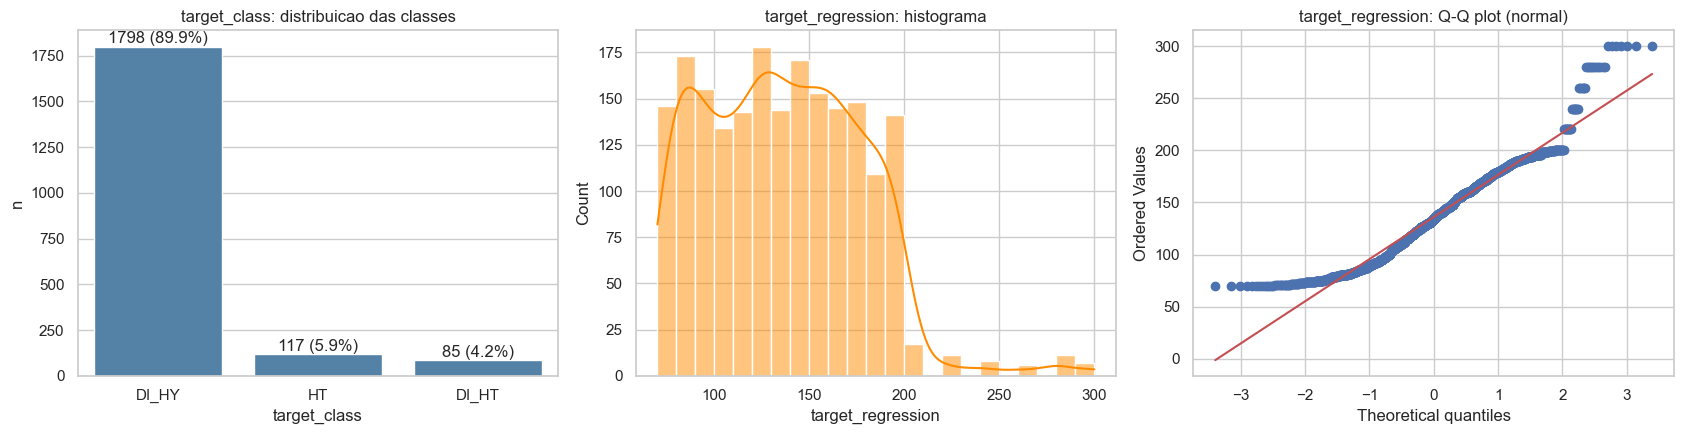

Racio de desequilibrio (maioritaria / minoritaria): 21.2
target_regression -> skew = 0.52, kurtosis = 0.42


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

counts = df[TARGET_CLS].value_counts()
sns.barplot(x=counts.index, y=counts.values, ax=axes[0], color='steelblue')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 20, f'{v} ({v/len(df):.1%})', ha='center')
axes[0].set_title('target_class: distribuicao das classes'); axes[0].set_ylabel('n')

sns.histplot(df[TARGET_REG], kde=True, ax=axes[1], color='darkorange')
axes[1].set_title('target_regression: histograma')

stats.probplot(df[TARGET_REG], dist='norm', plot=axes[2])
axes[2].set_title('target_regression: Q-Q plot (normal)')
plt.tight_layout(); plt.show()

print(f'Racio de desequilibrio (maioritaria / minoritaria): {counts.max() / counts.min():.1f}')
print(f'target_regression -> skew = {df[TARGET_REG].skew():.2f}, '
      f'kurtosis = {df[TARGET_REG].kurt():.2f}')

**Conclusões:**

- **`target_class` está muito desequilibrada**: `DI_HY` representa cerca de 90% dos registos, contra cerca de 6% de `HT` e 4% de `DI_HT`.
  Um classificador que preveja sempre `DI_HY` já teria cerca de 90% de *accuracy*. Por isso, na classificação devemos usar métricas como **F1 macro, *balanced accuracy*, recall por classe e matriz de confusão**, com **estratificação** nos métodos de reamostragem e, eventualmente, `class_weight='balanced'`.
- **`target_regression`** varia entre 70 e 300 e tem uma ligeira assimetria positiva (cauda à direita).

### 2.2 Features numéricas: histogramas e boxplots

Os **histogramas** mostram a forma de cada distribuição, se é simétrica ou assimétrica, se tem um ou
vários picos, e se é aproximadamente uniforme ou concentrada. Os ***boxplots*** mostram a mesma
informação sob outro ângulo, mediana, quartis e valores afastados, e permitem comparar a dispersão
entre variáveis.

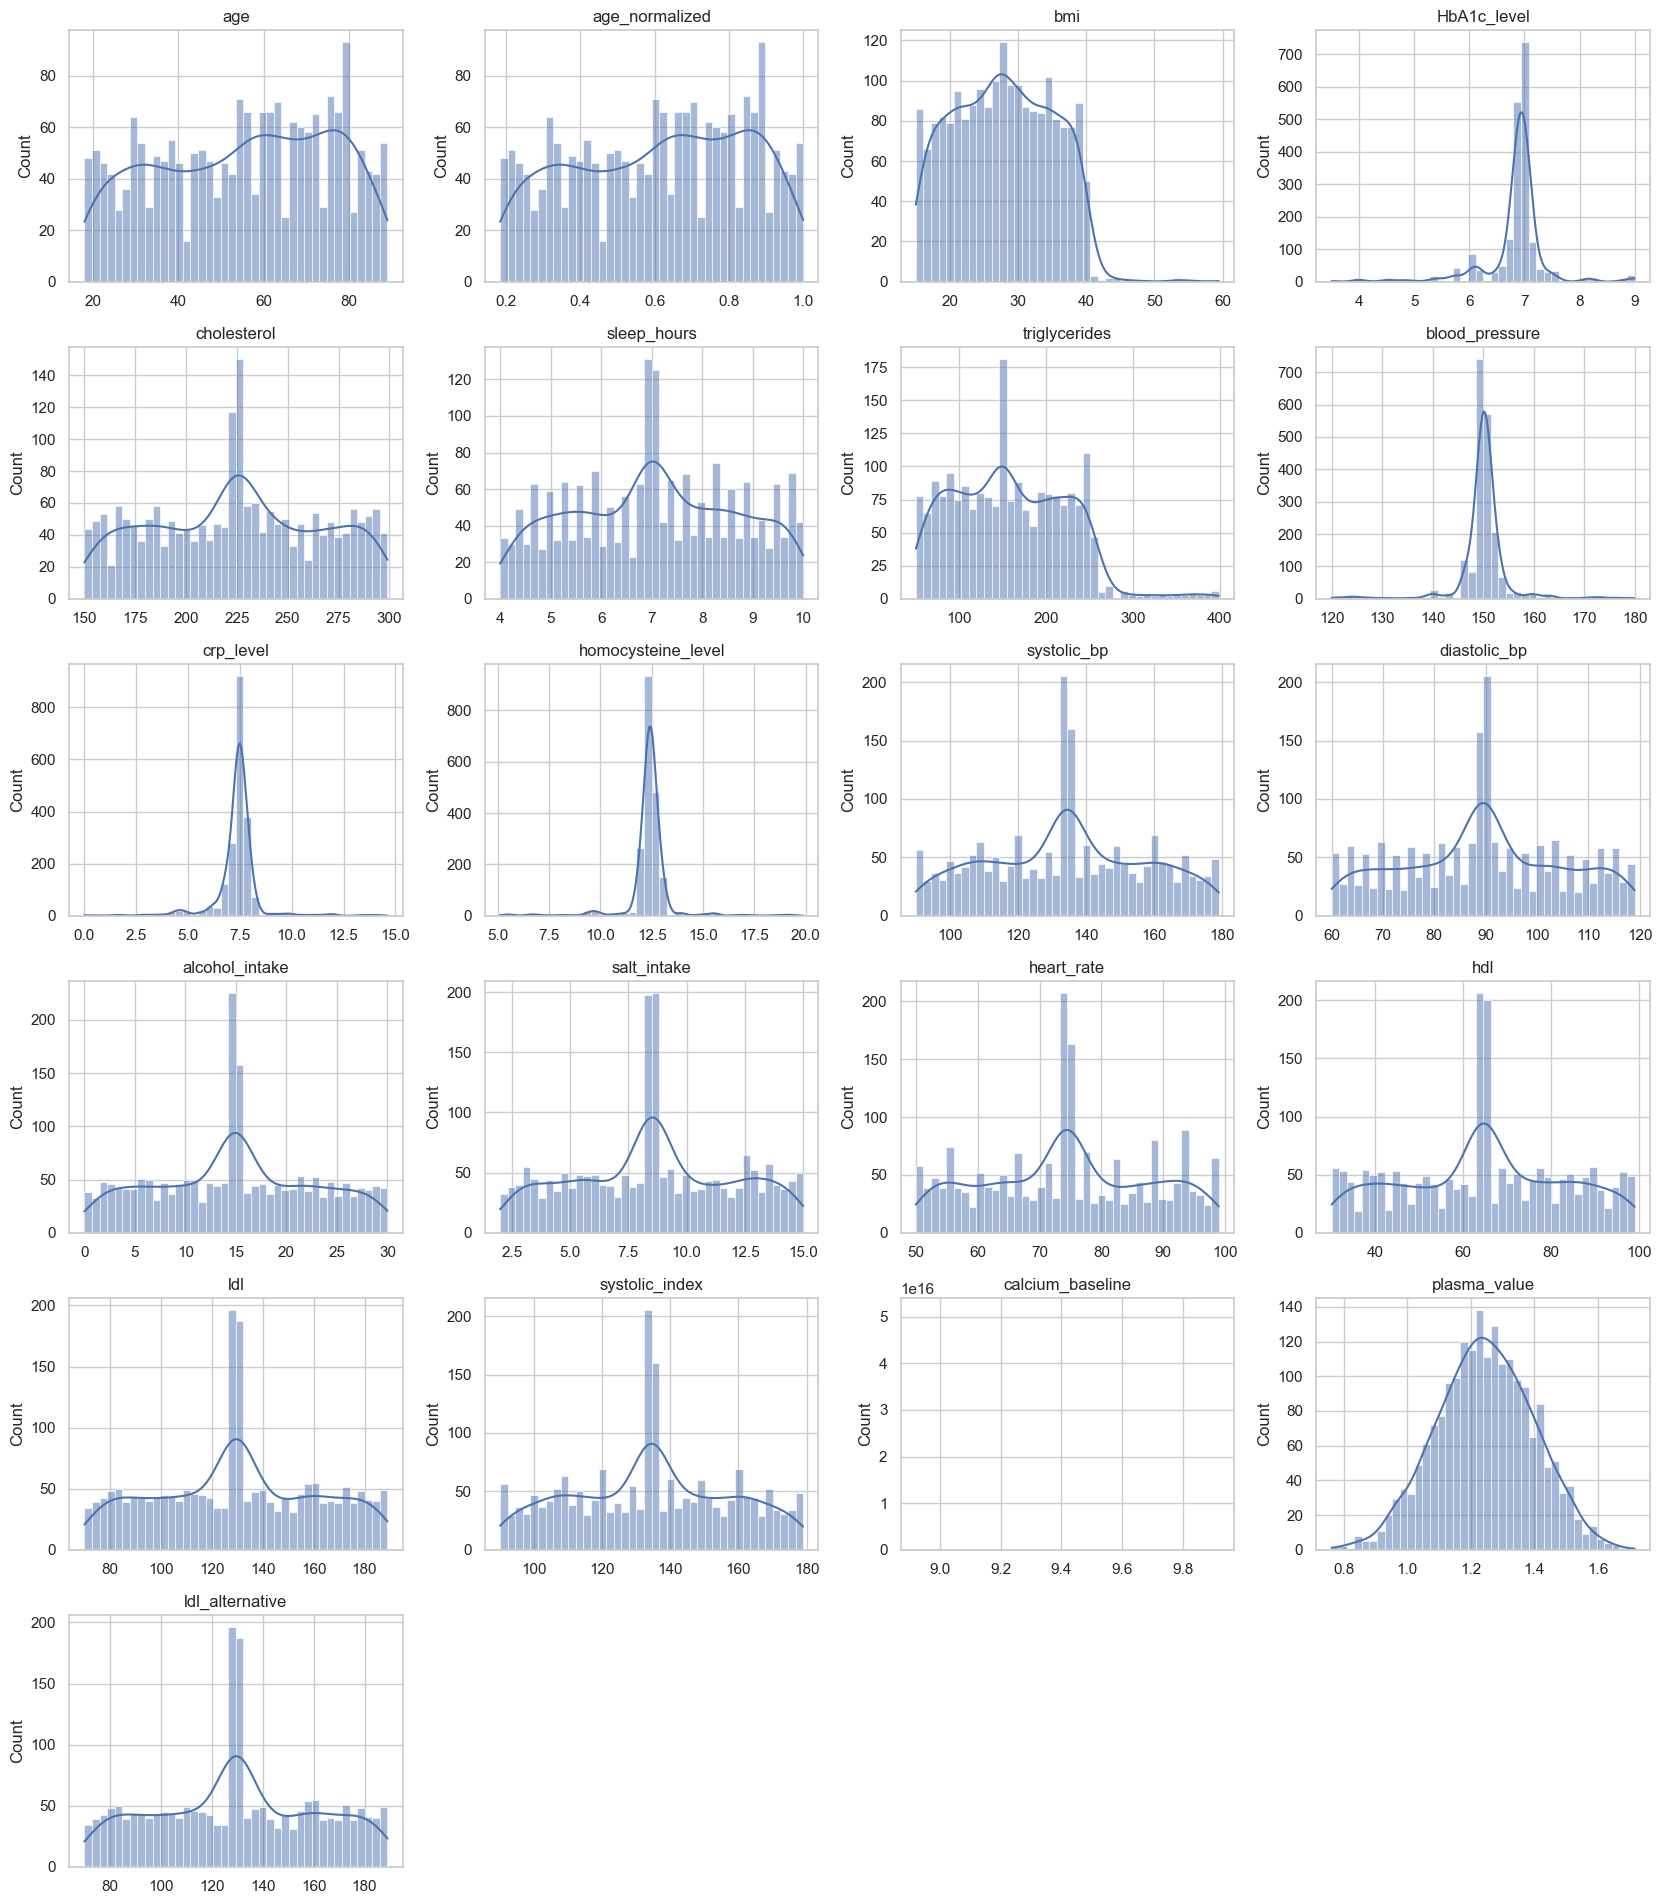

In [7]:
def grid_plot(cols, kind, ncols=4, size=(4.2, 3.2)):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size[0]*ncols, size[1]*nrows))
    axes = axes.ravel()
    for ax, c in zip(axes, cols):
        if kind == 'hist':
            sns.histplot(df[c], kde=True, ax=ax, bins=40)
        else:
            sns.boxplot(x=df[c], ax=ax, color='lightsteelblue')
        ax.set_title(c); ax.set_xlabel('')
    for ax in axes[len(cols):]:
        ax.set_visible(False)
    plt.tight_layout(); plt.show()

grid_plot(num_cols, 'hist')

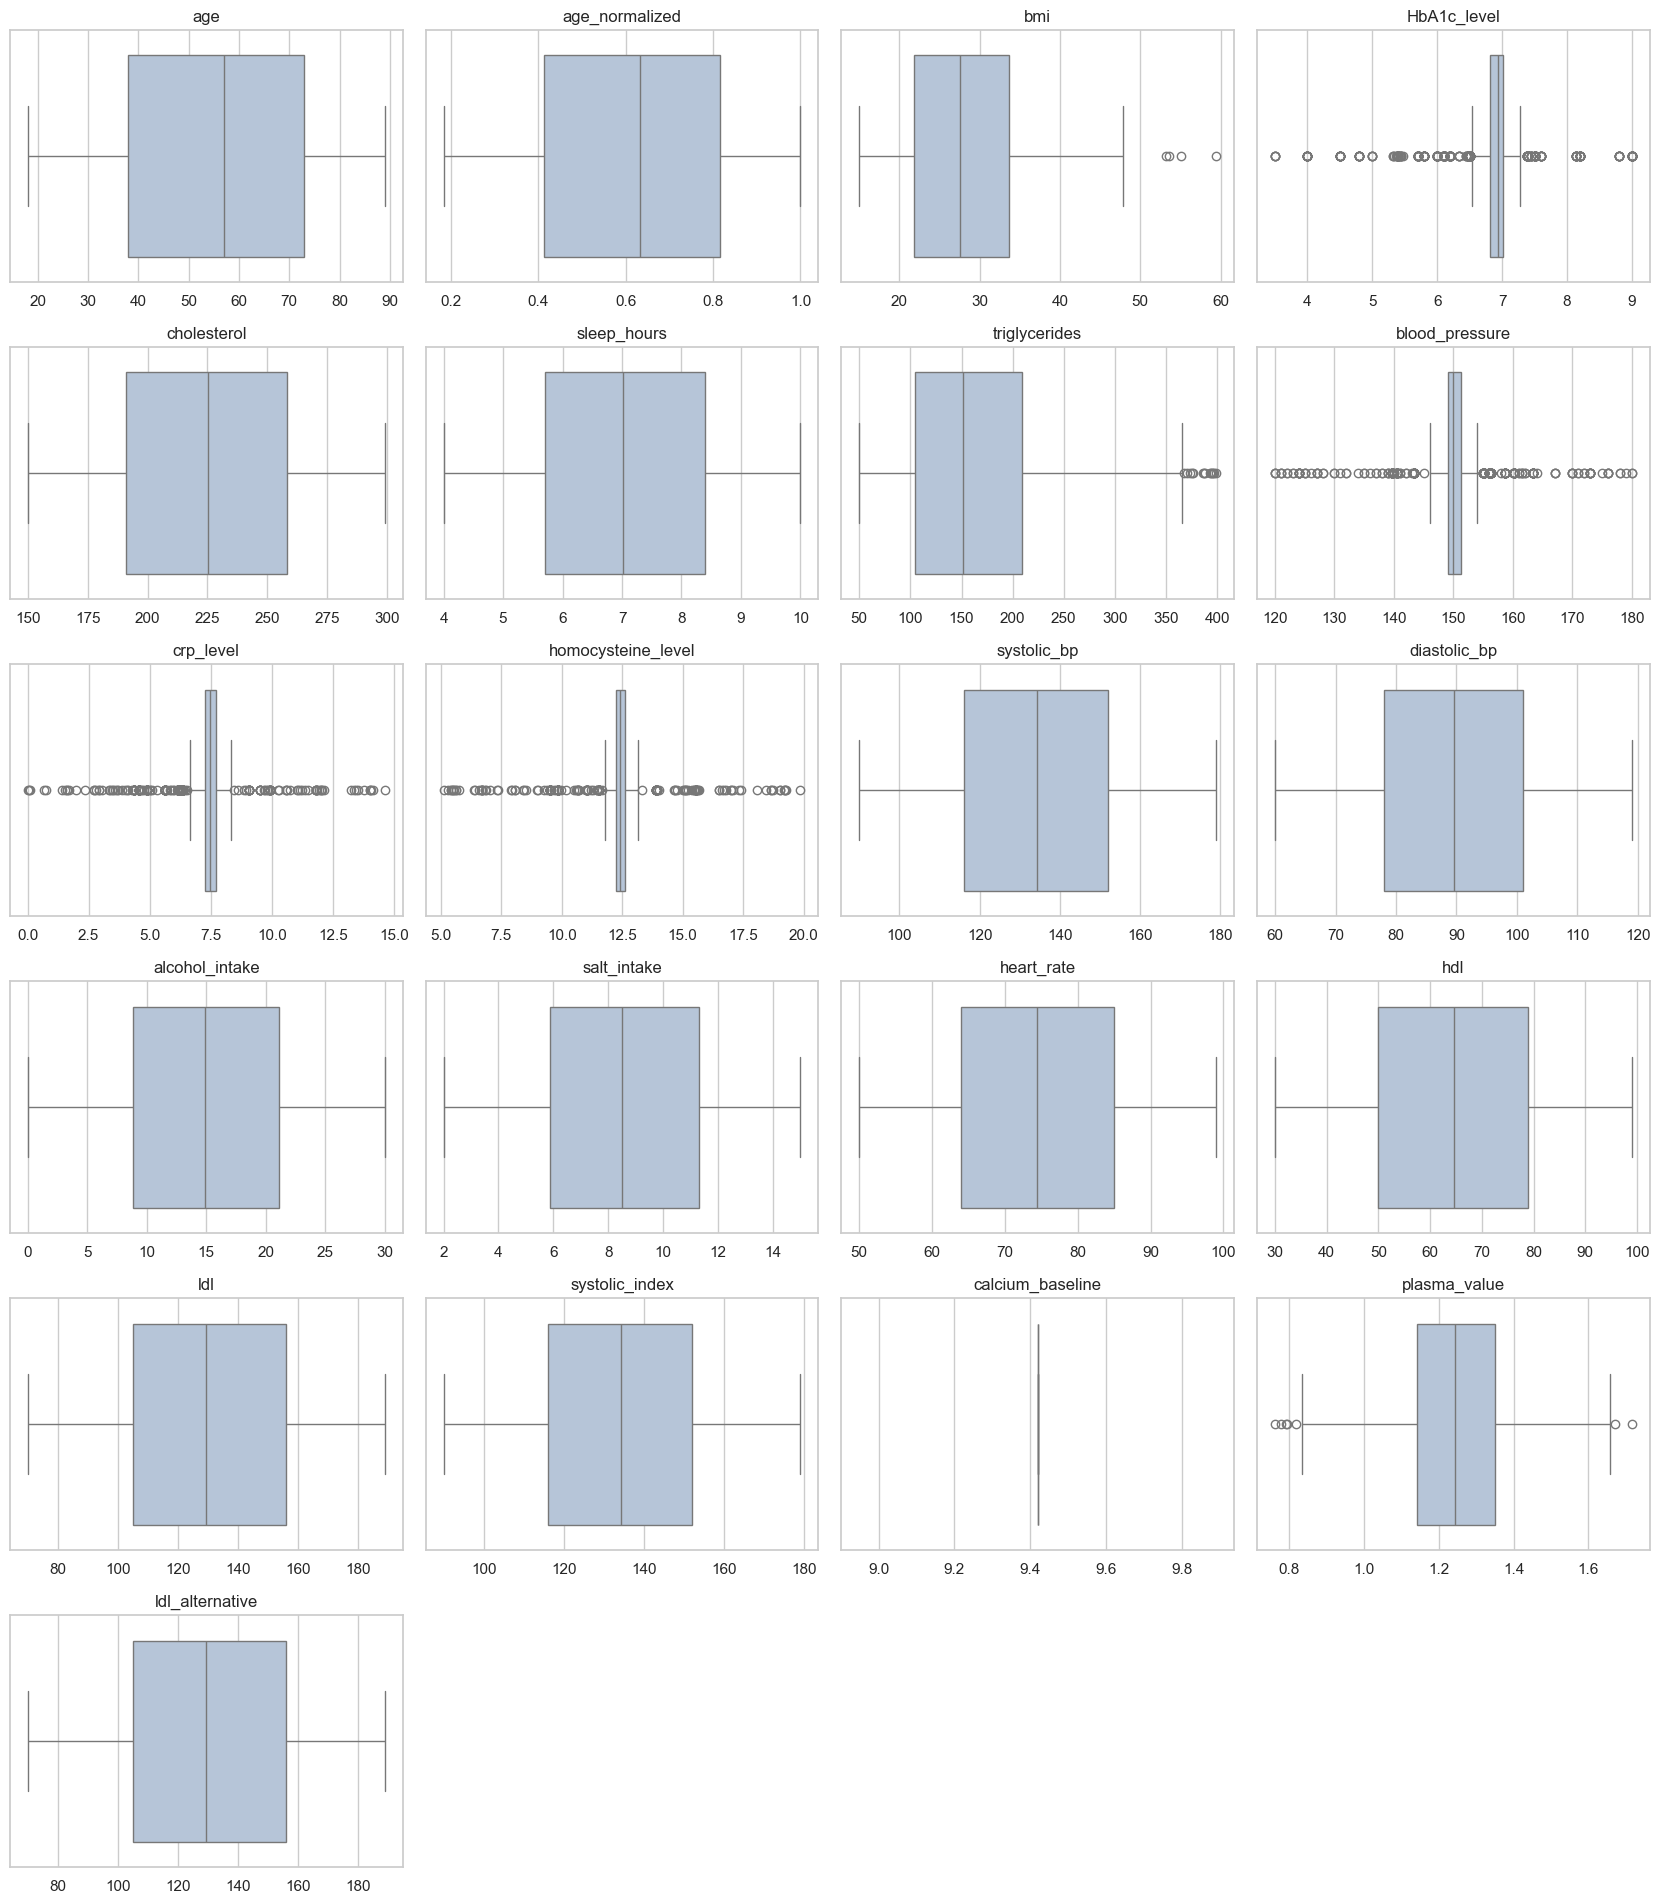

In [8]:
grid_plot(num_cols, 'box')

**Conclusões:** As distribuições agrupam-se em quatro padrões distintos:

- **Aproximadamente uniformes**: `age`, `cholesterol`, `sleep_hours`, `systolic_bp`, `diastolic_bp`,
  `alcohol_intake`, `salt_intake`, `heart_rate`, `hdl` e `ldl`. São distribuições quase "planas", com
  frequências semelhantes ao longo de todo o intervalo.
- **Muito concentradas, com caudas longas**: `HbA1c_level`, `blood_pressure`, `crp_level` e
  `homocysteine_level`. Confirmam a curtose elevada observada em 1.3.
- **Com assimetria positiva**: `bmi` e `triglycerides`.
- **Aproximadamente normal**: `plasma_value`.
- **Constante**: `calcium_baseline`, que aparece como uma única barra.

### 2.3 Deteção de outliers

A regra do intervalo interquartil assinala como *outlier* qualquer observação que fique mais de
1.5 × IQR abaixo do primeiro quartil ou acima do terceiro. É o critério implícito nos *boxplots* da
secção anterior.

Aplicamo-la a todas as variáveis numéricas para quantificar o número de **outlier**.

In [9]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()

out = pd.DataFrame({'n_outliers': {c: iqr_outliers(df[c]) for c in num_cols + [TARGET_REG]}})
out['%'] = out['n_outliers'] / len(df) * 100
out.sort_values('n_outliers', ascending=False)

,n_outliers,%
HbA1c_level,372,18.600
crp_level,228,11.400
blood_pressure,212,10.600
homocysteine_level,170,8.500
target_regression,18,0.900
triglycerides,14,0.700
plasma_value,7,0.350
bmi,4,0.200
heart_rate,0,0.000
ldl_alternative,0,0.000


**Conclusões:**
Os *outliers* concentram-se nas features leptocúrticas. Como o IQR destas variáveis é muito estreito, a regra 1.5×IQR marca como *outlier* muitos valores que são clinicamente plausíveis (por exemplo HbA1c de 5.4%).
Por isso **não os removemos automaticamente**. Na secção 3 veremos que, no caso de `HbA1c_level`, estes valores "extremos" estão associados a uma classe concreta (`HT`) e são informativos.

### 2.4 Features categóricas

A análise univariada das ***Features* Categóricas**, encontra-se desenvolvida no ponto 1.4.

## 3. Análise bivariada

### 3.1 Correlação entre features numéricas

Passamos agora a estudar **relações entre pares de variáveis**. Começamos pela matriz de correlação
entre as *features* numéricas, que serve dois objetivos distintos:

- **detetar redundância** - pares com correlação próxima de 1 contêm a mesma informação;
- **antecipar problemas de colinearidade** na regressão múltipla.

Calculamos as correlações de **Pearson** e de **Spearman**. Excluímos `calcium_baseline`, cuja
correlação é indefinida por ter variância nula.

Incluímos **as duas variáveis alvo** na matriz. A `target_regression` entra diretamente, por ser
contínua. A `target_class` é categórica, pelo que entra sob a forma de três indicadores binários, um
por classe. A correlação entre uma variável contínua e um indicador binário é a **correlação
ponto-bisserial**, que é interpretável da mesma forma. Assim, a matriz passa a mostrar também quanto
cada *feature* se relaciona com cada um dos alvos, e os dois alvos entre si.

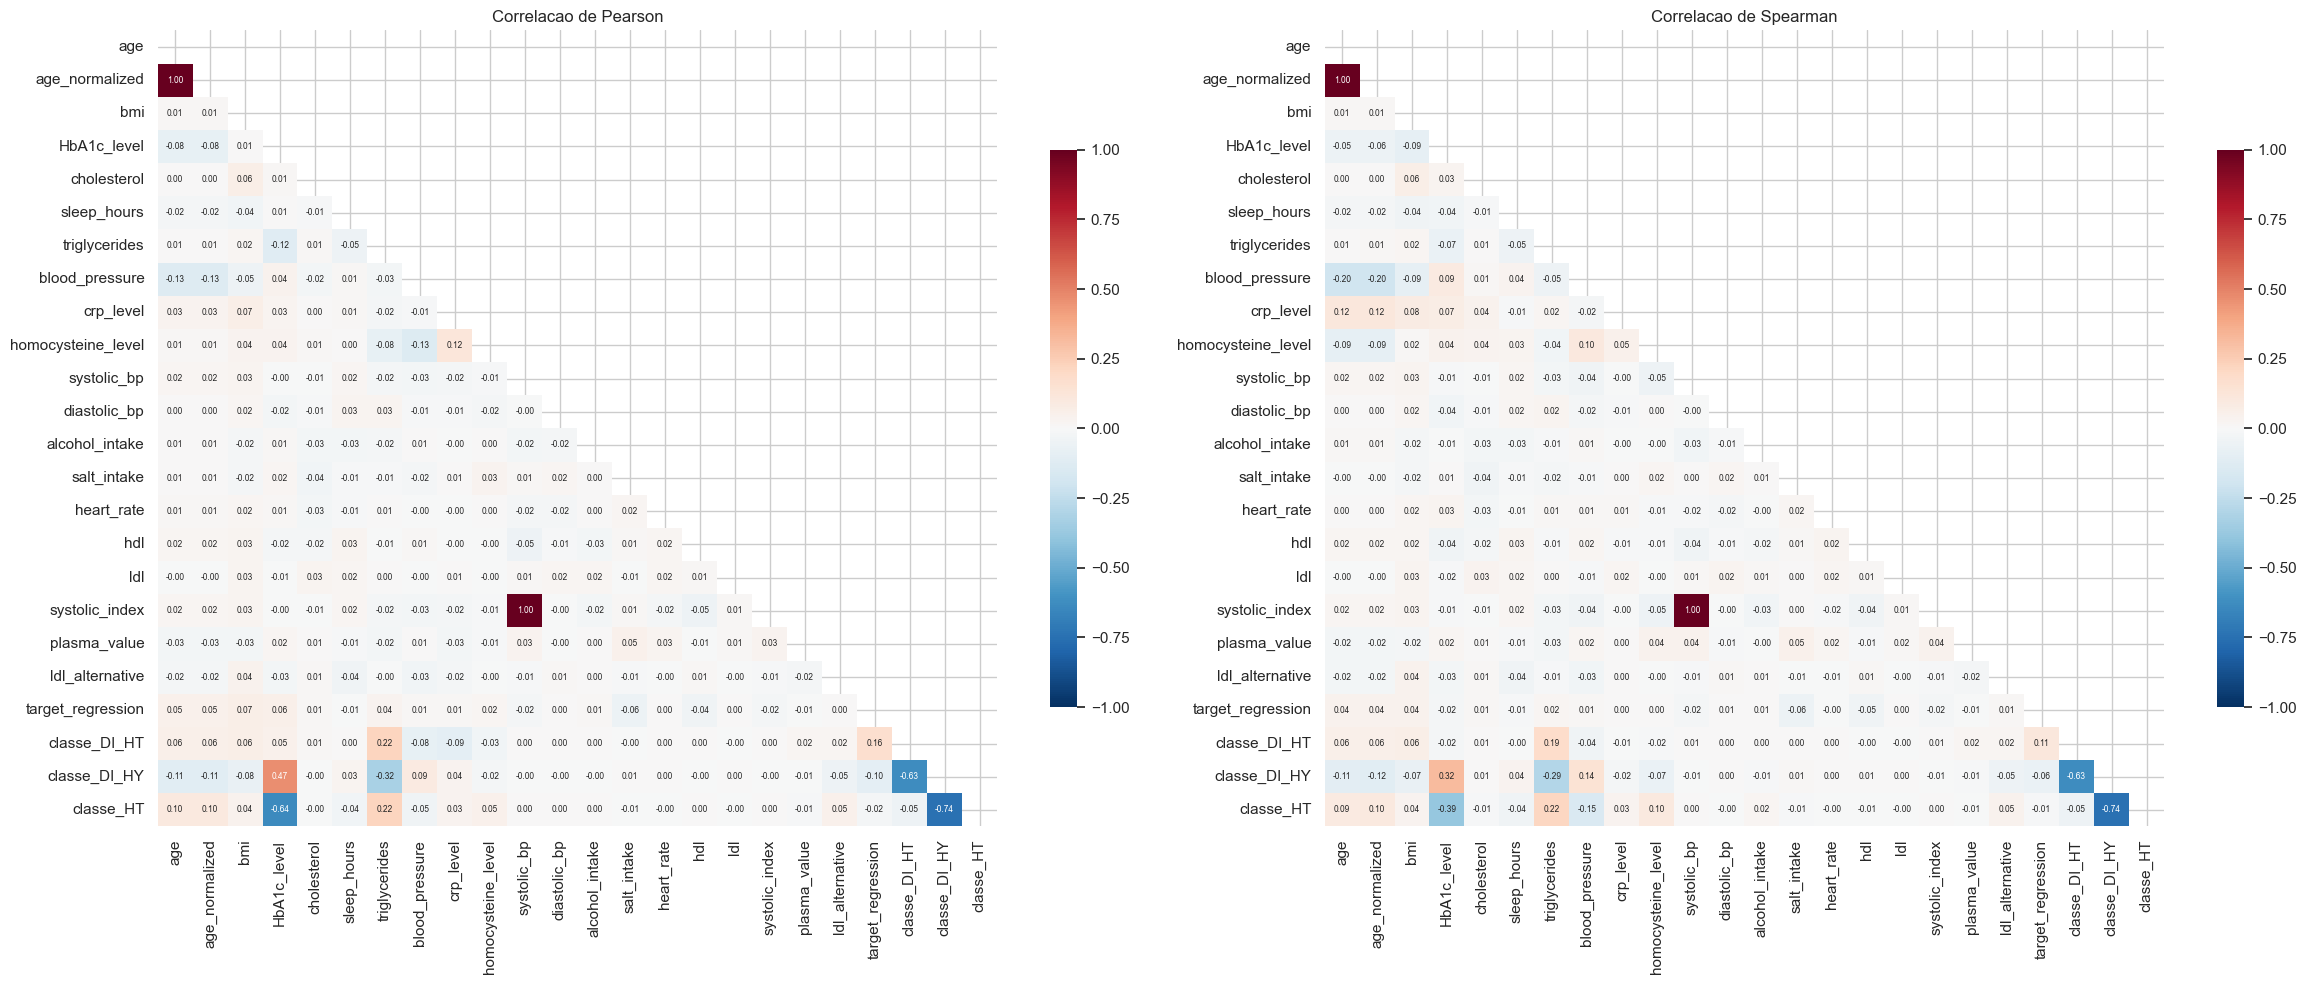

In [10]:
# Indicadores binarios de target_class, para que a relacao de cada numerica com as
# classes possa ser lida na mesma matriz (correlacao ponto-bisserial)
ind_classe = pd.get_dummies(df[TARGET_CLS], prefix='classe').astype(int)

base_corr = pd.concat([df[num_cols].drop(columns='calcium_baseline'),
                       df[[TARGET_REG]], ind_classe], axis=1)

corr_p = base_corr.corr(method='pearson')
corr_s = base_corr.corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(24, 10))
for ax, m, t in zip(axes, [corr_p, corr_s], ['Pearson', 'Spearman']):
    sns.heatmap(m, mask=np.triu(np.ones_like(m, dtype=bool)), cmap='RdBu_r', vmin=-1, vmax=1,
                center=0, annot=True, fmt='.2f', annot_kws={'size': 6}, ax=ax,
                cbar_kws={'shrink': .7})
    ax.set_title(f'Correlacao de {t}')
plt.tight_layout(); plt.show()

In [11]:
upper = corr_p.where(np.triu(np.ones(corr_p.shape, dtype=bool), k=1)).stack()
high_pairs = upper[upper.abs() > 0.3].sort_values(key=abs, ascending=False).to_frame('pearson')
high_pairs

,,pearson
systolic_bp,systolic_index,1.000
age,age_normalized,1.000
classe_DI_HY,classe_HT,-0.744
HbA1c_level,classe_HT,-0.640
classe_DI_HT,classe_DI_HY,-0.629
HbA1c_level,classe_DI_HY,0.466
triglycerides,classe_DI_HY,-0.323


**Conclusões:** Apenas **dois pares** de *features* apresentam correlação elevada, `age` com `age_normalized` e `systolic_bp` com `systolic_index`, em ambos os casos
com correlação igual ou praticamente igual a 1.

Fora destes dois pares, **as correlações entre *features* são praticamente nulas**, quase todas abaixo
de 0.05 em valor absoluto.

Quanto aos alvos, a leitura é bastante assimétrica. Nenhuma *feature* ultrapassa |r| = 0.07 com
`target_regression`, o que antecipa a dificuldade da tarefa de regressão. Já com os indicadores de
`target_class` surgem valores claramente maiores, com `HbA1c_level` a atingir |r| = 0.64 e
`triglycerides` 0.32, o que indica existir sinal aproveitável para a classificação.

Os dois alvos apresentam entre si uma correlação moderada, com |r| = 0.16 entre `target_regression` e
o indicador da classe `DI_HT`. A relação existe mas é fraca, e é quantificada de forma apropriada na
secção 3.5.

### 3.2 Confirmação empírica da redundância

A matriz de correlação **sugere** redundância, mas não a prova. Duas variáveis podem ter correlação 1 e não ser a mesma coluna, e podem ter correlação 0 e ainda assim estar relacionadas. Antes de remover qualquer *feature* é preciso verificar exatamente **que tipo de relação** existe.

Testamos três hipóteses: 
- se `age_normalized` é uma transformação monótona de `age`; 
- se `systolic_index` é uma cópia exata de `systolic_bp` linha a linha; 
- e se `ldl_alternative` contém os mesmos valores de `ldl` noutra ordem.

A fechar a secção, medimos o efeito conjunto da redundância sobre a matriz de dados.

In [12]:
print('--- age vs age_normalized ---')
print('  Spearman:', round(stats.spearmanr(df.age, df.age_normalized)[0], 6))
print('  Pearson :', round(df.age.corr(df.age_normalized), 6))
expected = (df.age - 2) / 87
print('  formula (age - 2) / 87 -> residuo maximo:',
      f'{float((df.age_normalized - expected).abs().max()):.2e}')

print('\n--- systolic_bp vs systolic_index ---')
print('  iguais em todas as linhas:', (df.systolic_bp == df.systolic_index).all())

print('\n--- ldl vs ldl_alternative ---')
print('  mesmo conjunto de valores (ordenados):',
      np.allclose(np.sort(df.ldl), np.sort(df.ldl_alternative)))
print('  linhas em que coincidem:', int(df.ldl.eq(df.ldl_alternative).sum()), 'de', len(df))
print('  correlacao de Pearson:', round(df.ldl.corr(df.ldl_alternative), 4))

--- age vs age_normalized ---
  Spearman: 0.999951
  Pearson : 1.0
  formula (age - 2) / 87 -> residuo maximo: 9.89e-07

--- systolic_bp vs systolic_index ---
  iguais em todas as linhas: True

--- ldl vs ldl_alternative ---
  mesmo conjunto de valores (ordenados): True
  linhas em que coincidem: 18 de 2000
  correlacao de Pearson: -0.0049


**Conclusões:**

- **`age_normalized` é uma reescala determinística de `age`.** **É redundante**, as duas colunas contêm literalmente a mesma informação, e por isso basta manter `age`.
- **`systolic_index` é uma cópia exata de `systolic_bp`**, igual em todas as 2000 linhas. A definição
  vaga do enunciado ("índice secundário de dinâmica de pressão hemodinâmica") não corresponde a nada de
  novo nos dados. **É redundante.**
- `ldl_alternative` tem exatamente o mesmo conjunto de valores de
  `ldl`, mas coincide com ela em apenas 18 das 2000 linhas, e a correlação entre ambas é praticamente nula. Isto é compatível com uma **permutação
  aleatória das linhas de `ldl`**, do qual a coluna tem a distribuição certa, mas o valor de cada paciente não lhe pertence.

Há ainda uma quarta verificação a fazer, de natureza diferente. As três anteriores olham para pares de
colunas; esta mede o efeito **conjunto** da redundância sobre a matriz de dados.

Usamos duas medidas. O **número de condição** da matriz padronizada cresce à medida que as colunas se
tornam linearmente dependentes, e serve de alarme global. O **VIF**, ou fator de inflação da variância,
diz, para cada variável, quantas vezes a variância do seu coeficiente é inflacionada pela colinearidade
com as restantes, e obtém-se da diagonal da inversa da matriz de correlação. Um VIF de 1 significa
ausência total de colinearidade.

In [13]:
def numero_de_condicao(dados):
    """Numero de condicao da matriz padronizada: cresce com a colinearidade."""
    padronizado = (dados - dados.mean()) / dados.std()
    return float(np.linalg.cond(padronizado.values))

def vif_das_colunas(dados):
    """VIF de cada coluna, pela diagonal da inversa da matriz de correlacao."""
    R = np.corrcoef(dados.values, rowvar=False)
    if np.linalg.matrix_rank(R) < R.shape[0]:
        return None          # ha dependencia exata, a inversa nao existe
    return pd.Series(np.diag(np.linalg.inv(R)), index=dados.columns)

REDUNDANTES = ['age_normalized', 'systolic_index', 'ldl_alternative']
num_sem_constante = [c for c in num_cols if c != 'calcium_baseline']   # variancia zero
antes = df[num_sem_constante]
depois = df[[c for c in num_sem_constante if c not in REDUNDANTES]]

R_antes = np.corrcoef(antes.values, rowvar=False)
print(f'Com as colunas redundantes ({antes.shape[1]} variaveis):')
print(f'  posto da matriz de correlacao: {np.linalg.matrix_rank(R_antes)} de {antes.shape[1]}')
print(f'  numero de condicao: {numero_de_condicao(antes):.3g}')
print(f'  VIF calculavel: {vif_das_colunas(antes) is not None}')

print('\nVIF de cada par suspeito, calculado a dois:')
for a, b in [('age', 'age_normalized'), ('systolic_bp', 'systolic_index'),
             ('ldl', 'ldl_alternative')]:
    r = df[a].corr(df[b])
    print(f'  {a:12} vs {b:16} r = {r: .6f}  ->  VIF = {1 / (1 - r ** 2):.6g}')

print(f'\nSem as colunas redundantes ({depois.shape[1]} variaveis):')
print(f'  numero de condicao: {numero_de_condicao(depois):.3g}')
vif_final = vif_das_colunas(depois).sort_values(ascending=False)
print(f'  VIF maximo: {vif_final.max():.4f}'
      f'  |  todos abaixo de 1.05: {bool((vif_final < 1.05).all())}')
vif_final.round(4).to_frame('VIF').T

Com as colunas redundantes (20 variaveis):
  posto da matriz de correlacao: 19 de 20
  numero de condicao: 1.75e+15
  VIF calculavel: False

VIF de cada par suspeito, calculado a dois:
  age          vs age_normalized   r =  1.000000  ->  VIF = 5.08766e+11
  systolic_bp  vs systolic_index   r =  1.000000  ->  VIF = 4.5036e+15
  ldl          vs ldl_alternative  r = -0.004942  ->  VIF = 1.00002

Sem as colunas redundantes (17 variaveis):
  numero de condicao: 1.29
  VIF maximo: 1.0441  |  todos abaixo de 1.05: True


,homocysteine_level,blood_pressure,triglycerides,HbA1c_level,age,crp_level,bmi,cholesterol,sleep_hours,systolic_bp,plasma_value,hdl,salt_intake,alcohol_intake,diastolic_bp,heart_rate,ldl
VIF,1.044,1.041,1.027,1.026,1.025,1.023,1.019,1.010,1.008,1.008,1.008,1.007,1.007,1.005,1.005,1.004,1.004


**Conclusões:**

Com as vinte colunas numéricas originais, a matriz de correlação tem **posto 19 em 20**. Falta-lhe uma
dimensão, o que significa que existe uma **dependência linear exata** entre colunas. Por isso a matriz
não é invertível e **o VIF nem sequer é calculável**. O número de condição, 1.75e+15, confirma o
diagnóstico: valores acima de 30 já são considerados problemáticos.

Calculados a dois, os pares suspeitos separam-se com clareza:

- `age` e `age_normalized`, com VIF da ordem de 1e+11;
- `systolic_bp` e `systolic_index`, com VIF da ordem de 1e+15, por serem exatamente iguais;
- `ldl` e `ldl_alternative`, com **VIF igual a 1.00002**, ou seja, nenhuma colinearidade.

Este último resultado é importante e merece ser lido com atenção. **`ldl_alternative` não é removida
por colinearidade**, ao contrário das outras duas. O seu problema é diferente e foi demonstrado acima:
contém os valores de `ldl` noutra ordem, pelo que o valor que aparece em cada linha não pertence
àquele paciente.

Removidas as três colunas, o quadro muda por completo. O número de condição cai de 1.75e+15 para
**1.29**, e **todos os VIF ficam abaixo de 1.05**, com o máximo em 1.0441 (`homocysteine_level`). Não
há multicolinearidade nenhuma entre as variáveis retidas.

Isto tem uma consequência prática para a Parte 4 deste trabalho: a razão de ser do **Ridge** é estabilizar
coeficientes quando os preditores estão correlacionados, e aqui não há nada para estabilizar. É
previsível que o Ridge não traga ganho sobre uma solução não regularizada, e esta é a evidência que
permite afirmá-lo.

### 3.3 Coerência entre features derivadas e as suas variáveis de origem

O enunciado indica que `age_level` e `bmi_level` são categorias derivadas de `age` e `bmi`. Pelos nomes,
`low_hdl_cholesterol` e `high_ldl_cholesterol` serão *flags* construídas a partir de `hdl` e `ldl`.

Vale a pena verificar se essa correspondência se confirma nos dados. Comparamos cada *flag* com o
limiar clínico habitual (HDL < 40 e LDL ≥ 130) para avaliar a nitidez.

Acrescentamos um quinto painel que serve um propósito diferente. Se `high_ldl_cholesterol` foi
construída a partir dos valores de LDL do paciente, então deve relacionar-se com `ldl`, mas não tem
razão para se relacionar com `ldl_alternative` caso esta última seja, como a secção 3.2 sugere, uma
permutação aleatória das linhas. Comparar os dois painéis lado a lado é um teste direto a essa
hipótese.

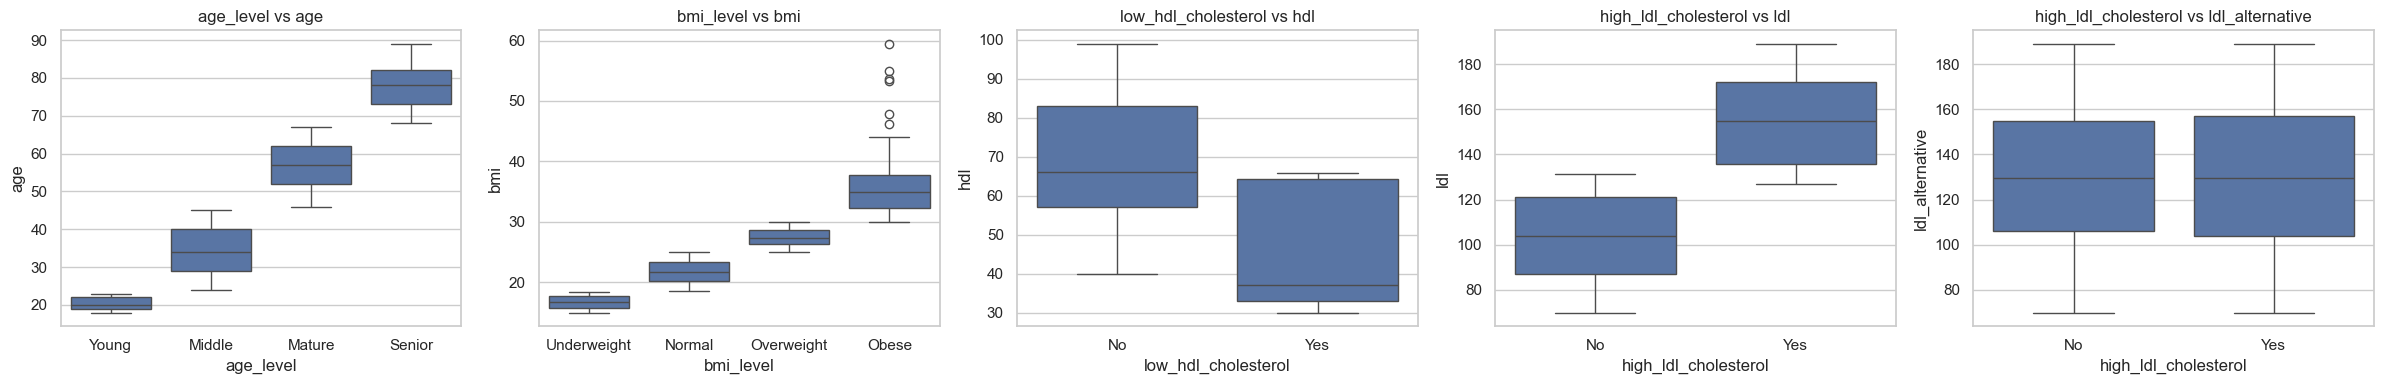

hdl < 40             False  True 
low_hdl_cholesterol              
No                    1647      0
Yes                    105    248

ldl >= 130            False  True 
high_ldl_cholesterol              
No                      940     38
Yes                     116    906

ldl_alternative >= 130  False  True 
high_ldl_cholesterol                
No                        521    457
Yes                       535    487

ldl              media No= 103.56  Yes= 155.01

ldl_alternative  media No= 129.73  Yes= 129.97


In [14]:
fig, axes = plt.subplots(1, 5, figsize=(24, 4))
sns.boxplot(data=df, x='age_level', y='age',
            order=['Young','Middle','Mature','Senior'], ax=axes[0])
sns.boxplot(data=df, x='bmi_level', y='bmi',
            order=['Underweight','Normal','Overweight','Obese'], ax=axes[1])
sns.boxplot(data=df, x='low_hdl_cholesterol', y='hdl', ax=axes[2])
sns.boxplot(data=df, x='high_ldl_cholesterol', y='ldl', ax=axes[3])
sns.boxplot(data=df, x='high_ldl_cholesterol', y='ldl_alternative', ax=axes[4])
for ax in axes: ax.set_title(f'{ax.get_xlabel()} vs {ax.get_ylabel()}')
plt.tight_layout(); plt.show()

print(pd.crosstab(df.low_hdl_cholesterol, df.hdl < 40, colnames=['hdl < 40']))
print()
print(pd.crosstab(df.high_ldl_cholesterol, df.ldl >= 130, colnames=['ldl >= 130']))
print()
print(pd.crosstab(df.high_ldl_cholesterol, df.ldl_alternative >= 130,
                  colnames=['ldl_alternative >= 130']))

for coluna in ('ldl', 'ldl_alternative'):
    grupos = [df.loc[df.high_ldl_cholesterol == k, coluna] for k in ('No', 'Yes')]
    print(f'\n{coluna:16s} media No={grupos[0].mean():7.2f}  Yes={grupos[1].mean():7.2f}')

**Conclusões:** `age_level` e `bmi_level` correspondem a **discretizações nítidas** de `age` e `bmi`.

Já nas variáveis `low_hdl_cholesterol` e `high_ldl_cholesterol` há alguma sobreposição, ou seja, o
limiar não é perfeitamente nítido, mas a associação é forte. A tabela de contingência confirma-o: dos
1022 registos marcados com `Yes` em `high_ldl_cholesterol`, 906 têm de facto `ldl` igual ou superior a
130.

**O quinto painel é o resultado mais relevante desta secção.** Enquanto `ldl` separa com clareza os dois
níveis da *flag*, com médias de 103.6 e 155.0, `ldl_alternative` **não apresenta qualquer relação com ela**. As médias são de 129.7 e 130.0, ou seja, as duas distribuições são indistinguíveis. 

Esta é a confirmação independente de que `ldl_alternative` **não pertence ao paciente**.Não se relacionando, fica demonstrado que os seus valores estão desligados do registo
em que aparecem, o que a torna uma candidata a remoção e não apenas uma variável suspeita.

Em qualquer dos casos, as quatro variáveis derivadas são **parcialmente redundantes** com as suas
variáveis de origem. Num modelo linear, a prática habitual é ficar com a variável contínua, que preserva
mais informação do que a sua versão agrupada em intervalos.

### 3.4 Features numéricas vs `target_regression`

Esta análise vai nos vai orientar na escolha do preditor para
a regressão linear simples e do conjunto de preditores para a múltipla.

Calculamos duas medidas complementares, para não depender de uma só:

- a **correlação de Pearson**, que mede a força da relação **linear**, que é a que os modelos de
  regressão linear conseguem aproveitar;
- a **correlação de Spearman**, que mede relações monótonas ainda que curvas, e que serve para
  despistar a hipótese de existir uma relação forte mas não linear que o coeficiente de Pearson
  estaria a subestimar.

Acrescentamos o **p-value** do teste de Pearson, que testa a hipótese nula de ausência de relação (β₁ = 0).

In [15]:
# Working set: excludes the constant feature and the two redundant ones confirmed in 3.2
num_feats = [c for c in num_cols
             if c not in ('calcium_baseline', 'age_normalized', 'systolic_index')]

rel_reg = pd.DataFrame({
    'pearson': [df[c].corr(df[TARGET_REG]) for c in num_feats],
    'spearman': [df[c].corr(df[TARGET_REG], method='spearman') for c in num_feats],
    'p_value_pearson': [stats.pearsonr(df[c], df[TARGET_REG])[1] for c in num_feats],
}, index=num_feats)
rel_reg = rel_reg.sort_values('pearson', key=abs, ascending=False)
rel_reg

,pearson,spearman,p_value_pearson
bmi,0.070,0.044,0.002
salt_intake,-0.062,-0.062,0.005
HbA1c_level,0.055,-0.023,0.013
age,0.054,0.043,0.017
hdl,-0.040,-0.046,0.074
triglycerides,0.037,0.019,0.096
systolic_bp,-0.018,-0.016,0.426
homocysteine_level,0.016,0.002,0.474
blood_pressure,0.015,0.011,0.509
cholesterol,0.011,0.011,0.616


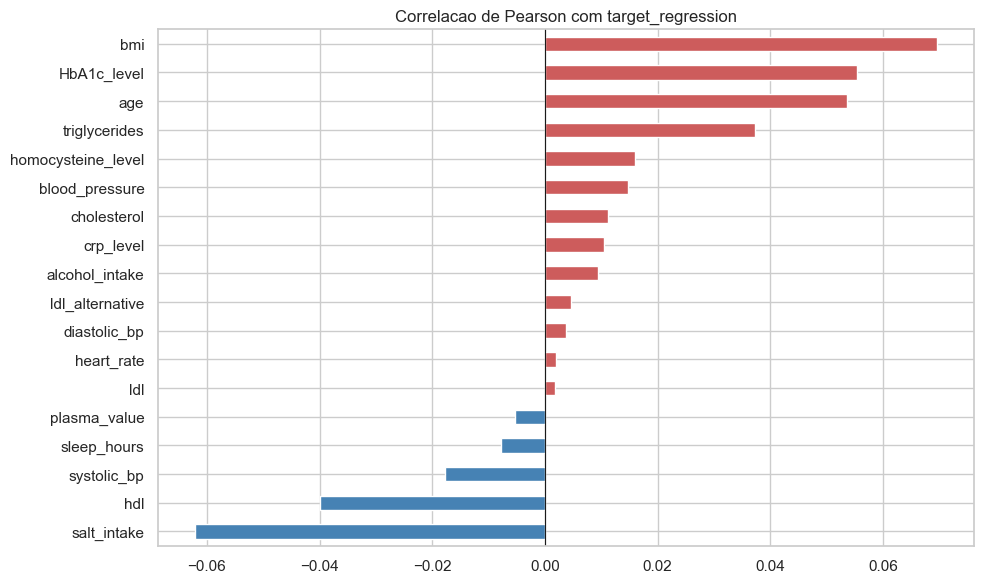

In [16]:
fig, ax = plt.subplots(figsize=(10, 6))
serie = rel_reg['pearson'].sort_values()
serie.plot.barh(ax=ax, color=np.where(serie > 0, 'indianred', 'steelblue'))
ax.axvline(0, color='k', lw=.8)
ax.set_title('Correlacao de Pearson com target_regression')
plt.tight_layout(); plt.show()

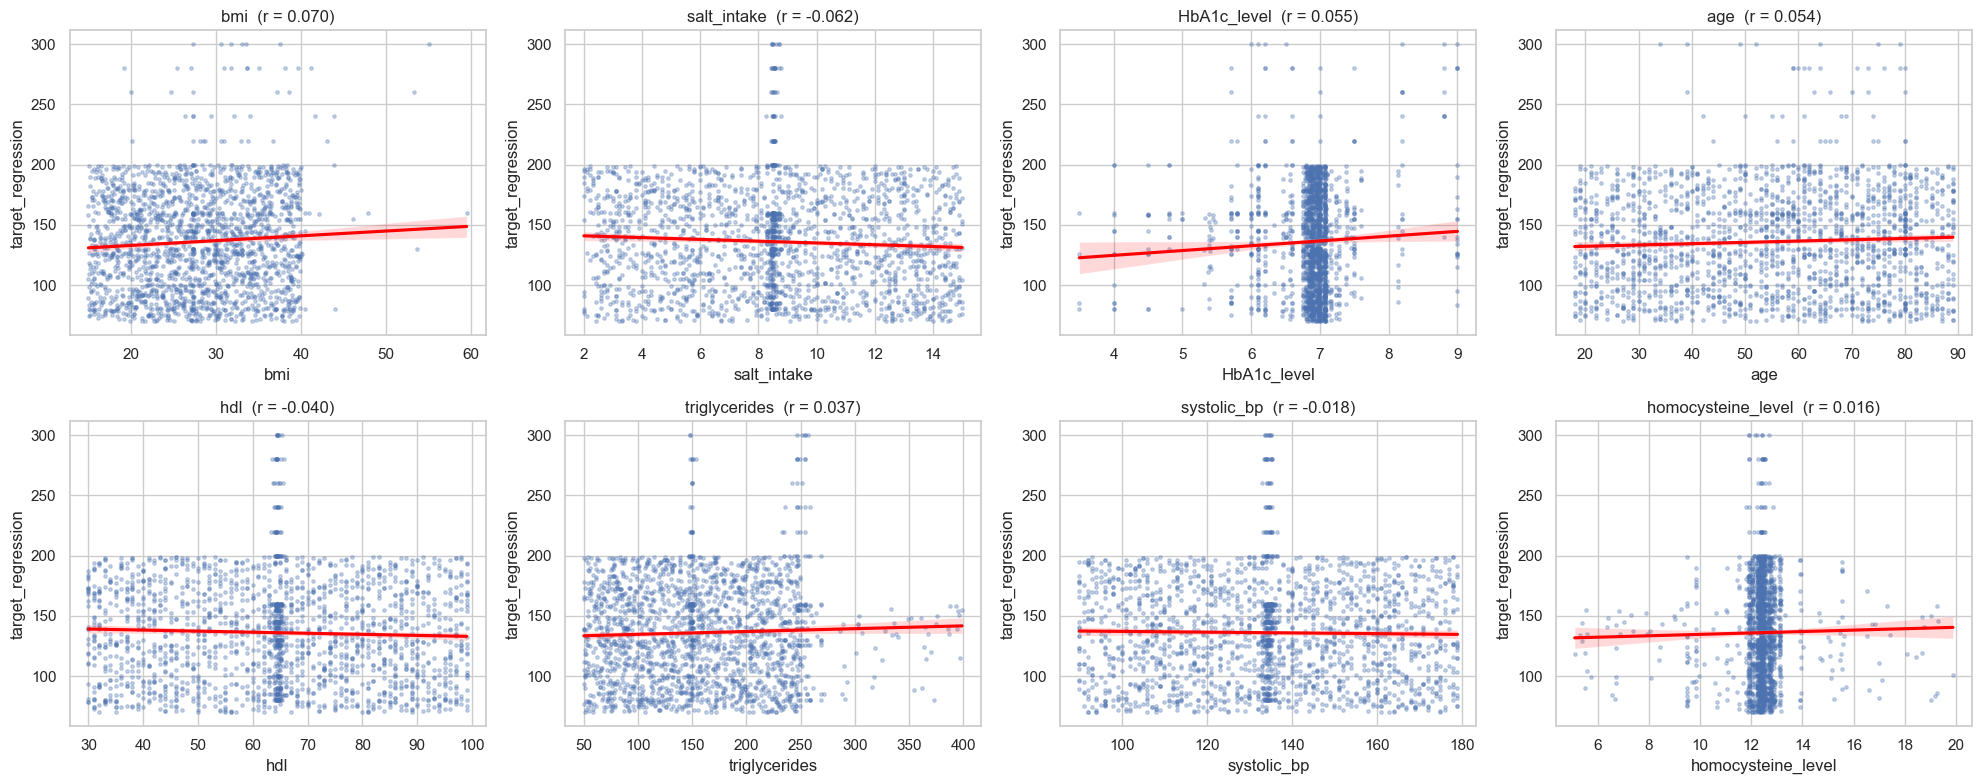

In [17]:
top = rel_reg.index[:8]
fig, axes = plt.subplots(2, 4, figsize=(20, 8)); axes = axes.ravel()
for ax, c in zip(axes, top):
    sns.regplot(data=df, x=c, y=TARGET_REG, ax=ax,
                scatter_kws={'s': 6, 'alpha': .3}, line_kws={'color': 'red'})
    ax.set_title(f'{c}  (r = {rel_reg.loc[c, "pearson"]:.3f})')
plt.tight_layout(); plt.show()

**Conclusões:**

**Nenhuma *feature* numérica tem uma relação linear relevante com `target_regression`.** O maior valor
absoluto de correlação é o de `bmi`, com r ≈ 0.070. Seguem-se `salt_intake` (−0.062), `HbA1c_level`
(0.055) e `age` (0.054), que são estatisticamente significativos (p < 0.05) devido ao tamanho da
amostra (n = 2000). Todos os restantes ficam ainda mais próximos de zero. Nas retas ajustadas dos
gráficos de dispersão isto é visível a olho nu, as nuvens de pontos são praticamente horizontais.

As correlações de **Spearman são muito semelhantes às de Pearson**, o que permite excluir a hipótese
de existir uma relação forte mas curva que o coeficiente de Pearson estivesse a subestimar. A
associação é genuinamente fraca, e não um artefacto da forma como foi medida.

É de esperar um **R² muito baixo**, tanto na regressão linear simples como na múltipla. A variável com
maior efeito sobre `target_regression` é, como veremos a seguir, a própria `target_class`. Por ser o
alvo da outra tarefa, e não um alvo desta, nada impede que seja usada como preditor na regressão, e é
por essa razão que a incluímos nestas comparações.

### 3.5 Features categóricas vs `target_regression`

Para avaliar a relação entre uma variável categórica e uma variável contínua, aplicamos dois testes:

- a **ANOVA** (teste F), que é paramétrico e assume normalidade e homogeneidade de variâncias;
- o **Kruskal-Wallis**, que é a alternativa não paramétrica, baseada em ordens.

Calculamos também o **η² (eta quadrado)**, que mede a **proporção da variância** de `target_regression`
explicada por cada variável categórica. É esta medida de tamanho de efeito, e não o p-value, que nos diz
se a variável é **praticamente** útil.

In [18]:
rows = []
for c in cat_cols + [TARGET_CLS]:
    groups = [g[TARGET_REG].values for _, g in df.groupby(c)]
    F, p_anova = stats.f_oneway(*groups)
    H, p_kw = stats.kruskal(*groups)
    ss_between = sum(len(g) * (g.mean() - df[TARGET_REG].mean())**2 for g in groups)
    eta2 = ss_between / ((df[TARGET_REG] - df[TARGET_REG].mean())**2).sum()
    rows.append({'feature': c, 'F_anova': F, 'p_anova': p_anova,
                 'p_kruskal': p_kw, 'eta2': eta2})
cat_reg = pd.DataFrame(rows).set_index('feature').sort_values('eta2', ascending=False)
cat_reg_show = cat_reg.copy()
for col in ['p_anova', 'p_kruskal']:
    cat_reg_show[col] = cat_reg_show[col].map('{:.3g}'.format)
cat_reg_show

,F_anova,p_anova,p_kruskal,eta2
feature,,,,
target_class,27.881,1.14e-12,5.31e-06,0.027
smoking,6.043,0.00242,0.00447,0.006
age_level,3.593,0.0131,0.0391,0.005
bmi_level,2.245,0.0812,0.33,0.003
physical_activity,3.068,0.0467,0.333,0.003
sugar_consumption,0.926,0.396,0.485,0.001
family_history,1.842,0.175,0.187,0.001
high_ldl_cholesterol,1.541,0.215,0.356,0.001
education_level,0.700,0.496,0.431,0.001


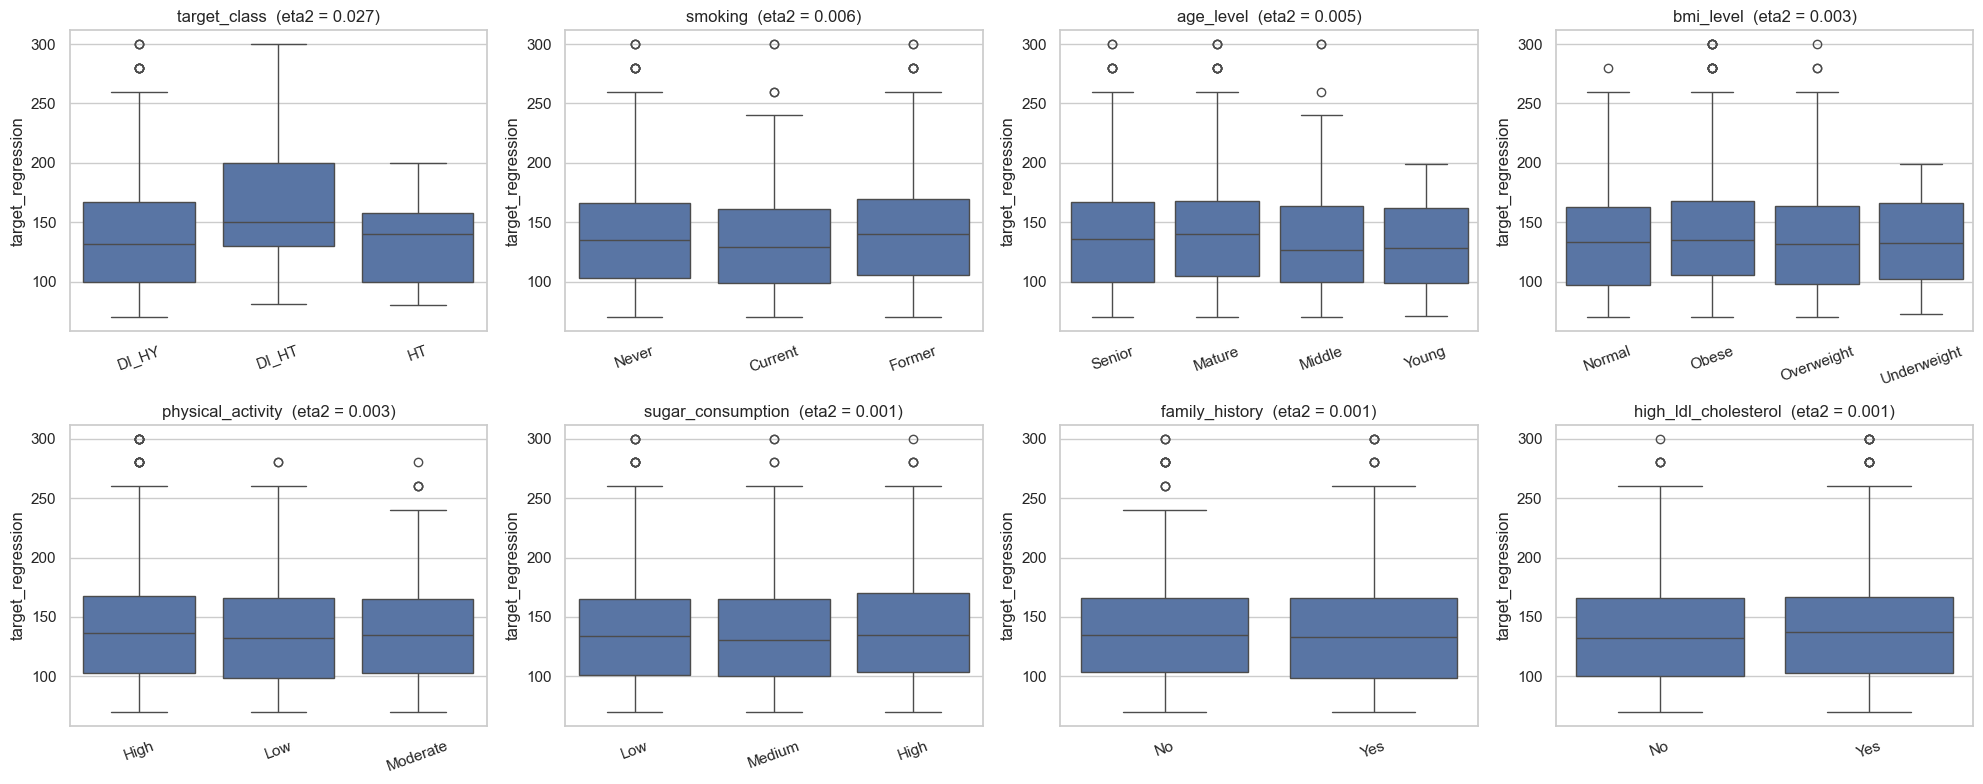

In [19]:
plot_cats = cat_reg.index[:8]
fig, axes = plt.subplots(2, 4, figsize=(20, 8)); axes = axes.ravel()
for ax, c in zip(axes, plot_cats):
    sns.boxplot(data=df, x=c, y=TARGET_REG, ax=ax)
    ax.set_title(f'{c}  (eta2 = {cat_reg.loc[c, "eta2"]:.3f})')
    ax.set_xlabel(''); ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

**Conclusões:** A variável categórica com maior efeito sobre `target_regression` é a própria
**`target_class`**, com η² = 0.027 e p ≈ 1e-12 na ANOVA. O efeito é pequeno, mas é o maior de todos, e,
por ser o alvo da outra tarefa e não um alvo desta, pode ser usada como preditor na regressão. Foi por
isso que a incluímos nesta comparação.

Todas as restantes variáveis categóricas têm **η² praticamente nulo** (≤ 0.006, sendo `smoking` a maior
delas). Algumas chegam a ter p-value abaixo de 0.05, mas sem qualquer relevância prática.

Confirma-se assim o diagnóstico da secção anterior: as *features* disponíveis não explicam praticamente
nada da variabilidade de `target_regression`.

### 3.6 Features numéricas vs `target_class`

Usamos o **teste de Kruskal-Wallis** para comparar a distribuição de cada *feature* entre as três
classes. Optamos pela versão não paramétrica porque, como vimos, as distribuições estão longe da
normalidade e as classes têm dimensões muito diferentes.

Acrescentamos o **η²** como medida de tamanho de efeito, que indica a proporção da variância de cada
*feature* explicada pela classe.

Incluímos ainda `target_regression` na lista de variáveis testadas. Sendo o alvo da outra tarefa, e não
um alvo desta, pode ser usada como preditor na classificação, pelo que interessa saber quanto o alvo
contínuo se relaciona com o alvo categórico, de forma simétrica ao que se fez na secção 3.5.

In [20]:
classes = df[TARGET_CLS].value_counts().index.tolist()
rows = []
for c in num_feats + [TARGET_REG]:
    groups = [df.loc[df[TARGET_CLS] == k, c] for k in classes]
    H, p = stats.kruskal(*groups)
    ss_b = sum(len(g) * (g.mean() - df[c].mean())**2 for g in groups)
    eta2 = ss_b / ((df[c] - df[c].mean())**2).sum()
    rows.append({'feature': c, **{f'mean_{k}': g.mean() for k, g in zip(classes, groups)},
                 'kruskal_H': H, 'p_value': p, 'eta2': eta2})
num_cls = pd.DataFrame(rows).set_index('feature')
num_cls = num_cls.sort_values('eta2', ascending=False)
num_cls_show = num_cls.copy()
num_cls_show['p_value'] = num_cls_show['p_value'].map('{:.3g}'.format)
num_cls_show

,mean_DI_HY,mean_HT,mean_DI_HT,kruskal_H,p_value,eta2
feature,,,,,,
HbA1c_level,6.936,5.374,6.979,307.152,2.01e-67,0.410
triglycerides,151.159,217.040,227.074,170.839,7.99e-38,0.105
target_regression,134.676,132.812,168.190,24.290,5.31e-06,0.027
age,54.419,63.060,60.706,23.972,6.23e-06,0.013
crp_level,7.390,7.514,6.881,2.422,0.298,0.010
blood_pressure,150.299,149.190,148.195,48.963,2.33e-11,0.009
bmi,27.623,29.051,29.987,11.401,0.00334,0.006
homocysteine_level,12.373,12.606,12.194,20.806,3.03e-05,0.004
ldl_alternative,129.270,136.217,133.376,5.109,0.0777,0.003


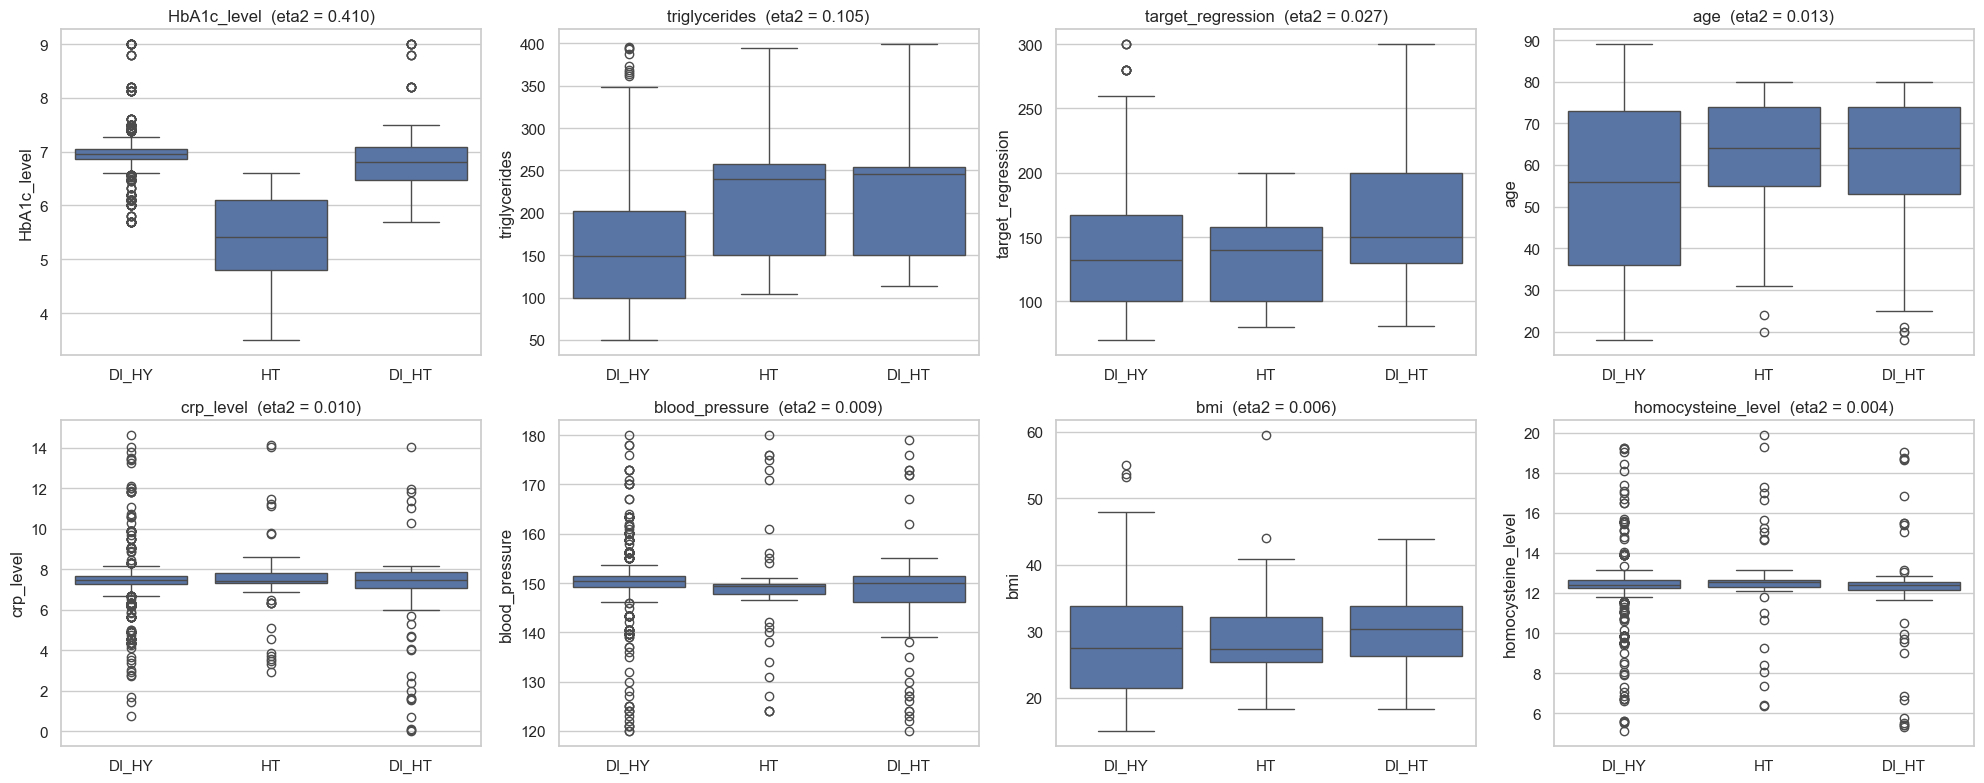

In [21]:
top_cls = num_cls.index[:8]
fig, axes = plt.subplots(2, 4, figsize=(20, 8)); axes = axes.ravel()
for ax, c in zip(axes, top_cls):
    sns.boxplot(data=df, x=TARGET_CLS, y=c, order=classes, ax=ax)
    ax.set_title(f'{c}  (eta2 = {num_cls.loc[c, "eta2"]:.3f})'); ax.set_xlabel('')
plt.tight_layout(); plt.show()

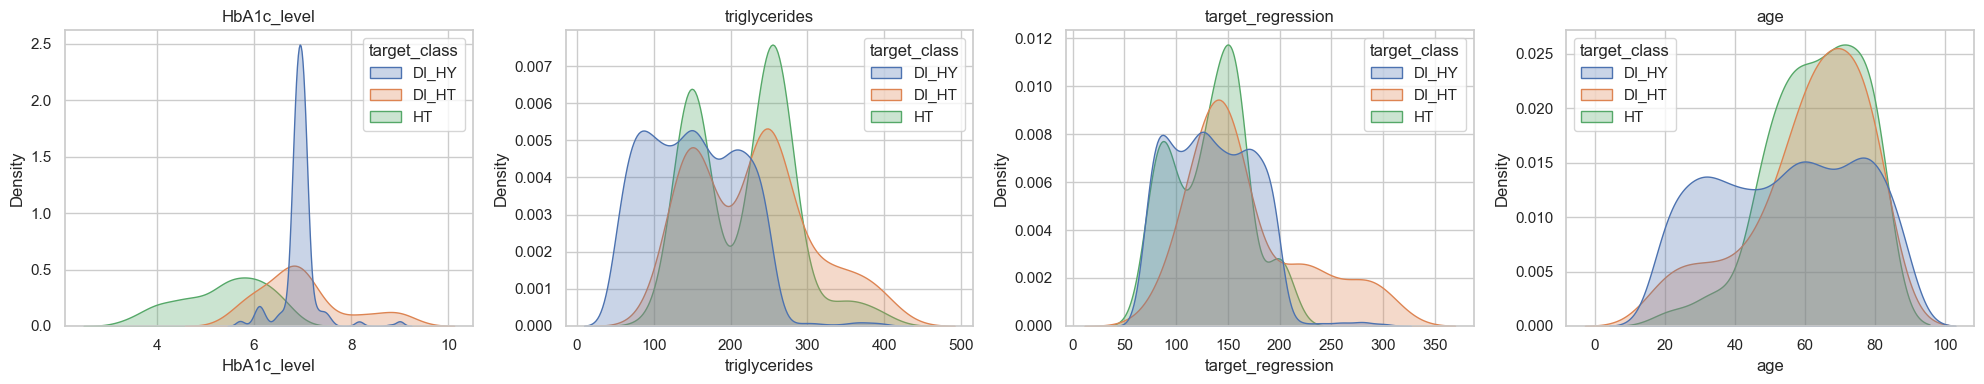

In [22]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, c in zip(axes, num_cls.index[:4]):
    sns.kdeplot(data=df, x=c, hue=TARGET_CLS, common_norm=False, fill=True, alpha=.3, ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

**Conclusões:**

Ordenadas por tamanho de efeito, destacam-se:

- **`HbA1c_level` (η² = 0.41, Kruskal-Wallis H = 307, p ≈ 2e-67)** é a *feature* mais
  discriminativa, explica cerca de **41% da variância** da sua própria distribuição entre classes. Isto faz sentido clinicamente, porque `HbA1c` é o marcador de diabetes e `HT` é a única classe sem componente diabética. É a feature que melhor separa `HT` das outras.
- **`triglycerides` (η² = 0.105, p ≈ 8e-38)**: valores substancialmente mais altos em `DI_HT` (≈ 227) e
  `HT` (≈ 217) do que em `DI_HY` (≈ 151).
- Com efeitos muito menores mas ainda estatisticamente detetáveis: `age` (η² = 0.013), `blood_pressure` (0.009), `bmi` (0.006) e `homocysteine_level` (0.004).
- **Apenas 6 das 18 *features* numéricas** apresentam diferenças significativas entre classes. As
  restantes, incluindo `systolic_bp`, `diastolic_bp`, `heart_rate`, `hdl`, `ldl`, `alcohol_intake` e
  `salt_intake`, têm distribuições praticamente idênticas nas três classes e são, do ponto de vista do
  seu valor clínico, **pouco informativas**.

- Quanto à variável alvo contínua, `target_regression` apresenta η² = 0.027, com p ≈ 5e-06. A relação
  entre os dois alvos é real mas modesta, e coincide com o valor obtido na secção 3.5, como seria de
  esperar por se tratar da mesma associação medida a partir do outro lado.

### 3.7 Features categóricas vs `target_class` (χ² e V de Cramér)

Para medir a associação entre duas variáveis categóricas usamos o **teste do qui-quadrado** sobre a
tabela de contingência, que testa a independência entre elas.

O χ² tem, porém, uma limitação conhecida, no qual o seu valor cresce com o tamanho da amostra, pelo que com
n = 2000 quase tudo acaba por ser "significativo". Para medir a **força** da associação usamos por isso
o **V de Cramér**, que normaliza o χ² para um valor entre 0 e 1 e é interpretável como medida de efeito
(valores abaixo de 0.1 correspondem, a associações fracas).

In [23]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    n = ct.values.sum(); r, k = ct.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1))), chi2, p

rows = []
for c in cat_cols:
    v, chi2, p = cramers_v(df[c], df[TARGET_CLS])
    rows.append({'feature': c, 'chi2': chi2, 'p_value': p, 'cramers_v': v})
cat_cls = pd.DataFrame(rows).set_index('feature').sort_values('cramers_v', ascending=False)
cat_cls_show = cat_cls.copy()
cat_cls_show['p_value'] = cat_cls_show['p_value'].map('{:.3g}'.format)
cat_cls_show

,chi2,p_value,cramers_v
feature,,,
low_hdl_cholesterol,31.042,1.82e-07,0.125
age_level,50.711,3.39e-09,0.113
bmi_level,46.506,2.35e-08,0.108
physical_activity,19.793,0.000549,0.070
education_level,15.257,0.0042,0.062
sugar_consumption,13.796,0.00797,0.059
employment_status,13.748,0.00814,0.059
smoking,13.380,0.00956,0.058
family_history,6.147,0.0462,0.055


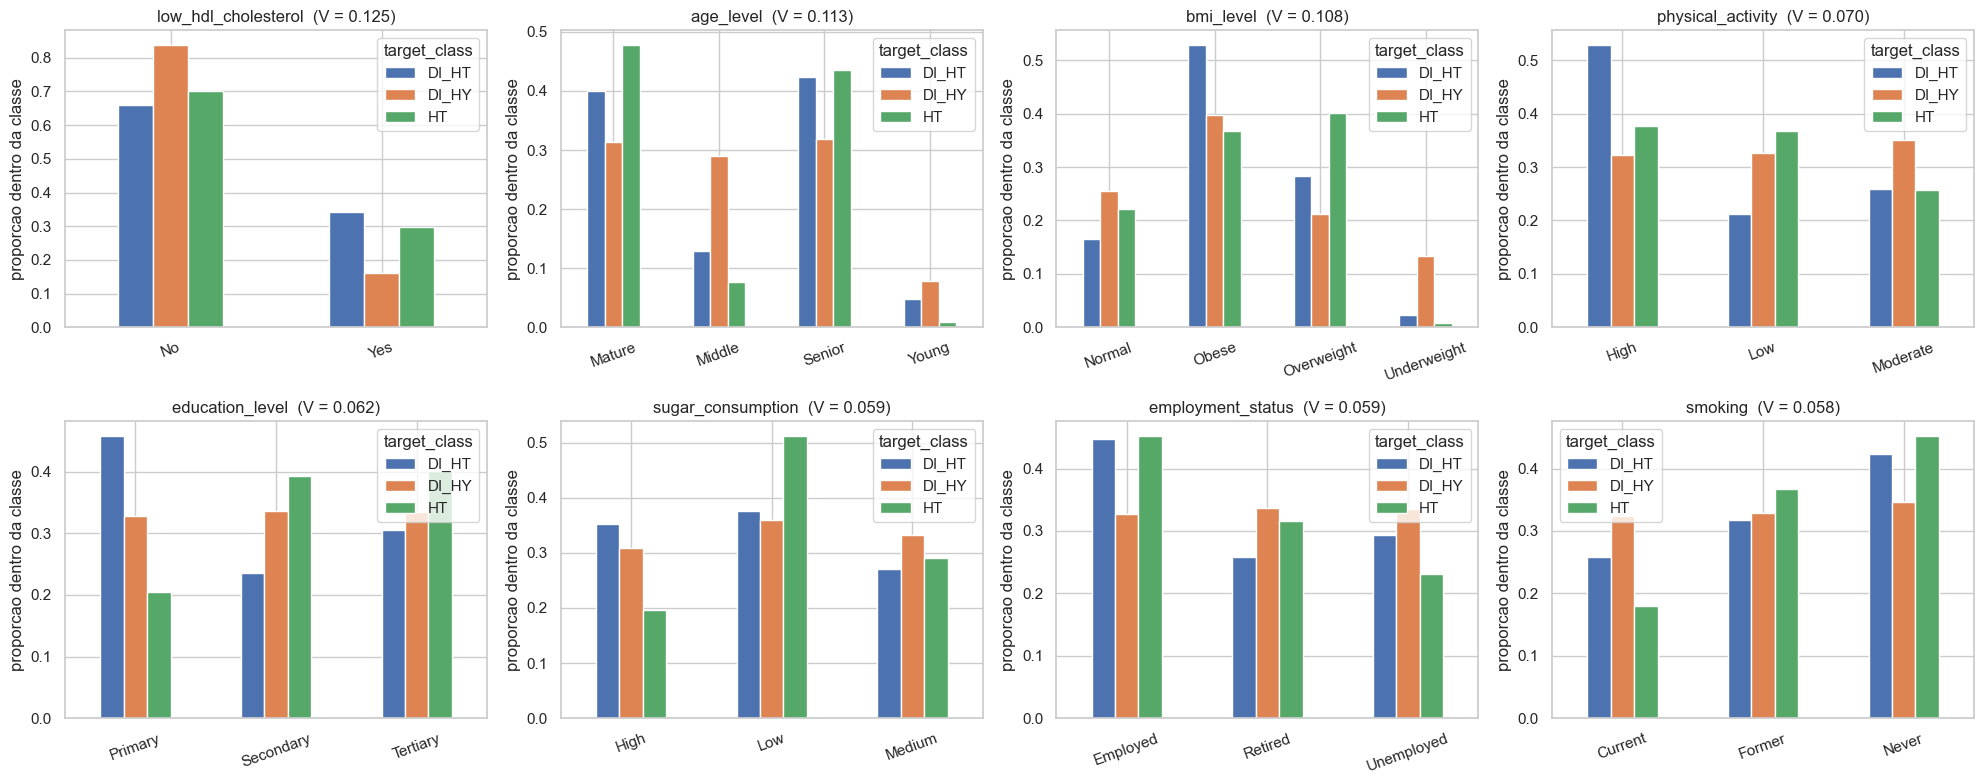

In [24]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8)); axes = axes.ravel()
for ax, c in zip(axes, cat_cls.index[:8]):
    ct = pd.crosstab(df[c], df[TARGET_CLS], normalize='columns')   # perfil de cada classe
    ct.plot.bar(ax=ax, rot=20)
    ax.set_title(f'{c}  (V = {cat_cls.loc[c, "cramers_v"]:.3f})')
    ax.set_xlabel(''); ax.set_ylabel('proporcao dentro da classe')
plt.tight_layout(); plt.show()

**Conclusões:** As associações mais fortes são as de `low_hdl_cholesterol`, `age_level` e `bmi_level`,
mas **todas são fracas em termos absolutos** (V = 0.125, 0.113 e 0.108, respetivamente). `age_level` e `bmi_level` confirmam, o efeito de `age` e `bmi` já detetado em 3.6.

**`low_hdl_cholesterol` está associada à classe, apesar de `hdl` não estar**. Uma *flag* derivada de uma variável sem
sinal não deveria, em princípio, ter sinal.

Várias variáveis, `physical_activity`, `education_level`, `smoking`, `employment_status`, têm p-value
abaixo de 0.05 mas V ≈ 0.06. Repete-se o padrão já visto, no qual com n = 2000, efeitos minúsculos tornam-se
estatisticamente significativos sem terem **relevância prática**.

Por fim, **`gender` e `stress_level` não apresentam qualquer associação** com a classe (p > 0.2). São as
duas candidatas mais claras a *features* não informativas entre as categóricas.

### 3.8 Relação entre os dois targets e pairplot das features mais relevantes

Terminamos a análise bivariada com uma visão conjunta das *features* mais promissoras. O *pairplot*
mostra, de uma só vez, a distribuição de cada variável por classe (na diagonal) e todas as relações
duas a duas (fora da diagonal), com os pontos coloridos pela classe.

O objetivo é perceber se alguma **combinação** de *features* separa as classes melhor do que qualquer
uma delas isoladamente.

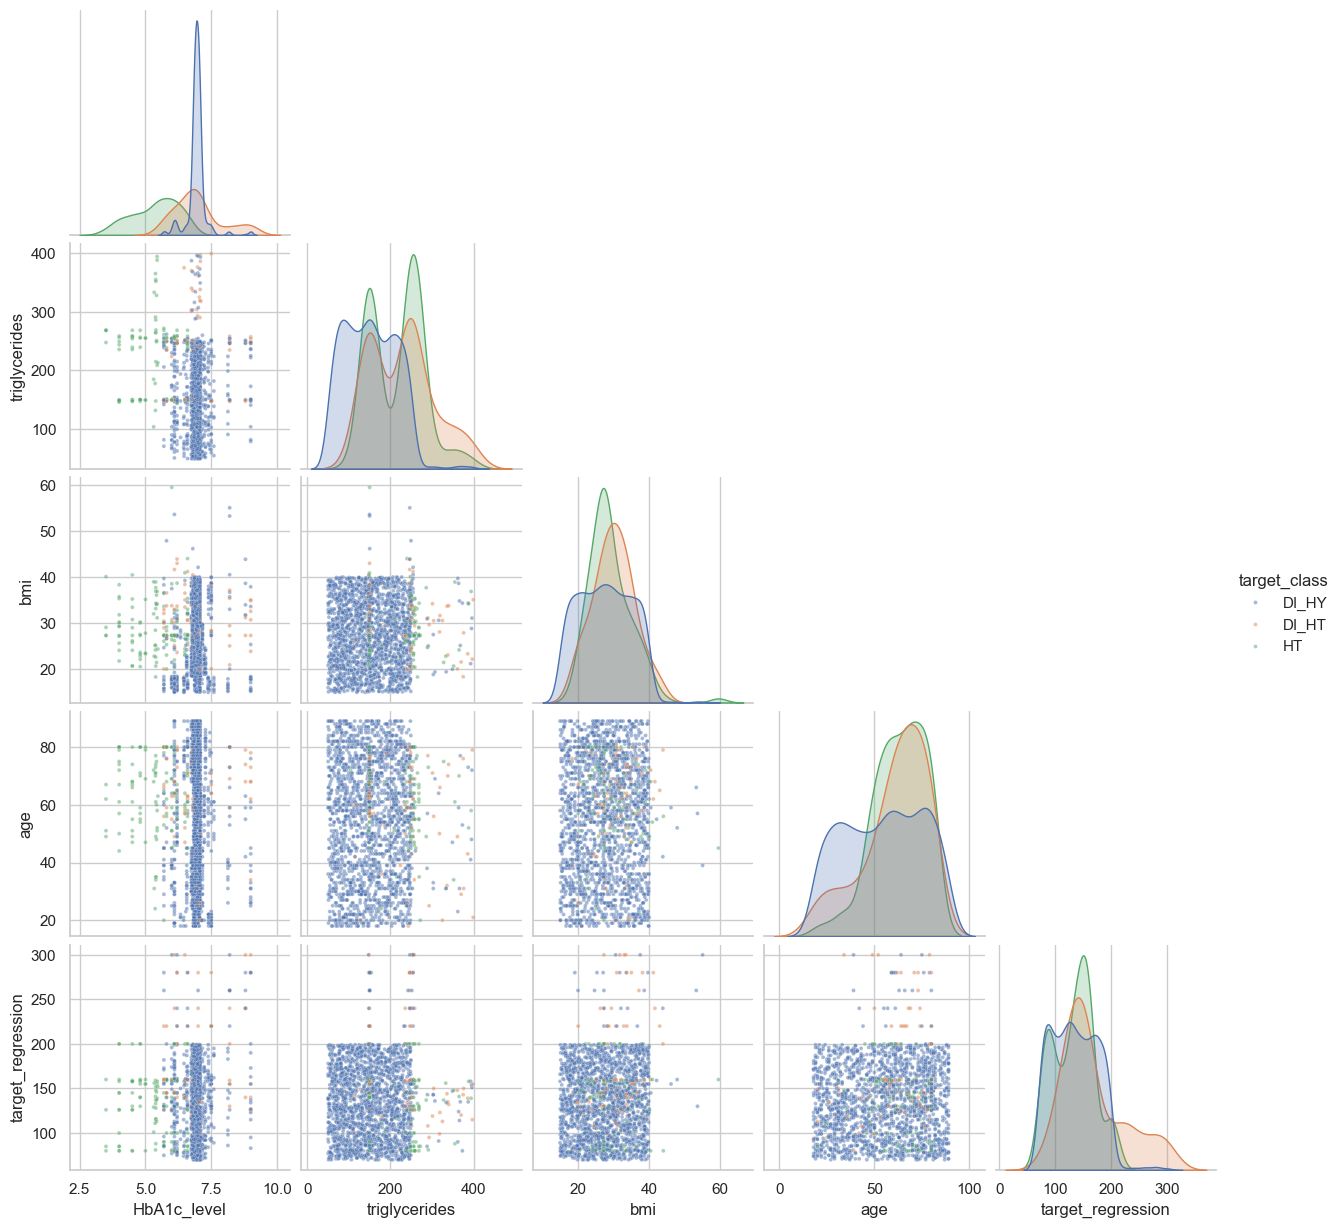

In [25]:
key = ['HbA1c_level', 'triglycerides', 'bmi', 'age', TARGET_REG]
sns.pairplot(df[key + [TARGET_CLS]], hue=TARGET_CLS, corner=True,
             plot_kws={'s': 8, 'alpha': .5}, diag_kws={'common_norm': False})
plt.show()

**Conclusões:** O *pairplot* confirma e enriquece o que já sabíamos, a *feature* **`HbA1c_level` isola bem a classe
`HT`**, formando um grupo claramente deslocado para a esquerda, e a sua **combinação com
`triglycerides`** ajuda a separar `DI_HT` e `HT` de `DI_HY`.

Permanece, contudo, uma **sobreposição considerável entre `DI_HT` e `DI_HY`**. Nenhuma combinação das
*features* mais relevantes as distingue de forma nítida. É previsível que esta seja a
distinção mais difícil para os classificadores e a principal fonte de erro. Combinando isso com o
facto de `DI_HT` ter apenas 85 registos, é de se esperar que seja esta a classe com pior *recall*.

### 3.9 Artefacto detetado: precisão decimal dos valores depende da classe
Olhando para as linhas do dataset, alguns valores são números "redondos" (`hdl = 72.0`) e outros têm muitas casas decimais (`hdl = 64.3313679245283`), o que sugere que foram imputados ou gerados sinteticamente. Vamos verificar se isto está relacionado com a classe.

In [26]:
def not_rounded(s):
    return ((s * 10).round(6) % 1 != 0)

frac = pd.DataFrame({c: df.groupby(TARGET_CLS)[c].apply(lambda s: not_rounded(s).mean())
                     for c in num_feats}).T[classes]
frac.sort_values('DI_HY')

target_class,DI_HY,HT,DI_HT
age,0.000,0.000,0.000
cholesterol,0.031,0.812,0.671
triglycerides,0.031,0.812,0.671
bmi,0.049,0.923,0.953
systolic_bp,0.053,1.000,0.941
ldl,0.056,1.000,1.000
sleep_hours,0.056,1.000,1.000
hdl,0.056,1.000,1.000
heart_rate,0.056,1.000,1.000
salt_intake,0.056,1.000,1.000


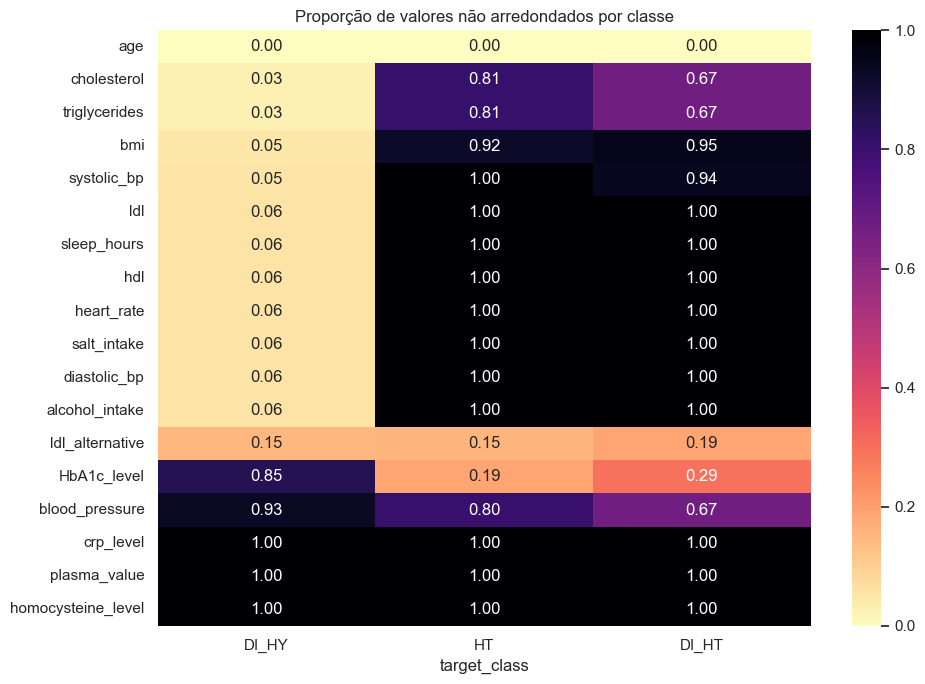

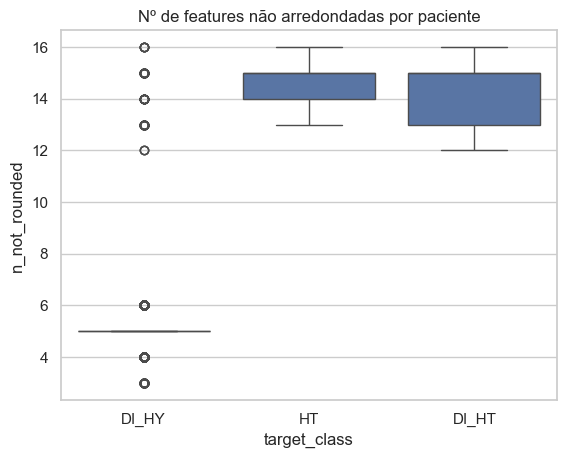

In [27]:
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(frac.sort_values('DI_HY'), annot=True, fmt='.2f', cmap='magma_r', ax=ax)
ax.set_title('Proporção de valores não arredondados por classe')
plt.tight_layout(); plt.show()

df_tmp = df.assign(n_not_rounded=sum(not_rounded(df[c]).astype(int) for c in num_feats))
sns.boxplot(data=df_tmp, x=TARGET_CLS, y='n_not_rounded', order=classes)
plt.title('Nº de features não arredondadas por paciente'); plt.show()

**Conclusões:**

Nas classes minoritárias (`HT` e `DI_HT`),
praticamente **100%** dos valores de `hdl`, `heart_rate`, `alcohol_intake`, `ldl`, `systolic_bp` e `bmi`
têm muitas casas decimais. Na classe maioritária `DI_HY`, apenas cerca de **5%** estão nessa situação.
Com `HbA1c_level` acontece exatamente o inverso.

Isto significa que os registos das classes minoritárias foram **gerados ou imputados por um processo
diferente** do usado na classe maioritária.

**Implicações, por ordem de importância:**

1. Um modelo flexível pode aprender a classe a partir da **"forma" do número** e não do seu valor clínico. Isto é *data leakage* e leva a um desempenho otimista que não generalizaria para dados reais.
2. Os modelos lineares usam o **valor** das variáveis e não a sua representação decimal, pelo que são pouco afetados. Mesmo assim, **não devemos criar features derivadas da precisão**.
3. Para avaliar relevância usamos os testes de Kruskal-Wallis com η², o χ² com V de Cramér e as correlações, que medem diferenças no valor das variáveis e não na forma como estão escritas.

## 4. Síntese e preparação para as fases seguintes

### 4.1 Quadro-resumo das features

Reunimos numa única tabela as medidas de associação calculadas ao longo da análise bivariada, para
sustentar com números as decisões que se seguem.

In [28]:
summary = pd.DataFrame(index=num_feats + cat_cols)
summary['|r| target_reg'] = rel_reg['pearson'].abs()
summary['eta2 target_reg (cat)'] = cat_reg['eta2']
summary['eta2 target_class'] = num_cls['eta2']
summary['CramersV target_class'] = cat_cls['cramers_v']
summary['p target_class'] = num_cls['p_value'].combine_first(cat_cls['p_value'])
summary.sort_values('p target_class')

,|r| target_reg,eta2 target_reg (cat),eta2 target_class,CramersV target_class,p target_class
HbA1c_level,0.055,NaN,0.410,NaN,0.000
triglycerides,0.037,NaN,0.105,NaN,0.000
blood_pressure,0.015,NaN,0.009,NaN,0.000
age_level,NaN,0.005,NaN,0.113,0.000
bmi_level,NaN,0.003,NaN,0.108,0.000
low_hdl_cholesterol,NaN,0.001,NaN,0.125,0.000
age,0.054,NaN,0.013,NaN,0.000
homocysteine_level,0.016,NaN,0.004,NaN,0.000
physical_activity,NaN,0.003,NaN,0.070,0.001
bmi,0.070,NaN,0.006,NaN,0.003


### 4.2 Features constantes, redundantes e pouco informativas

| Tipo | Feature(s) | Justificação (com evidência) | Ação proposta |
|---|---|---|---|
| **Constante** | `calcium_baseline` | Valor único (9.42) em 2000 registos; desvio-padrão exatamente 0 (secção 1.3) | **Remover** |
| **Redundante** | `systolic_index` | Idêntica a `systolic_bp` em todas as 2000 linhas. Com ambas presentes, a matriz de correlação fica singular e o número de condição atinge 1.75e+15 (secção 3.2) | **Remover**, manter `systolic_bp` |
| **Redundante** | `age_normalized` | Reescala determinística de `age`: (age − 2)/87, resíduo máximo 1e-06 | **Remover**, manter `age` |
| **Sem ligação ao paciente** | `ldl_alternative` | Tem os mesmos valores de `ldl` mas permutados, coincidindo em apenas 18 de 2000 linhas (3.2). Não apresenta qualquer relação com `high_ldl_cholesterol`, a *flag* construída a partir do perfil lipídico do paciente: médias de 129.7 e 130.0 | **Remover** |
| **Parcialmente redundante** | `age_level`, `bmi_level`, `low_hdl_cholesterol`, `high_ldl_cholesterol` | Discretizações de `age`, `bmi`, `hdl`, `ldl`. As duas *flags* não correspondem aos limiares clínicos habituais | Preferir a variável contínua; **testar na seleção de *features*** |
| **Pouco informativas** | `systolic_bp`, `diastolic_bp`, `heart_rate`, `hdl`, `ldl`, `alcohol_intake`, `salt_intake`, `sleep_hours`, `cholesterol`, `plasma_value`, `crp_level`; e as categóricas `gender` e `stress_level` | Distribuições idênticas entre classes (Kruskal-Wallis não significativo, η² ≈ 0) ou sem associação (V de Cramér, p > 0.2); correlação ≈ 0 com `target_regression` | **Manter nesta fase**; a decisão pertence à seleção de *features* |
| **Informativas** | `HbA1c_level`, `triglycerides`, `bmi`/`bmi_level`, `age`/`age_level` | Diferenças claras entre classes: η² = 0.41 e 0.105 nas duas primeiras, com p ≈ 2e-67 e 8e-38 | **Manter** |

**Critério adotado.** Removem-se apenas as quatro variáveis para as quais existe uma razão
demonstrada e independente do desempenho de qualquer modelo: `calcium_baseline`, por ser constante,
`systolic_index` e `age_normalized`, por serem reproduções exatas de outras colunas, e
`ldl_alternative`, por se ter demonstrado que os seus valores não pertencem ao registo em que
aparecem.

As restantes são mantidas. É certo que muitas apresentam associações fracas com ambos os alvos, mas as
diferenças entre elas são pequenas e eliminá-las nesta fase seria decidir com base na força da
associação observada na totalidade dos dados, o que constitui uma forma de seleção enviesada. **Essa
decisão pertence à fase de seleção de *features***, onde pode ser tomada com validação cruzada e
confrontada com o desempenho obtido.

Repare-se que `ldl_alternative` apresenta, aliás, uma associação ligeiramente **superior** à de `ldl`,
com η² de 0.0031 contra 0.00002 na classificação. Este é precisamente o argumento para não selecionar
variáveis apenas por essa via: uma coluna que se demonstrou estar desligada do paciente consegue, por
acaso, parecer mais útil do que a coluna legítima de que deriva.

### 4.3 Conclusões gerais da EDA

1. **Qualidade dos dados.** Não há valores em falta nem registos duplicados. Existem *outliers* pela
   regra do IQR, mas resultam da forma concentrada de algumas distribuições e são informativos - não
   foram removidos.
2. **Desequilíbrio severo.** `target_class` tem 89.9% dos registos numa única classe. Obriga a
   estratificação e a métricas robustas; a *accuracy* isolada seria enganadora.
3. **Regressão: sinal muito fraco.** Nenhuma *feature* numérica atinge |r| = 0.07 com
   `target_regression`, e as correlações de Spearman acompanham as de Pearson, o que exclui relações
   monótonas não lineares escondidas. É de esperar R² baixo. Detetou-se ainda acumulação de observações nos extremos (70 e 300),
   compatível com truncatura.
4. **Classificação: sinal claro, mas concentrado.** `HbA1c_level` (η² = 0.41) e `triglycerides`
   (η² = 0.105) separam as classes de forma estatisticamente forte; apenas **6 das 18** *features*
   numéricas do conjunto de trabalho têm efeito significativo.
5. **Sem multicolinearidade.** Removidas as redundâncias, o número de condição cai de 1.75e+15 para
   1.29 e todos os VIF ficam abaixo de 1.05, com o máximo em 1.0441 (secção 3.2).
6. **Artefacto de precisão decimal.** A forma dos números depende da classe, o que constitui potencial
   *leakage* e obriga a avaliar a relevância das variáveis pelo seu valor e não pela sua representação.
7. **Fortes indícios de dados sintéticos**: distribuições uniformes, correlações nulas entre variáveis
   clinicamente relacionadas, e o artefacto da secção 3.9.
8. **Quatro variáveis removidas**, por razões demonstradas: `calcium_baseline`, `systolic_index`,
   `age_normalized` e `ldl_alternative`.

### 4.4 Implicações para a Parte 2 - Regressão

- O **modelo linear simples** deverá usar o melhor preditor individual, que pela análise de 3.4 é `bmi`
  (|r| ≈ 0.070), seguido de `salt_intake` e `HbA1c_level`. Deve testar-se mais do que um e comparar.
- A `target_class` é o alvo da outra tarefa e não desta, pelo que **pode entrar como preditor na
  regressão**. É a variável categórica com maior efeito sobre `target_regression` (η² = 0.027, secção
  3.5), pelo que vale a pena testar a sua inclusão, sob a forma de indicadores binários, na regressão
  múltipla.
- Na **regressão múltipla**, a ausência de colinearidade entre as *features* retidas, observada na
  matriz de correlação da secção 3.1, significa que os coeficientes serão estáveis e interpretáveis,
  ainda que pequenos.
- Esperam-se **R² próximos de zero**. A discussão deve centrar-se em porquê - ausência de sinal nas
  *features*, possível truncatura do alvo - e não em tentar inflacionar a métrica.
- Avaliação com **R², MAE e RMSE**, como pedido, sobre um *holdout* fixado com semente 22.

### 4.5 Implicações para a Parte 3 - Classificação

- **Métricas**: F1 macro, *balanced accuracy*, *recall* por classe e matriz de confusão. A *accuracy*
  deve ser reportada, mas como métrica secundária, dado o *baseline* trivial de 89.9%.
- **Reamostragem estratificada** em todos os esquemas (*holdout*, k = 5, k = 10), para garantir que as
  85 observações de `DI_HT` estão representadas em cada *fold*.
- **LOOCV** é viável (2000 ajustes) mas computacionalmente pesado; convém medir o tempo. Espera-se que
  produza estimativas com **variância mais elevada** do que a validação cruzada em k *folds*, conforme
  discutido nas aulas.
- Prever que a classe **`DI_HT` terá o pior *recall***, pela sobreposição com `DI_HY` observada na
  secção 3.8. A verificação dos pressupostos de cada método de classificação pertence a essa parte do
  trabalho e não à análise exploratória.

---

# Da Parte 1 para a Parte 2

A análise exploratória deixou a tarefa de regressão num ponto desconfortável, e é importante entrar na
Parte 2 com essa expectativa explícita, para não se confundir um mau resultado com um erro de método.

| O que a Parte 1 estabeleceu | O que a Parte 2 vai fazer com isso |
|---|---|
| Nenhuma *feature* ultrapassa **\|r\| = 0.07** com `target_regression`, sendo `bmi` a maior (secção 3.4) | Define o limite teórico da regressão simples: como R² = r², o melhor possível ronda **0.5%** da variância |
| As correlações de Spearman acompanham as de Pearson | Exclui relações monótonas não lineares, e justifica testar polinómios apenas por confirmação |
| As variáveis retidas são praticamente independentes entre si, com VIF abaixo de 1.05 (secção 3.2) | Os coeficientes da regressão múltipla serão estáveis, e os R² individuais tendem a somar-se |
| Quatro colunas removidas por razões demonstradas | A Parte 2 parte do mesmo conjunto, sem repetir a justificação |
| O alvo acumula observações nos extremos 70 e 300 | Levanta a hipótese de truncatura, retomada na secção 8.4 |

A pergunta da Parte 2 não é, portanto, "qual o melhor modelo", mas **"existe sinal suficiente para
algum modelo linear ser útil?"**. A resposta honesta a essa pergunta vale mais do que uma métrica
inflacionada.

# Parte 2: Aplicação de métodos - Regressão Linear

**Dataset:** `dataset_grupo_22.csv` - 2000 perfis de pacientes. **Variável a prever:** `target_regression`

### Objetivo
1. **Regressão Linear Simples:** ajustar um modelo com uma só feature, testar várias features e escolher a mais
   adequada.
2. **Regressão Linear Múltipla:** ajustar um modelo com várias features clínicas, experimentar combinações e
   determinar o melhor grupo.
3. **Comparação e discussão:** avaliar os dois modelos com R², MAE e RMSE e discutir os resultados.

### Ponto de partida: o que a EDA já nos disse
A análise exploratória (`01_EDA.ipynb`) deixou três indicações que orientam tudo o que se segue:

| Resultado da EDA | Consequência para a regressão |
|---|---|
| A correlação mais alta com o target é a do `bmi` (r ≈ 0.07). Todas as outras são ainda mais próximas de 0. | Na regressão simples, R² = r². Mesmo a melhor feature explicará **menos de 1%** da variância. **Não esperamos um bom modelo.** |
| As features são praticamente independentes entre si, exceto pares contínua/discretizada (`age`/`age_level`, `bmi`/`bmi_level`). | Juntar features pode acumular pequenos contributos, mas só faz sentido usar **uma versão** de cada variável. |
| `calcium_baseline` é constante; `systolic_index` e `age_normalized` são cópias de outras features; `ldl_alternative` tem os valores de `ldl` trocados entre pacientes (não pertence ao paciente da linha). | São removidas antes de modelar. |

O objetivo desta parte é, por isso, **testar de forma rigorosa** se alguma feature ou combinação consegue prever
o target melhor do que um modelo sem informação, e **explicar porquê** umas combinações funcionam melhor que
outras.

### Base teórica
- Regressão simples: $Y = \beta_0 + \beta_1 X + \varepsilon$. Múltipla: $Y = \beta_0 + \beta_1 X_1 + \dots + \beta_p X_p + \varepsilon$.
- Coeficientes estimados por **mínimos quadrados**, minimizando $RSS = \sum (y_i - \hat y_i)^2$.
- $R^2 = 1 - RSS/TSS$: proporção da variância explicada. Testes *t* (cada coeficiente) e *F* (modelo global)
  avaliam a significância estatística.
- Problemas a vigiar: não-linearidade, variância não constante, *outliers*, **colinearidade**.

### Decisões de método
| Decisão | Porquê |
|---|---|
| *Holdout* 70% treino / 30% teste, seed 22 | Permitido pelo enunciado; proporção do exemplo Boston Housing; seed definida nas regras do projeto. |
| Escolhas feitas **só no treino**, com validação cruzada 5-fold | Escolher a melhor combinação olhando para o teste tornaria o erro do teste otimista. |
| Teste usado **uma única vez** (secção 8) | Estimativa honesta do erro em pacientes novos. |
| Comparação sempre com uma ***baseline*** (prever a média) | Um R² ou um RMSE só têm significado comparados com "não usar nenhuma feature". |
| `target_class` **não** é preditor | É o outro target do trabalho (regra do projeto). |

## 5. Preparação dos dados

### 5.1 Carregamento dos dados e preparação do ambiente

Carregamos as bibliotecas e o dataset original. O ficheiro CSV **nunca é alterado**: todas as transformações
são feitas numa cópia em memória.

Fixamos a semente aleatória em **22**. Assim, a divisão treino/teste e a
validação cruzada dão sempre os mesmos resultados, e qualquer membro do grupo pode reproduzir o notebook.

Usamos duas bibliotecas de regressão, como nas aulas:
- **scikit-learn** (`LinearRegression`), para treinar, prever e validar;
- **statsmodels** (`OLS`), para obter a tabela estatística (erros padrão, testes *t* e *F*, p-values)

In [29]:
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split, KFold
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

SEED = 22
np.random.seed(SEED)
pd.set_option('display.float_format', '{:.4f}'.format)
pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid')

dataset_name = 'dataset_grupo_22.csv'
candidates = [Path.cwd() / dataset_name, Path.cwd().parent / dataset_name]
dataset_path = next(p for p in candidates if p.is_file())
raw = pd.read_csv(dataset_path)
print('Dimensao do dataset:', raw.shape)
raw[['age', 'bmi', 'HbA1c_level', 'smoking', 'employment_status', 'target_regression']].head()

Dimensao do dataset: (2000, 35)


,age,bmi,HbA1c_level,smoking,employment_status,target_regression
0,87,23.6000,7.0800,Never,Retired,90.0000
1,56,36.7000,8.2000,Never,Unemployed,220.0000
2,67,39.8000,6.8618,Current,Employed,172.0000
3,39,21.4000,6.9000,Current,Employed,92.0000
4,74,23.0000,7.0800,Never,Retired,152.0000


**Conclusões:** o dataset tem **2000 linhas e 35 colunas**, como na EDA. Há features numéricas (`age`, `bmi`,
`HbA1c_level`), categóricas em texto (`smoking`, `employment_status`) e o target, que varia entre valores como 90
e 220 nas primeiras linhas.

### 5.2 Remoção de features e codificação das categóricas

**O que fazemos e porquê:**

1. **Removemos as 4 features que a EDA (`01_EDA`) decidiu remover:**
   - `calcium_baseline`: é constante (9.42 em todas as linhas). Uma variável que não varia não consegue explicar
     a variação do target. Além disso, numa regressão ficaria colinear com o intercepto β₀.
   - `systolic_index`: é uma cópia exata de `systolic_bp`. Com as duas no modelo, a matriz $X^TX$ fica singular e
     $\hat\beta = (X^TX)^{-1}X^Ty$ deixa de ter solução única.
   - `age_normalized`: é uma reescala de `age`, com o mesmo problema;
   - `ldl_alternative`: tem os mesmos valores de `ldl`, mas trocados entre pacientes (coincide em só 18 de 2000
     linhas). O valor não pertence ao paciente da linha, por isso é ruído e não deve entrar no modelo.

2. **Convertemos as categóricas em números**, porque a regressão linear só trabalha com valores numéricos:
   - **ordinais** (têm uma ordem natural, ex.: Low < Medium < High) → códigos 0, 1, 2…, que preservam a ordem
     com uma única coluna;
   - **binárias** (Yes/No, Male/Female) → 0/1;
   - **nominais** sem ordem (`employment_status`) → *one-hot* com `drop_first=True`, tal como `pd.get_dummies` no
     exercício PL2 (Insurance). Se não retirássemos uma coluna, as *dummies* somariam sempre 1 e ficariam
     colineares com o intercepto ("armadilha das *dummies*").

3. **Retiramos os dois targets da matriz de preditores.** `target_class` é o outro resultado a prever no trabalho;
   usá-lo para prever `target_regression` seria usar um resultado para prever outro.

As features "pouco informativas" da EDA **não** são removidas aqui. A ideia desta parte é precisamente testá-las
e deixar que os resultados confirmem (ou não) o que a EDA sugeriu.

In [30]:
TARGET = 'target_regression'
DROP_EDA = ['calcium_baseline', 'systolic_index', 'age_normalized', 'ldl_alternative']

ORDINAL = {
    'age_level':         ['Young', 'Middle', 'Mature', 'Senior'],
    'bmi_level':         ['Underweight', 'Normal', 'Overweight', 'Obese'],
    'smoking':           ['Never', 'Former', 'Current'],
    'physical_activity': ['Low', 'Moderate', 'High'],
    'stress_level':      ['Low', 'Medium', 'High'],
    'sugar_consumption': ['Low', 'Medium', 'High'],
    'education_level':   ['Primary', 'Secondary', 'Tertiary'],
}
BINARY = {'gender': 'Male', 'family_history': 'Yes', 'low_hdl_cholesterol': 'Yes', 'high_ldl_cholesterol': 'Yes'}

data = raw.drop(columns=DROP_EDA).copy()
for col, levels in ORDINAL.items():
    data[col] = data[col].map({lvl: i for i, lvl in enumerate(levels)})
for col, positive in BINARY.items():
    data[col] = (data[col] == positive).astype(int)
data = pd.get_dummies(data, columns=['employment_status'], drop_first=True, dtype=int)

X = data.drop(columns=[TARGET, 'target_class'])
y = data[TARGET]
assert X.isna().sum().sum() == 0, 'codificacao gerou valores em falta'
FEATURES = list(X.columns)
CONTINUOUS = [c for c in FEATURES if c in raw.columns and pd.api.types.is_numeric_dtype(raw[c])]
print(f'{len(FEATURES)} features candidatas ({len(CONTINUOUS)} numericas continuas):')
print(FEATURES)

30 features candidatas (17 numericas continuas):
['age_level', 'gender', 'bmi_level', 'smoking', 'age', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'blood_pressure', 'sugar_consumption', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'education_level', 'plasma_value', 'employment_status_Retired', 'employment_status_Unemployed']


**Conclusões:** ficam **30 features candidatas** (35 colunas − 4 removidas − 2 targets), das quais 17 são
numéricas contínuas e 13 vêm de categóricas codificadas. `employment_status` deu origem a 2 colunas
(`Retired` e `Unemployed`; `Employed` é a categoria de referência, representada por 0 nas duas). A codificação não
gerou valores em falta.

### 5.3 Divisão em treino e teste (*holdout*)

O enunciado permite avaliar com o método *holdout*: separar os dados em treino e teste.
- O modelo **aprende** os coeficientes β apenas com o conjunto de **treino**.
- O conjunto de **teste** simula "pacientes novos" e mede a capacidade de **generalização**.

Usamos **70% / 30%**, ficando 1400 registos para treinar,
o que é suficiente para estimar poucos coeficientes, e 600 para testar, o que dá uma estimativa razoável do erro.

**Regra importante:** todas as escolhas (que feature, que combinação) são feitas **só com o treino**. O teste é
usado uma única vez, no fim (secção 8). Se escolhêssemos a combinação que dá menos erro no teste, o próprio teste
passaria a fazer parte da escolha, e o erro reportado seria otimista.

Verificamos também se o target tem distribuição semelhante nos dois conjuntos. Se não tivesse, o teste não seria
representativo.

treino: (1400, 30) | teste: (600, 30)
           count     mean     std     min      25%      50%      75%      max
treino 1400.0000 136.9237 41.3707 70.0000 103.0000 135.0000 167.0000 300.0000
teste   600.0000 133.8167 40.9325 70.0000  97.0000 131.0000 164.0000 300.0000

Teste de Kolmogorov-Smirnov (mesma distribuicao?): p = 0.288


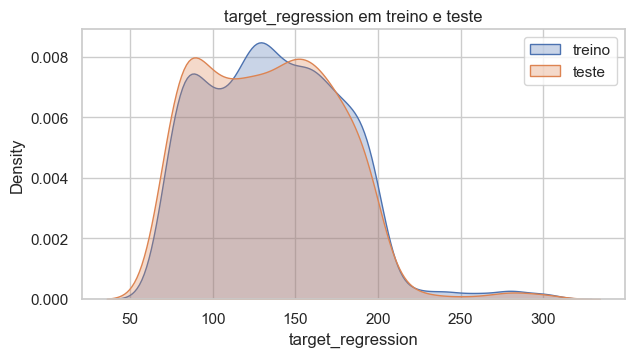

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=SEED)
print('treino:', X_train.shape, '| teste:', X_test.shape)
print(pd.DataFrame({'treino': y_train.describe(), 'teste': y_test.describe()}).T)
print(f'\nTeste de Kolmogorov-Smirnov (mesma distribuicao?): p = {stats.ks_2samp(y_train, y_test).pvalue:.3f}')

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.kdeplot(y_train, ax=ax, label='treino', fill=True, alpha=.3)
sns.kdeplot(y_test, ax=ax, label='teste', fill=True, alpha=.3)
ax.set_title('target_regression em treino e teste'); ax.legend(); plt.show()

**Conclusões:** o treino tem **1400** registos e o teste **600**. As distribuições do target são semelhantes nos
dois conjuntos:
- médias de 136.9 e 133.8, desvios padrão de 41.4 e 40.9, e o mesmo intervalo (70–300);
- o teste de Kolmogorov-Smirnov não encontra diferença (p = 0.288).

**Justificação:** a divisão aleatória produziu um teste representativo. As diferenças que encontrarmos entre
treino e teste serão do modelo, não de uma divisão desequilibrada.

### 5.4 Métricas de avaliação, validação cruzada e modelo de referência (*baseline*)


| Métrica | Fórmula | O que diz |
|---|---|---|
| **R²** | $1 - RSS/TSS$ | Proporção da variância do target explicada pelo modelo. 1 = perfeito; **0 = tão bom como prever sempre a média**; negativo = pior que a média. |
| **MAE** | $\frac{1}{n}\sum \lvert y_i - \hat y_i \rvert$ | Erro médio absoluto, nas unidades do target. Fácil de interpretar e pouco sensível a erros grandes isolados. |
| **RMSE** | $\sqrt{\frac{1}{n}\sum (y_i - \hat y_i)^2}$ | Raiz do erro quadrático médio, também nas unidades do target. Penaliza mais os erros grandes, porque eleva-os ao quadrado. |

**Porquê validação cruzada (5-fold) dentro do treino?** Para escolher entre features/combinações precisamos de
medir o erro em dados que o modelo não viu, mas sem tocar no teste. A validação cruzada divide o treino em 5
partes: treina com 4, avalia na 5.ª, e repete 5 vezes. A média das 5 avaliações é mais estável do que uma única
divisão.

**Porquê uma *baseline*?** Um modelo sem nenhuma feature prevê sempre a média do treino. Um R² ou um RMSE só têm
significado comparados com isto: **se um modelo não erra menos que a média, as features não acrescentam
informação.** É o equivalente, na regressão, a um classificador que prevê sempre a classe maioritária.

A padronização (`StandardScaler`) não altera as previsões de uma regressão linear, apenas a escala dos
coeficientes. Incluímo-la para os coeficientes serem comparáveis entre si e para preparar a Parte 4 (Ridge/Lasso),
onde é obrigatória.

In [32]:
CV = KFold(n_splits=5, shuffle=True, random_state=SEED)

def ajustar_linear(X_tr, y_tr, grau=1, log_alvo=False):
    """Padroniza e ajusta a regressao linear. Devolve a funcao que preve para novos dados.
    Escrito a mao para a padronizacao ficar dentro de cada particao da validacao cruzada."""
    poli = PolynomialFeatures(grau, include_bias=False) if grau > 1 else None
    A = poli.fit_transform(X_tr) if poli is not None else np.asarray(X_tr, dtype=float)
    escala = StandardScaler().fit(A)
    modelo = LinearRegression().fit(escala.transform(A), np.log1p(y_tr) if log_alvo else y_tr)

    def prever(X_novo):
        B = poli.transform(X_novo) if poli is not None else np.asarray(X_novo, dtype=float)
        p = modelo.predict(escala.transform(B))
        return np.expm1(p) if log_alvo else p
    return prever

def prever_media(y_tr):
    """Baseline: preve sempre a media do conjunto de treino."""
    media = float(y_tr.mean())
    return lambda X_novo: np.full(len(X_novo), media)

def metrics(y_true, y_pred):
    return {'R2': r2_score(y_true, y_pred), 'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred))}

def cv_scores(cols, grau=1, log_alvo=False, baseline=False, Xd=None, yd=None):
    """Validacao cruzada manual em 5 particoes: ajusta dentro de cada particao de treino
    e avalia na que ficou de fora."""
    Xd = X_train if Xd is None else Xd
    yd = y_train if yd is None else yd
    r2_treino, r2_val, mae_val, rmse_val = [], [], [], []
    for idx_treino, idx_validacao in CV.split(Xd):
        X_a, X_b = Xd[cols].iloc[idx_treino], Xd[cols].iloc[idx_validacao]
        y_a, y_b = yd.iloc[idx_treino], yd.iloc[idx_validacao]
        prever = prever_media(y_a) if baseline else ajustar_linear(X_a, y_a, grau, log_alvo)
        r2_treino.append(r2_score(y_a, prever(X_a)))
        p = prever(X_b)
        r2_val.append(r2_score(y_b, p))
        mae_val.append(mean_absolute_error(y_b, p))
        rmse_val.append(np.sqrt(mean_squared_error(y_b, p)))
    return {'train_r2': float(np.mean(r2_treino)), 'cv_r2': float(np.mean(r2_val)),
            'cv_r2_std': float(np.std(r2_val)), 'cv_mae': float(np.mean(mae_val)),
            'cv_rmse': float(np.mean(rmse_val))}

baseline_cv = cv_scores(FEATURES, baseline=True)
print(f'Desvio padrao do target no treino: {y_train.std():.3f}')
pd.Series(baseline_cv, name='baseline (media)').to_frame().T

Desvio padrao do target no treino: 41.371


,train_r2,cv_r2,cv_r2_std,cv_mae,cv_rmse
baseline (media),0.0000,-0.0059,0.0037,33.9541,41.3848


**Conclusões:** a *baseline* erra, em média, **34.0 unidades (MAE)**, com RMSE de **41.4**. Este RMSE é
praticamente igual ao desvio padrão do target (41.37), o que é esperado: prever sempre a média produz um erro
igual à dispersão natural dos dados.

**Este é o valor a bater.** Uma feature só é útil se fizer o RMSE descer claramente abaixo de 41.4.

**Nota sobre o R² da baseline:** em validação cruzada não é exatamente 0, mas −0.006. Em cada fold a média é
calculada com os dados de treino desse fold e avaliada noutros dados, onde a média real é ligeiramente diferente.
Por isso, ao longo do notebook, **comparamos os modelos com a baseline (−0.006) e não com o zero.**

## 6. Regressão Linear Simples

$$\hat y = \hat\beta_0 + \hat\beta_1 x$$

Uma só feature tenta explicar o target. Os coeficientes são escolhidos por **mínimos quadrados**, isto é, de
forma a minimizar $RSS = \sum (y_i - \hat y_i)^2$.

**Estratégia:**
1. Calcular, a partir da EDA, **qual é o melhor R² possível** (6.1).
2. Testar **todas** as features, uma a uma (6.2).
3. Comparar com uma **feature aleatória**, para saber se as melhores são diferentes de ruído (6.3).
4. Analisar em detalhe o modelo escolhido, com visualizações e resíduos (6.4–6.6).
5. Verificar se uma relação **não-linear** (polinómio) seria melhor (6.7).

### 6.1 O que esperar? O limite que a EDA já nos dá

Na regressão linear simples há uma relação direta entre a correlação de Pearson e o R²:

$$R^2_{\text{treino}} = r^2$$

Ou seja, **a correlação calculada na EDA diz-nos, antes de treinar qualquer modelo, qual é o R² máximo**
que cada feature pode atingir no treino. Na EDA, a correlação mais alta com o target foi a do `bmi` (r ≈ 0.07).
Calculamos r e r² para todas as features no conjunto de treino.

In [33]:
r_train = X_train.corrwith(y_train)
expected = pd.DataFrame({'r (treino)': r_train, 'r2 = R2 maximo esperado': r_train ** 2,
                         '% variancia explicada': r_train ** 2 * 100})
expected.sort_values('r2 = R2 maximo esperado', ascending=False).head(10)

,r (treino),r2 = R2 maximo esperado,% variancia explicada
bmi,0.0741,0.0055,0.5489
age,0.0699,0.0049,0.4879
age_level,0.0612,0.0037,0.3740
smoking,-0.0603,0.0036,0.3639
salt_intake,-0.0568,0.0032,0.3228
triglycerides,0.0530,0.0028,0.2814
bmi_level,0.0504,0.0025,0.2541
physical_activity,0.0496,0.0025,0.2464
HbA1c_level,0.0437,0.0019,0.1913
high_ldl_cholesterol,0.0396,0.0016,0.1572


**Conclusões:** antes de treinar qualquer modelo, já sabemos o **melhor R² de treino possível** para uma
regressão simples:
- **`bmi`: r = 0.074 → R² máximo = 0.0055**, ou seja, **0.55%** da variância do target;
- `age` vem a seguir com 0.49%, depois `age_level` (0.37%) e `smoking` (0.36%).

**Justificação:** com uma só feature, a reta de mínimos quadrados explica exatamente r² da variância. Como nenhuma
feature tem |r| acima de 0.075, **nenhuma regressão simples pode explicar mais de ~0.5% da variância**, nem no
treino. Este resultado confirma numericamente o que a EDA indicava: mesmo a melhor feature não dará um modelo
bom.

### 6.2 Testar todas as features, uma de cada vez

Para cada uma das 30 features ajustamos uma regressão simples e registamos:
- **R² de treino** (deve coincidir com r² da tabela anterior);
- **β₁ e o seu p-value** (teste *t* para $H_0: \beta_1 = 0$). Um p-value < 0.05 indica que a relação
  é estatisticamente significativa;
- **R², MAE e RMSE em validação cruzada**: este é o **critério de escolha**, porque mede o desempenho em dados que
  não foram usados para estimar os coeficientes.

A tabela fica ordenada pelo RMSE de CV (menor = melhor). Mostramos a *baseline* para comparação.

In [34]:
rows = []
for f in FEATURES:
    ols = sm.OLS(y_train, sm.add_constant(X_train[[f]])).fit()
    cv = cv_scores([f])
    rows.append({'feature': f, 'R2_treino': ols.rsquared, 'beta1': ols.params[f], 'p_value': ols.pvalues[f],
                 'cv_r2': cv['cv_r2'], 'cv_mae': cv['cv_mae'], 'cv_rmse': cv['cv_rmse'],
                 'melhor que baseline?': cv['cv_rmse'] < baseline_cv['cv_rmse']})
simple = pd.DataFrame(rows).set_index('feature').sort_values('cv_rmse')
print('Baseline: CV R2 = {cv_r2:.4f} | CV MAE = {cv_mae:.3f} | CV RMSE = {cv_rmse:.3f}'.format(**baseline_cv))
print(f"Features com p < 0.05: {(simple['p_value'] < 0.05).sum()} de {len(simple)}")
print(f"Features com CV RMSE menor que a baseline: {simple['melhor que baseline?'].sum()} de {len(simple)}")
simple

Baseline: CV R2 = -0.0059 | CV MAE = 33.954 | CV RMSE = 41.385
Features com p < 0.05: 6 de 30
Features com CV RMSE menor que a baseline: 11 de 30


,R2_treino,beta1,p_value,cv_r2,cv_mae,cv_rmse,melhor que baseline?
feature,,,,,,,
bmi,0.0055,0.4254,0.0055,-0.0024,33.9732,41.3094,True
age,0.0049,0.1412,0.0089,-0.0028,33.8315,41.3234,True
age_level,0.0037,2.6719,0.0221,-0.0036,33.8664,41.3393,True
bmi_level,0.0025,1.9577,0.0594,-0.0038,33.9739,41.3410,True
HbA1c_level,0.0019,3.1327,0.1019,-0.0043,34.0091,41.3526,True
smoking,0.0036,-3.0273,0.0240,-0.0044,33.9326,41.3553,True
salt_intake,0.0032,-0.6723,0.0335,-0.0053,33.8729,41.3683,True
blood_pressure,0.0012,0.2771,0.1946,-0.0051,33.9363,41.3685,True
physical_activity,0.0025,2.5201,0.0634,-0.0054,33.9736,41.3725,True


**Conclusões:**
- O R² de treino de cada feature **coincide com r²** da tabela anterior (`bmi`: 0.0055), o que confirma a relação
  R² = r².
- **`bmi` é a melhor feature** em todos os critérios: maior R² de treino, menor RMSE de CV (41.309) e o p-value
  mais baixo (0.0055). Seguem-se `age` (RMSE 41.323) e `age_level` (41.339).
- **6 das 30 features têm β₁ significativo** (p < 0.05): `bmi`, `age`, `age_level`, `smoking`, `salt_intake` e
  `triglycerides`.
- Apenas **11 das 30** têm RMSE de CV abaixo da baseline, e **nenhuma tem R² de CV positivo** (o melhor é −0.0024,
  do `bmi`).

**Justificação - porque é que estas features ficam à frente?** São as que têm maior |r| com o target (secção
6.1). `bmi` e `age` aparecem sempre no topo: na tabela de correlações da EDA, nos p-values e agora no erro de
validação.

**Porque é que o ganho é tão pequeno?** O `bmi` baixa o RMSE de 41.385 (baseline) para 41.309: **menos de 0.1
unidades**, num target com desvio padrão de 41. Isto acontece porque o `bmi` explica apenas 0.55% da variância:
os restantes 99.45% continuam por explicar.

**Significância ≠ capacidade de previsão.** O β₁ do `bmi` é significativo (p = 0.006) porque, com 1400 registos,
até efeitos minúsculos se distinguem de zero. O p-value diz que o efeito provavelmente **existe**; não diz que é
**grande** ou útil para prever.

### 6.3 As melhores features são diferentes de ruído?

Quando a relação entre X e Y é **aleatória**, o R² fica perto de 0 e o
coeficiente não é significativo. Usamos essa ideia como **controlo**: criamos 500 features de **ruído puro**
(números aleatórios sem qualquer relação com o target), ajustamos uma regressão simples com cada uma e vemos que
R² de treino obtemos **só por acaso**.

Se o R² do `bmi` ficar claramente acima do que o ruído consegue, a relação é real (ainda que fraca). Se ficar no
meio da distribuição do ruído, o `bmi` não é melhor que um número aleatório.

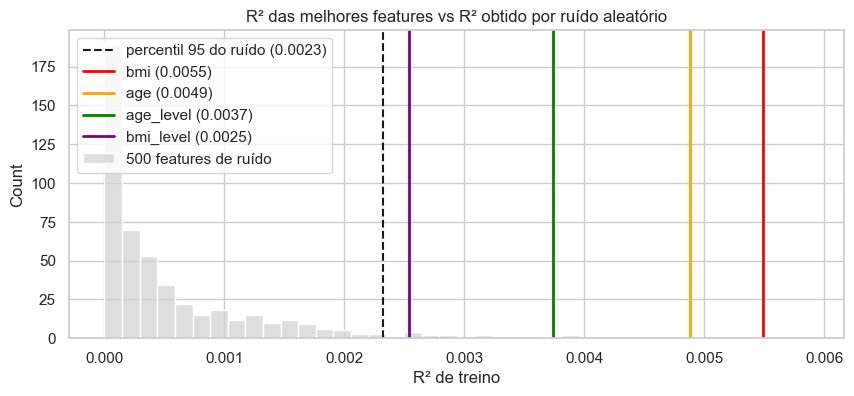

R2 medio do ruido: 0.0006 | percentil 95: 0.0023
Features acima do percentil 95 do ruido (8): ['bmi', 'age', 'age_level', 'bmi_level', 'smoking', 'salt_intake', 'physical_activity', 'triglycerides']


In [35]:
rng = np.random.default_rng(SEED)
noise_r2 = np.array([sm.OLS(y_train, sm.add_constant(rng.normal(size=len(y_train)))).fit().rsquared
                     for _ in range(500)])
p95 = np.percentile(noise_r2, 95)

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(noise_r2, bins=40, ax=ax, color='lightgrey', label='500 features de ruído')
ax.axvline(p95, color='k', ls='--', label=f'percentil 95 do ruído ({p95:.4f})')
for f, c in zip(simple.index[:4], ['red', 'orange', 'green', 'purple']):
    ax.axvline(simple.loc[f, 'R2_treino'], color=c, lw=2, label=f'{f} ({simple.loc[f, "R2_treino"]:.4f})')
ax.set_xlabel('R² de treino'); ax.set_title('R² das melhores features vs R² obtido por ruído aleatório'); ax.legend()
plt.show()

real = (simple['R2_treino'] > p95)
print(f'R2 medio do ruido: {noise_r2.mean():.4f} | percentil 95: {p95:.4f}')
print(f'Features acima do percentil 95 do ruido ({real.sum()}):', list(simple.index[real]))

**Conclusões:** as 500 features de ruído atingem, só por acaso, um R² médio de **0.0006**, e 5% delas passam os
**0.0023**. **8 features ficam acima deste limiar**: `bmi` (0.0055), `age` (0.0049), `age_level`, `bmi_level`,
`smoking`, `salt_intake`, `physical_activity` e `triglycerides`.

**Justificação:** o `bmi` explica cerca de **9 vezes** mais variância do que uma feature aleatória típica, e
mais do dobro do percentil 95 do ruído. **A relação é real**, e não um acaso da amostra. Ao mesmo tempo, o
gráfico mostra que todas as features vivem na mesma escala minúscula que o ruído (0 a 0.006). A relação existe,
mas é demasiado fraca para ter utilidade prática.

As restantes 22 features ficam dentro da distribuição do ruído: **não se distinguem de números aleatórios**, o
que coincide com as features "pouco informativas" identificadas na EDA.

### 6.4 Modelo simples escolhido: análise estatística (OLS)

Escolhemos a feature com **menor RMSE em validação cruzada** (tabela 2.2). Analisamo-la com o `statsmodels`, para obter:
- os coeficientes $\hat\beta_0$ e $\hat\beta_1$ e a respetiva **interpretação**;
- o **erro padrão** e o **intervalo de confiança a 95%** de $\hat\beta_1$;
- o **teste *t*** e o p-value.

Calculamos também previsões para pacientes concretos, para dar significado
prático ao coeficiente.

In [36]:
BEST_SIMPLE = simple.index[0]
ols_simple = sm.OLS(y_train, sm.add_constant(X_train[[BEST_SIMPLE]])).fit()
print(f'Feature escolhida: {BEST_SIMPLE}\n')
print(ols_simple.summary().tables[1])
b0, b1 = ols_simple.params
print(f'\nEquacao: target_regression = {b0:.3f} + {b1:.3f} x {BEST_SIMPLE}')
print(f'R2 treino = {ols_simple.rsquared:.4f}\n')
for v in (18.5, 25, 30, 40):
    print(f'  {BEST_SIMPLE} = {v:>4}  ->  previsao = {b0 + b1 * v:.1f}')
print(f'\nAmplitude real do target: {y_train.min():.0f} a {y_train.max():.0f} (desvio padrao {y_train.std():.1f})')

Feature escolhida: bmi

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        125.0606      4.411     28.353      0.000     116.408     133.713
bmi            0.4254      0.153      2.778      0.006       0.125       0.726

Equacao: target_regression = 125.061 + 0.425 x bmi
R2 treino = 0.0055

  bmi = 18.5  ->  previsao = 132.9
  bmi =   25  ->  previsao = 135.7
  bmi =   30  ->  previsao = 137.8
  bmi =   40  ->  previsao = 142.1

Amplitude real do target: 70 a 300 (desvio padrao 41.4)


**Conclusões - modelo simples escolhido: `bmi`.**

$$\widehat{target} = 125.06 + 0.425 \times bmi$$

- **Interpretação de β₁:** por cada unidade a mais de BMI, o target aumenta em média **0.43 unidades**. O
  intervalo de confiança a 95% é [0.125, 0.726], que não inclui o 0, e o teste *t* dá p = 0.006.
- **Interpretação de β₀:** 125.06 seria o valor previsto para BMI = 0. Não tem significado clínico (ninguém tem
  BMI 0); serve apenas para posicionar a reta.
- **Exemplos de previsão:** um paciente magro (BMI 18.5) tem uma previsão de 132.9 e um paciente com obesidade
  severa (BMI 40) de 142.1. **Uma diferença de 21.5 unidades de BMI muda a previsão em apenas 9 unidades**, num
  target que varia entre 70 e 300 (desvio padrão 41.4).

**Justificação da escolha:** o `bmi` é o melhor em todos os critérios: R² de treino (0.0055), RMSE de CV
(41.309), p-value (0.006), e o único destes com relação claramente acima do ruído (6.3). É também uma medição
contínua, mais informativa do que a sua versão categórica `bmi_level`. A escolha é coerente com a EDA, onde o `bmi`
já era a feature mais correlacionada com o target.

### 6.5 Visualização: valores reais vs previstos

Usamos três gráficos no conjunto de treino:
1. **Dispersão com a reta ajustada**: valores reais (pontos) e a reta $\hat y = \hat\beta_0 + \hat\beta_1 x$;
2. **Distribuição dos valores reais vs previstos**: um bom modelo produz previsões com uma distribuição
   parecida com a dos valores reais;
3. **Erro de previsão** (resíduo) de cada registo.

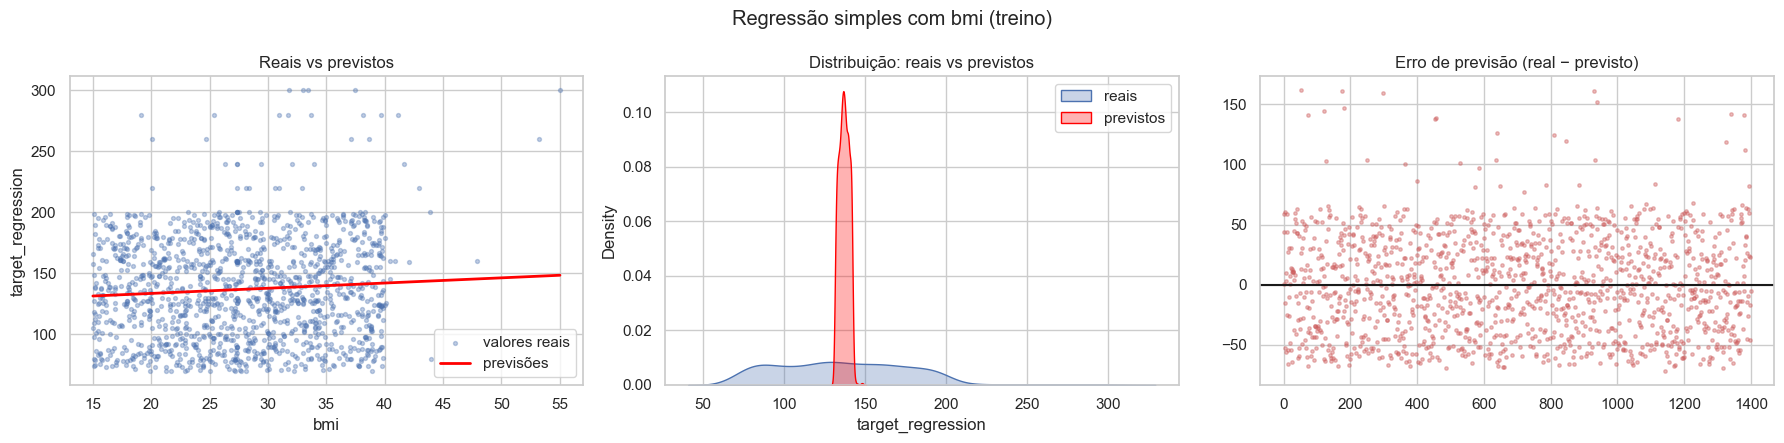

Previsoes: min 131.4, max 148.5, desvio padrao 3.07  |  valores reais: desvio padrao 41.37


In [37]:
pred_simple_train = ols_simple.fittedvalues

def plot_real_vs_pred(x, y_real, y_pred, xlabel, title, line=True):
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    axes[0].scatter(x, y_real, s=8, alpha=.35, label='valores reais')
    if line:
        order = np.argsort(np.asarray(x))
        axes[0].plot(np.asarray(x)[order], np.asarray(y_pred)[order], color='red', lw=2, label='previsões')
    else:
        axes[0].scatter(x, y_pred, s=8, alpha=.5, color='red', label='previsões')
    axes[0].set_xlabel(xlabel); axes[0].set_ylabel('target_regression'); axes[0].legend()
    axes[0].set_title('Reais vs previstos')
    sns.kdeplot(y_real, ax=axes[1], fill=True, alpha=.3, label='reais')
    sns.kdeplot(y_pred, ax=axes[1], fill=True, alpha=.3, color='red', label='previstos')
    axes[1].set_title('Distribuição: reais vs previstos'); axes[1].legend()
    axes[2].scatter(range(len(y_real)), np.asarray(y_real) - np.asarray(y_pred), s=6, alpha=.4, color='indianred')
    axes[2].axhline(0, color='k'); axes[2].set_title('Erro de previsão (real − previsto)')
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_real_vs_pred(X_train[BEST_SIMPLE], y_train, pred_simple_train, BEST_SIMPLE,
                  f'Regressão simples com {BEST_SIMPLE} (treino)')
print(f'Previsoes: min {pred_simple_train.min():.1f}, max {pred_simple_train.max():.1f}, '
      f'desvio padrao {pred_simple_train.std():.2f}  |  valores reais: desvio padrao {y_train.std():.2f}')

**Conclusões:**
1. **Reais vs previstos:** a reta é quase **horizontal**. Os pontos reais estão espalhados por toda a faixa 70–200,
   para qualquer valor de BMI. Conhecer o BMI de um paciente praticamente não ajuda a adivinhar o seu target.
2. **Distribuição:** o contraste é o resultado mais elucidativo. Os valores reais espalham-se de 70 a 300 (desvio
   padrão **41.4**); as previsões concentram-se num pico estreito entre 131 e 149 (desvio padrão **3.1**). **O
   modelo prevê praticamente o mesmo valor (~137) para todos os pacientes.**
3. **Erro de previsão:** os erros vão de cerca de −65 a +160 e não têm nenhum padrão ao longo dos registos.

**Justificação:** isto é exatamente o que um R² de 0.0055 significa na prática. Quando uma feature quase não
explica o target, a melhor estratégia de mínimos quadrados é prever um valor perto da média para todos. É o mesmo
fenómeno que na classificação: um modelo sem boas features tende a prever sempre a classe maioritária; aqui
tende a prever sempre a média.

### 6.6 Diagnóstico dos resíduos

Problemas a verificar numa regressão linear - Com os resíduos $e_i = y_i - \hat y_i$:
- **Resíduos vs valores previstos**: uma curva indicaria **não-linearidade**; um "funil" indicaria **variância não
  constante** dos erros;
- **Q-Q plot**: compara os resíduos com uma normal. A normalidade dos erros é um pressuposto dos testes *t* e *F*.

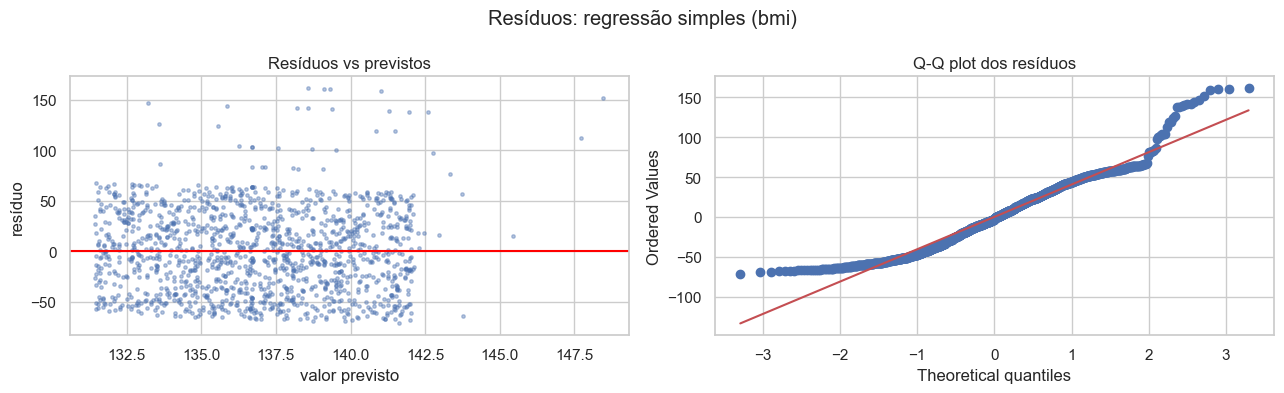

media dos residuos = -0.000 | skew = 0.50
Registos com o target no limite inferior (70): 10 | no limite superior (300): 5


In [38]:
def residual_plots(fitted, resid, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].scatter(fitted, resid, s=6, alpha=.4); axes[0].axhline(0, color='red')
    axes[0].set_xlabel('valor previsto'); axes[0].set_ylabel('resíduo'); axes[0].set_title('Resíduos vs previstos')
    stats.probplot(resid, plot=axes[1]); axes[1].set_title('Q-Q plot dos resíduos')
    fig.suptitle(title); plt.tight_layout(); plt.show()
    print(f'media dos residuos = {np.mean(resid):.3f} | skew = {stats.skew(resid):.2f}')

residual_plots(ols_simple.fittedvalues, ols_simple.resid, f'Resíduos: regressão simples ({BEST_SIMPLE})')
print(f'Registos com o target no limite inferior (70): {(y_train == 70).sum()} | no limite superior (300): {(y_train == 300).sum()}')

**Conclusões:**
- **Resíduos vs previstos:** a nuvem é uma faixa horizontal, sem curvatura nem forma de "funil". **Não há sinais
  de não-linearidade nem de variância não constante.**
- **Q-Q plot:** os resíduos afastam-se da normal nas caudas e têm **assimetria positiva** (skew = 0.50). Isto
  deve-se aos poucos valores muito altos do target (até 300), que geram resíduos positivos grandes. Com n = 1400,
  os testes *t* e *F* continuam aproximadamente válidos (teorema do limite central).
- Há 10 registos no valor mínimo (70) e 5 no máximo (300) do treino. A EDA tinha assinalado esta acumulação nos
  extremos como possível truncatura, mas afeta poucos registos.

**Justificação:** os resíduos não indicam que o modelo tenha a **forma errada**. Indicam que a feature **não tem
informação** suficiente. Mudar a forma do modelo (por exemplo, usar uma curva) não deve resolver o problema; é isso
que testamos a seguir.

### 6.7 Uma relação não-linear seria melhor?

Uma reta pode ser demasiado simples se a relação for curva.
Acrescentando termos polinomiais:
$\hat y = \beta_0 + \beta_1 x + \beta_2 x^2 + \dots$. Continua a ser regressão **linear** nos coeficientes.

Testamos os graus 1 a 5 com a feature escolhida. Um grau maior aumenta **sempre** o R² de treino, porque o modelo
fica mais flexível. Por isso a escolha tem de ser feita pela **validação cruzada**.

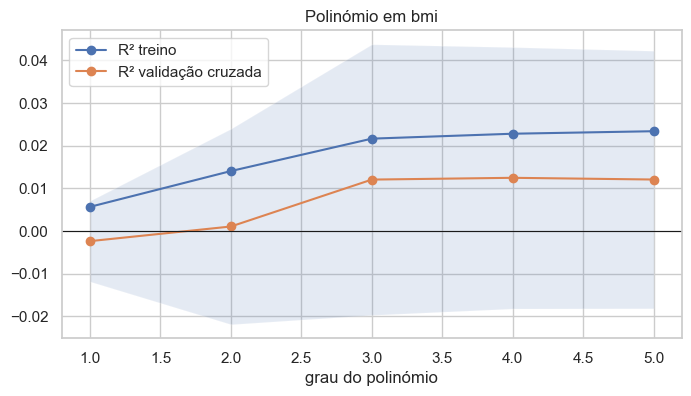

,train_r2,cv_r2,cv_r2_std,cv_mae,cv_rmse
grau,,,,,
1,0.0057,-0.0024,0.0095,33.9732,41.3094
2,0.0141,0.0011,0.0229,33.9041,41.2289
3,0.0216,0.0121,0.0317,33.7601,40.9945
4,0.0228,0.0125,0.0306,33.7529,40.9871
5,0.0234,0.0121,0.0302,33.7660,40.9960


In [39]:
poly = pd.DataFrame({d: cv_scores([BEST_SIMPLE], grau=d) for d in range(1, 6)}).T
poly.index.name = 'grau'

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(poly.index, poly['train_r2'], marker='o', label='R² treino')
ax.plot(poly.index, poly['cv_r2'], marker='o', label='R² validação cruzada')
ax.fill_between(poly.index, poly['cv_r2'] - poly['cv_r2_std'], poly['cv_r2'] + poly['cv_r2_std'], alpha=.15)
ax.axhline(0, color='k', lw=.8); ax.set_xlabel('grau do polinómio'); ax.set_title(f'Polinómio em {BEST_SIMPLE}')
ax.legend(); plt.show()
poly

**Conclusões:**
- O **R² de treino sobe sempre** com o grau (0.0057 → 0.0234), como esperado: um polinómio mais flexível ajusta-se
  melhor aos dados com que foi treinado.
- O **R² de CV** também sobe ligeiramente (de −0.002 no grau 1 para ~0.012 nos graus 3–5), e o RMSE de CV desce de
  41.31 para 40.99.
- No entanto, o **desvio padrão entre folds (0.03)** é 2–3 vezes maior que o ganho. Em alguns folds o polinómio é
  melhor, noutros pior.

**Justificação - devemos usar o polinómio?** Não. Há três razões:
1. o ganho não é **robusto**: está dentro da variabilidade normal da validação cruzada;
2. o gráfico 2.5 mostra que quase todos os pacientes têm BMI entre 15 e 40 e só alguns têm valores até ~55. Um
   polinómio de grau 3 ou mais pode "dobrar-se" para acompanhar esses poucos pontos extremos, o que é
   *overfitting* e não uma relação clínica;
3. o enunciado pede uma regressão **linear simples**, e a reta é mais interpretável.

Mantemos o modelo de grau 1.

### Resumo da Regressão Linear Simples

| Pergunta | Resposta | Evidência |
|---|---|---|
| Qual é a melhor feature? | **`bmi`** | Menor RMSE de CV (41.309), maior R² (0.0055), menor p-value (0.006) |
| A relação é real? | **Sim, mas fraquíssima** | 9× o R² médio do ruído; β₁ significativo |
| O modelo é útil para prever? | **Não** | Explica 0.55% da variância; o RMSE desce menos de 0.1 face à baseline; as previsões ficam todas entre 131 e 149 |
| Uma curva seria melhor? | **Não de forma robusta** | Ganho menor que a variabilidade entre folds |
| Faz sentido? | **Sim** | A EDA mostrou r ≈ 0.07 para o `bmi`, o máximo do dataset, e R² = r². O resultado era previsível. |

## 7. Regressão Linear Múltipla

$$\hat y = \hat\beta_0 + \hat\beta_1 x_1 + \hat\beta_2 x_2 + \dots + \hat\beta_p x_p$$

Cada $\beta_j$ mede o efeito de $x_j$ **mantendo as outras features fixas**. A ideia é combinar
várias features fracas na esperança de que, juntas, expliquem mais do que qualquer uma sozinha.

**Estratégia (construção incremental):**
1. Verificar a **colinearidade**, para saber que features não devem entrar juntas (7.1).
2. Construir o modelo **passo a passo**: 1 feature → 2 → 3 → …, e explicar cada ganho ou perda (7.2).
3. Testar **todas as combinações** de 2 e 3 features, para confirmar que a ordem escolhida não deixou nada de
   fora (7.3).
4. Testar **grupos clínicos** de features (7.4).
5. Mostrar o que acontece quando se usam **todas** as features: *overfitting* (7.5).
6. Mostrar o efeito da **colinearidade** nos coeficientes (7.6).
7. Testar variantes (transformação do target, polinómio) e escolher o modelo final (7.7–7.8).

### 7.1 Colinearidade entre features (VIF)

Quando duas features estão muito correlacionadas, o modelo não consegue separar o
efeito de cada uma. Os coeficientes ficam instáveis e podem perder significância.

O **VIF** (*Variance Inflation Factor*) de uma feature é $1/(1-R_j^2)$, onde $R_j^2$ é o R² obtido ao prever essa
feature a partir de todas as outras. Valores de referência: VIF = 1 significa que a feature é independente das
restantes; VIF > 5–10 indica colinearidade problemática.

In [40]:
Xc = sm.add_constant(X_train.astype(float))
vif = pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])],
                index=FEATURES, name='VIF').sort_values(ascending=False)
print(f'corr(age, age_level) = {X_train.age.corr(X_train.age_level):.3f} | '
      f'corr(bmi, bmi_level) = {X_train.bmi.corr(X_train.bmi_level):.3f}')
vif.to_frame().head(10)

corr(age, age_level) = 0.954 | corr(bmi, bmi_level) = 0.936


,VIF
age_level,11.3724
age,11.3228
bmi_level,8.4259
bmi,8.3254
high_ldl_cholesterol,2.8568
ldl,2.8506
low_hdl_cholesterol,1.4350
hdl,1.4106
employment_status_Unemployed,1.3630
employment_status_Retired,1.3548


**Conclusões:** há **dois pares de features colineares**, os mesmos que a EDA identificou:
- `age` ↔ `age_level`: VIF ≈ 11.3, correlação 0.954;
- `bmi` ↔ `bmi_level`: VIF ≈ 8.4, correlação 0.936.

Há também dois pares fracos: `ldl`/`high_ldl_cholesterol` (VIF ≈ 2.9) e `hdl`/`low_hdl_cholesterol` (≈ 1.4).
**Todas as outras features têm VIF próximo de 1**, ou seja, são praticamente independentes entre si.

**Justificação e decisão:** `age_level` e `bmi_level` são discretizações das variáveis contínuas e contêm a mesma
informação, mas com menos detalhe. Nas combinações seguintes usamos **apenas a versão contínua** (`age`, `bmi`) e
as variáveis originais `hdl`/`ldl` em vez das *flags*. Na secção 7.6 mostramos o que acontece quando esta regra não
é seguida.

### 7.2 Construção incremental: 1, 2, 3, … features

Construímos o modelo acrescentando **uma feature de cada vez**. A ordem segue a **força da relação com o target**
(|r| no treino, secção 6.1), mas usamos só uma versão de cada variável: a contínua (`age`, `bmi`), e não a
discretizada (`age_level`, `bmi_level`), por causa da colinearidade vista em 7.1.

Em cada passo registamos:
- **R² de treino**: sobe *sempre* que se acrescenta uma feature, mesmo que seja ruído, porque o modelo tem mais
  liberdade para se ajustar aos dados;
- **R² ajustado**: $1 - (1-R^2)\frac{n-1}{n-p-1}$. Penaliza o número de features *p* e só sobe se a nova feature
  acrescentar mais do que o esperado por acaso;
- **R², MAE e RMSE em validação cruzada**: dizem se o modelo melhora em dados novos.

**O que procuramos:** o ponto a partir do qual acrescentar features deixa de reduzir o erro de validação.

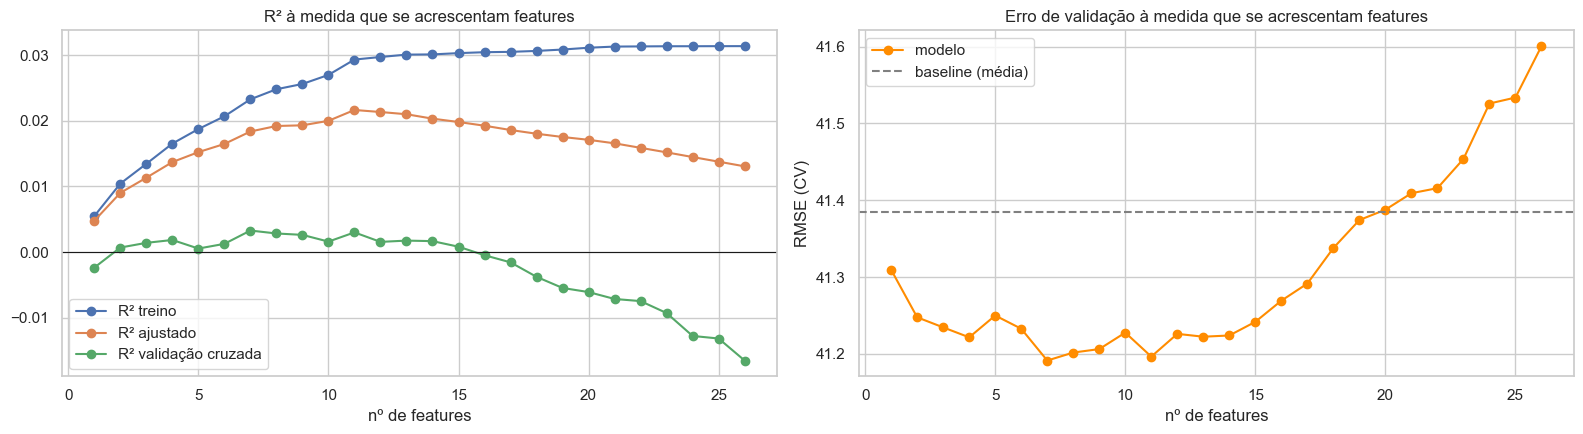

,feature adicionada,r da feature,R2_treino,R2_ajustado,cv_r2,cv_mae,cv_rmse
n,,,,,,,
1,bmi,0.0741,0.0055,0.0048,-0.0024,33.9732,41.3094
2,age,0.0699,0.0104,0.0090,0.0007,33.8505,41.2475
3,smoking,-0.0603,0.0135,0.0113,0.0014,33.8462,41.2344
4,salt_intake,-0.0568,0.0165,0.0137,0.0018,33.7758,41.2214
5,triglycerides,0.0530,0.0188,0.0152,0.0005,33.8280,41.2498
6,physical_activity,0.0496,0.0207,0.0165,0.0012,33.8581,41.2326
7,HbA1c_level,0.0437,0.0233,0.0184,0.0033,33.9333,41.1912
8,hdl,-0.0374,0.0248,0.0192,0.0028,33.9264,41.2016
9,crp_level,0.0372,0.0256,0.0193,0.0026,33.9272,41.2061


In [41]:
order = [f for f in r_train.abs().sort_values(ascending=False).index
         if f not in ('age_level', 'bmi_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol')]
rows = []
for k in range(1, len(order) + 1):
    cols = order[:k]
    ols = sm.OLS(y_train, sm.add_constant(X_train[cols].astype(float))).fit()
    cv = cv_scores(cols)
    rows.append({'n': k, 'feature adicionada': cols[-1], 'r da feature': r_train[cols[-1]],
                 'R2_treino': ols.rsquared, 'R2_ajustado': ols.rsquared_adj,
                 'cv_r2': cv['cv_r2'], 'cv_mae': cv['cv_mae'], 'cv_rmse': cv['cv_rmse']})
incremental = pd.DataFrame(rows).set_index('n')

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].plot(incremental.index, incremental['R2_treino'], marker='o', label='R² treino')
axes[0].plot(incremental.index, incremental['R2_ajustado'], marker='o', label='R² ajustado')
axes[0].plot(incremental.index, incremental['cv_r2'], marker='o', label='R² validação cruzada')
axes[0].axhline(0, color='k', lw=.8); axes[0].set_xlabel('nº de features'); axes[0].legend()
axes[0].set_title('R² à medida que se acrescentam features')
axes[1].plot(incremental.index, incremental['cv_rmse'], marker='o', color='darkorange', label='modelo')
axes[1].axhline(baseline_cv['cv_rmse'], color='grey', ls='--', label='baseline (média)')
axes[1].set_xlabel('nº de features'); axes[1].set_ylabel('RMSE (CV)'); axes[1].legend()
axes[1].set_title('Erro de validação à medida que se acrescentam features')
plt.tight_layout(); plt.show()
incremental.head(12)

**Conclusões passo a passo:**

| Passo | O que acontece | Porquê |
|---|---|---|
| **1 → 2** (`bmi` + `age`) | O R² de CV passa de −0.002 para **0.001** (primeiro valor positivo) e o RMSE desce de 41.31 para 41.25. **É o maior ganho de toda a construção.** | `age` é a 2.ª feature mais correlacionada com o target (r = 0.070) e é **independente** do `bmi` (correlação −0.007). Por isso traz informação nova: os contributos somam-se (R² de treino 0.0055 + 0.0049 ≈ 0.0104). |
| **2 → 4** (+ `smoking`, + `salt_intake`) | Pequenas melhorias: RMSE 41.23 → 41.22. | Features com r ≈ −0.06, também independentes das anteriores. Cada uma acrescenta ~0.3% de R² de treino. |
| **5** (+ `triglycerides`) | O RMSE de CV **sobe** (41.25). | A feature ajuda no treino, mas não generaliza: o contributo que dá no treino é, em parte, ruído. |
| **7** (+ `HbA1c_level`) | **Melhor RMSE de CV: 41.191.** | `HbA1c_level` tem r baixo no treino (0.044), mas combinado com as restantes melhora a validação. |
| **8 → 12** | O RMSE de CV oscila entre 41.20 e 41.23, sem melhorar. | As features novas têm r < 0.04: estão ao nível do ruído (secção 6.3). |

**O padrão geral (gráfico):**
- o **R² de treino sobe sempre** (0.0055 → 0.0298 com 12 features), porque cada feature dá ao modelo mais
  liberdade para se ajustar aos dados de treino, mesmo que seja ruído;
- o **R² ajustado** sobe cada vez mais devagar, porque penaliza o número de features;
- o **R² de CV estabiliza à volta de 0.002–0.003** a partir de 4 features e depois oscila. O RMSE de CV nunca desce
  mais do que ~0.2 abaixo da baseline.

**Justificação:** a diferença crescente entre o R² de treino e o R² de CV é a definição de *overfitting*. As
primeiras features (`bmi`, `age`) trazem informação real; as seguintes trazem sobretudo ruído, que melhora o treino
mas não os dados novos.

### 7.3 Todas as combinações de 2 e de 3 features

A construção incremental seguiu uma ordem fixa (a do |r|), mas pode acontecer que duas features individualmente
fracas funcionem bem em conjunto. Para confirmar, testamos **todas** as combinações de 2 e de 3 features entre as
12 melhores features contínuas/ordinais (66 pares e 220 trios), avaliadas por validação cruzada.

Mostramos as 5 melhores e as 3 piores de cada tamanho, para perceber **o que distingue uma boa combinação de uma
má.**

In [42]:
pool = order[:12]
combo_rows = []
for size in (2, 3):
    for cols in combinations(pool, size):
        cv = cv_scores(list(cols))
        combo_rows.append({'n': size, 'features': ' + '.join(cols), 'cv_r2': cv['cv_r2'],
                           'cv_mae': cv['cv_mae'], 'cv_rmse': cv['cv_rmse']})
combos_df = pd.DataFrame(combo_rows)
for size in (2, 3):
    sub = combos_df[combos_df.n == size].sort_values('cv_rmse')
    print(f'\n=== {size} features: {len(sub)} combinacoes | {(sub.cv_rmse < baseline_cv["cv_rmse"]).sum()} melhores que a baseline ===')
    display(pd.concat([sub.head(5), sub.tail(3)]).set_index('features'))
print(f'corr(bmi, age) no treino = {X_train.bmi.corr(X_train.age):.3f}')


=== 2 features: 66 combinacoes | 53 melhores que a baseline ===


,n,cv_r2,cv_mae,cv_rmse
features,,,,
bmi + age,2,0.0007,33.8505,41.2475
bmi + HbA1c_level,2,-0.0008,34.0375,41.2767
age + HbA1c_level,2,-0.0009,33.8854,41.2838
bmi + physical_activity,2,-0.0014,34.0030,41.2866
bmi + smoking,2,-0.0012,33.9500,41.2876
alcohol_intake + family_history,2,-0.0070,33.9994,41.4069
hdl + family_history,2,-0.0073,33.9676,41.4131
hdl + alcohol_intake,2,-0.0073,33.9550,41.4162



=== 3 features: 220 combinacoes | 188 melhores que a baseline ===


,n,cv_r2,cv_mae,cv_rmse
features,,,,
bmi + age + HbA1c_level,3,0.0026,33.9074,41.2080
bmi + age + blood_pressure,3,0.0022,33.8227,41.2136
bmi + age + smoking,3,0.0014,33.8462,41.2344
bmi + age + physical_activity,3,0.0011,33.8761,41.2360
bmi + age + salt_intake,3,0.0010,33.7757,41.2369
triglycerides + hdl + alcohol_intake,3,-0.0075,34.0138,41.4196
triglycerides + hdl + family_history,3,-0.0078,34.0234,41.4255
hdl + alcohol_intake + family_history,3,-0.0080,33.9871,41.4295


corr(bmi, age) no treino = -0.007


**Conclusões:**
- **Melhor par: `bmi` + `age`** (RMSE de CV 41.248). **Melhor trio: `bmi` + `age` + `HbA1c_level`** (41.208),
  seguido de `bmi` + `age` + `blood_pressure` (41.214).
- **Os 5 melhores pares e os 5 melhores trios contêm todos o `bmi`**, e todos os melhores trios contêm `bmi` e
  `age`.
- **As piores combinações** juntam `hdl`, `alcohol_intake`, `family_history` e `triglycerides` (RMSE ≈ 41.41–41.43,
  **pior que a baseline**).
- Ainda assim, 53 dos 66 pares e 188 dos 220 trios ficam (muito ligeiramente) abaixo da baseline.

**Justificação - porque é que umas combinações dão menos erro que outras?**
1. **Uma combinação é tão boa quanto as features que a compõem.** `bmi` e `age` são as duas features com maior |r|
   e as únicas claramente acima do ruído em 6.3. Qualquer combinação sem elas perde.
2. **As features devem trazer informação diferente.** `bmi` e `age` têm correlação −0.007 entre si: cada uma
   explica uma parte diferente da variância do target, e os efeitos somam-se. Juntar duas features correlacionadas
   (como `bmi` e `bmi_level`) não acrescenta nada, porque repetem a mesma informação.
3. **Juntar features sem relação com o target piora o modelo.** As piores combinações são formadas por features ao
   nível do ruído. O modelo estima coeficientes para elas a partir de padrões aleatórios do treino, que não se
   repetem nos dados de validação, e o erro aumenta.

A pesquisa exaustiva confirma a ordem da construção incremental: não há nenhum par ou trio "escondido" que
funcione melhor do que as combinações com `bmi` e `age`.

### 7.4 Grupos clínicos de features

Outra forma de escolher combinações é usar **conhecimento do domínio**: agrupar as features pelo tipo de
informação clínica que representam e ver se algum grupo, no seu conjunto, explica o target. Se o target fosse, por
exemplo, um marcador lipídico, o grupo lipídico deveria destacar-se.

In [43]:
GROUPS = {
    'Antropométrico (age, bmi)':              ['age', 'bmi'],
    'Antropométrico + glicémico':             ['age', 'bmi', 'HbA1c_level'],
    'Glicémico (HbA1c)':                      ['HbA1c_level'],
    'Lipídico':                               ['cholesterol', 'triglycerides', 'hdl', 'ldl'],
    'Pressão arterial / cardíaco':            ['systolic_bp', 'diastolic_bp', 'blood_pressure', 'heart_rate'],
    'Inflamatório':                           ['crp_level', 'homocysteine_level', 'plasma_value'],
    'Estilo de vida':                         ['smoking', 'physical_activity', 'stress_level', 'sugar_consumption',
                                               'sleep_hours', 'alcohol_intake', 'salt_intake'],
    'Sociodemográfico':                       ['gender', 'education_level', 'family_history',
                                               'employment_status_Retired', 'employment_status_Unemployed'],
    'Todas as numéricas contínuas':           CONTINUOUS,
}
groups = pd.DataFrame({g: {'n_features': len(c), **cv_scores(c)} for g, c in GROUPS.items()}).T
groups['melhor que baseline?'] = groups['cv_rmse'] < baseline_cv['cv_rmse']
groups.sort_values('cv_rmse')

,n_features,train_r2,cv_r2,cv_r2_std,cv_mae,cv_rmse,melhor que baseline?
Antropométrico + glicémico,3.0000,0.0131,0.0026,0.0091,33.9074,41.2080,True
"Antropométrico (age, bmi)",2.0000,0.0108,0.0007,0.0096,33.8505,41.2475,True
Glicémico (HbA1c),1.0000,0.0020,-0.0043,0.0043,34.0091,41.3526,True
Todas as numéricas contínuas,17.0000,0.0291,-0.0056,0.0174,33.9903,41.3733,True
Estilo de vida,7.0000,0.0121,-0.0071,0.0135,33.9405,41.4047,False
Lipídico,4.0000,0.0058,-0.0073,0.0126,33.9931,41.4164,False
Inflamatório,3.0000,0.0018,-0.0085,0.0073,33.9810,41.4390,False
Pressão arterial / cardíaco,4.0000,0.0020,-0.0105,0.0058,34.0077,41.4768,False
Sociodemográfico,5.0000,0.0025,-0.0135,0.0045,34.0732,41.5417,False


**Conclusões:**
- Só **4 grupos** ficam abaixo da baseline: **antropométrico + glicémico** (RMSE 41.208), antropométrico (41.248),
  glicémico (41.353) e, por muito pouco, todas as numéricas contínuas (41.373 contra 41.385).
- Os grupos **lipídico, pressão arterial, inflamatório, estilo de vida e sociodemográfico ficam todos acima da
  baseline**: prevêem pior do que a média.
- O grupo com **todas as 17 numéricas contínuas** tem o maior R² de treino (0.029), mas em validação cruzada fica
  praticamente igual à baseline (41.373 contra 41.385). O pouco sinal de `age` e `bmi` é quase todo anulado pelo
  ruído das outras 15 features.

**Justificação:** um grupo funciona se contiver features relacionadas com o target. Os grupos vencedores são os
que incluem `age` e `bmi`, as únicas com sinal real. Os outros grupos são formados por features com r ≈ 0 (Parte 1,
secção 3.4) e, sem nada para aprender, só acrescentam ruído.

O mau desempenho do grupo lipídico é informativo: **não há evidência de que o target seja um marcador lipídico**,
porque colesterol, triglicéridos, HDL e LDL não o explicam. O mesmo vale para a pressão arterial e a inflamação. O
nome e as unidades do target continuam desconhecidos.

### 7.5 E se usarmos todas as features? *Overfitting*

A tentação natural é "pôr tudo no modelo". Ajustamos a regressão com as 30 features e comparamos o desempenho no
**treino** com o desempenho em **validação cruzada**. Uma diferença grande entre os dois é o sinal clássico de
***overfitting***: o modelo ajusta-se ao ruído específico dos dados de treino, que não se repete em dados novos.

In [44]:
ols_all = sm.OLS(y_train, sm.add_constant(X_train.astype(float))).fit()
cv_all = cv_scores(FEATURES)
print(f'R2 treino = {ols_all.rsquared:.4f} | R2 ajustado = {ols_all.rsquared_adj:.4f} | '
      f'teste F: F = {ols_all.fvalue:.2f}, p = {ols_all.f_pvalue:.4f}')
print(f'CV: R2 = {cv_all["cv_r2"]:.4f} | MAE = {cv_all["cv_mae"]:.3f} | RMSE = {cv_all["cv_rmse"]:.3f}')
print(f'Baseline CV RMSE = {baseline_cv["cv_rmse"]:.3f}')
sig = ols_all.pvalues.drop('const')
print(f'\nCoeficientes com p < 0.05: {list(sig[sig < 0.05].index)}')

R2 treino = 0.0370 | R2 ajustado = 0.0159 | teste F: F = 1.75, p = 0.0073
CV: R2 = -0.0261 | MAE = 34.201 | RMSE = 41.793
Baseline CV RMSE = 41.385

Coeficientes com p < 0.05: ['bmi_level', 'bmi', 'triglycerides', 'salt_intake']


**Conclusões:** com as 30 features:
- o **R² de treino é o mais alto de todos (0.0370)** e o teste *F* é significativo (p = 0.007);
- mas o **R² de CV é −0.026** e o RMSE de CV é **41.79, claramente pior que a baseline (41.38)**;
- o R² ajustado (0.0159) é mais baixo que o de modelos com menos features (secção 7.2);
- 4 coeficientes são significativos: `bmi_level`, `bmi`, `triglycerides` e `salt_intake`. Dois deles são o par
  colinear `bmi`/`bmi_level`, cujos coeficientes ficam distorcidos (ver 7.6).

**Justificação:** isto é ***overfitting***. Com 30 coeficientes para estimar e quase nenhum sinal real, o modelo
usa a sua flexibilidade para se ajustar a padrões aleatórios do treino. Esses padrões não existem nos dados de
validação, por isso **o modelo com mais features é o que pior generaliza**.

É também um bom exemplo de que um teste *F* significativo não garante um modelo útil: o teste diz que pelo menos
um coeficiente é diferente de zero, não que o modelo prevê bem.

### 7.6 O efeito da colinearidade nos coeficientes

Para mostrar na prática o problema identificado em 7.1, comparamos o coeficiente de `bmi` em dois modelos:
- só com `bmi`;
- com `bmi` **e** `bmi_level` (a sua versão discretizada, VIF ≈ 8).

Se a colinearidade for um problema, o erro padrão do coeficiente aumenta e o p-value piora, **sem que o modelo
preveja melhor**.

In [45]:
m1 = sm.OLS(y_train, sm.add_constant(X_train[['bmi']])).fit()
m2 = sm.OLS(y_train, sm.add_constant(X_train[['bmi', 'bmi_level']])).fit()
colin = pd.DataFrame({
    'so bmi':            {'coef bmi': m1.params['bmi'], 'erro padrao bmi': m1.bse['bmi'], 'p-value bmi': m1.pvalues['bmi'],
                          'R2 treino': m1.rsquared, 'CV RMSE': cv_scores(['bmi'])['cv_rmse']},
    'bmi + bmi_level':   {'coef bmi': m2.params['bmi'], 'erro padrao bmi': m2.bse['bmi'], 'p-value bmi': m2.pvalues['bmi'],
                          'R2 treino': m2.rsquared, 'CV RMSE': cv_scores(['bmi', 'bmi_level'])['cv_rmse']},
}).T
colin

,coef bmi,erro padrao bmi,p-value bmi,R2 treino,CV RMSE
so bmi,0.4254,0.1531,0.0055,0.0055,41.3094
bmi + bmi_level,1.2453,0.4343,0.0042,0.0084,41.3448


**Conclusões:**
- **Só `bmi`:** coeficiente 0.425, erro padrão 0.153.
- **`bmi` + `bmi_level`:** o coeficiente do `bmi` **quase triplica** (1.245) e o erro padrão também (0.434).
  O R² de treino sobe um pouco (0.0055 → 0.0084), mas o **RMSE de CV piora** (41.31 → 41.34).

**Justificação:** como `bmi` e `bmi_level` medem o mesmo (correlação 0.936), o modelo não consegue separar o efeito
de cada uma. O coeficiente do `bmi` deixa de significar "efeito de uma unidade de BMI", porque passa a ser
compensado pelo coeficiente de `bmi_level` em sentido contrário. Os coeficientes ficam **instáveis e
inflacionados**, sem nenhum ganho de previsão. Isto confirma a decisão de
usar apenas as variáveis contínuas.

### 7.7 Variantes: transformação do target e termos polinomiais

Testamos duas ideias, aplicadas à melhor combinação encontrada até aqui:
1. **`log1p(target)`**: reduz a assimetria do target. As métricas são calculadas
   de volta na escala original, para serem comparáveis;
2. **Polinómio de grau 2**: acrescenta os quadrados e os produtos entre features
   (interações).

In [46]:
best_combo_row = combos_df.sort_values('cv_rmse').iloc[0]
best_inc_n = incremental['cv_rmse'].idxmin()
candidates_multi = {
    f'Incremental (melhor n = {best_inc_n})': order[:best_inc_n],
    f'Melhor combinação ({best_combo_row.features})': best_combo_row.features.split(' + '),
}
BEST_MULTI_NAME = min(candidates_multi, key=lambda k: cv_scores(candidates_multi[k])['cv_rmse'])
BEST_MULTI = candidates_multi[BEST_MULTI_NAME]
print('Candidatos:'); [print(f'  {k}: {v}') for k, v in candidates_multi.items()]
print(f'Base para as variantes: {BEST_MULTI_NAME}\n')

variants = pd.DataFrame({
    'linear':                cv_scores(BEST_MULTI),
    'log1p(target)':         cv_scores(BEST_MULTI, log_alvo=True),
    'polinómio grau 2':      cv_scores(BEST_MULTI, grau=2),
}).T
print(f'skew do target: {y_train.skew():.2f} -> skew de log1p(target): {np.log1p(y_train).skew():.2f}')
variants

Candidatos:
  Incremental (melhor n = 7): ['bmi', 'age', 'smoking', 'salt_intake', 'triglycerides', 'physical_activity', 'HbA1c_level']
  Melhor combinação (bmi + age + HbA1c_level): ['bmi', 'age', 'HbA1c_level']
Base para as variantes: Incremental (melhor n = 7)

skew do target: 0.53 -> skew de log1p(target): -0.16


,train_r2,cv_r2,cv_r2_std,cv_mae,cv_rmse
linear,0.0248,0.0033,0.0105,33.9333,41.1912
log1p(target),0.0033,-0.0176,0.0291,33.9824,41.6151
polinómio grau 2,0.0768,0.0117,0.0221,34.0876,41.0132


**Conclusões:** as duas candidatas a modelo múltiplo eram:
- **incremental com 7 features** (RMSE de CV 41.191);
- **o melhor trio** `bmi` + `age` + `HbA1c_level` (41.208).

A de 7 features tem o menor erro e foi usada como base para as variantes:
- **`log1p(target)`:** reduz a assimetria do target (0.53 → −0.16), mas **piora** o modelo (RMSE de CV 41.62, R² de
  CV −0.018);
- **polinómio de grau 2:** sobe o R² de CV para 0.012 e baixa o RMSE para 41.01, mas **piora o MAE** (34.09 vs
  33.93). Com 7 features, passa de 7 para 35 termos e o R² de treino triplica (0.077): sinal de *overfitting*.

**Justificação:**
- No exemplo Boston Housing, o `log1p` ajudava porque havia relações fortes, que ficavam mais lineares na escala
  logarítmica. Aqui o problema não é a forma da distribuição: é a falta de informação nas features. O log
  comprime os valores altos, e o modelo passa a subestimá-los ainda mais.
- O ganho do polinómio é menor que o desvio padrão entre folds (0.022) e não se confirma no MAE. Não é robusto.

**Decisão:** manter a regressão **linear**.

### 7.8 Modelo múltiplo escolhido: análise estatística e visualização

Analisamos o modelo escolhido com o `statsmodels`:
- **teste *F*** do modelo global, $H_0: \beta_1 = \dots = \beta_p = 0$, que responde à questão (alguma feature é útil?);
- **teste *t*** de cada coeficiente;
- os mesmos gráficos de valores reais vs previstos e de resíduos usados na regressão simples.

Features: ['bmi', 'age', 'smoking', 'salt_intake', 'triglycerides', 'physical_activity', 'HbA1c_level']

                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                93.2643     15.300      6.096      0.000      63.251     123.277
bmi                   0.3983      0.152      2.615      0.009       0.100       0.697
age                   0.1388      0.054      2.580      0.010       0.033       0.244
smoking              -2.4445      1.338     -1.828      0.068      -5.068       0.179
salt_intake          -0.6715      0.314     -2.141      0.032      -1.287      -0.056
triglycerides         0.0343      0.017      2.021      0.043       0.001       0.068
physical_activity     2.1089      1.349      1.563      0.118      -0.538       4.756
HbA1c_level           3.7061      1.927      1.923      0.055      -0.075       7.487

R2 treino = 0.0233 | R2 ajustado =

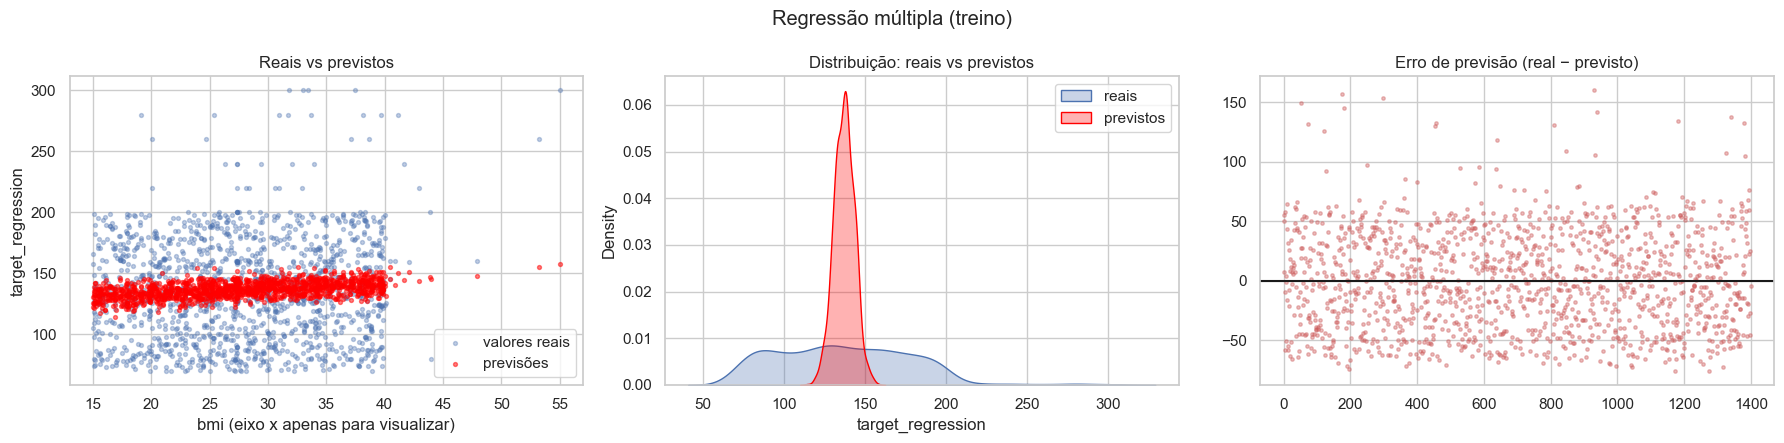

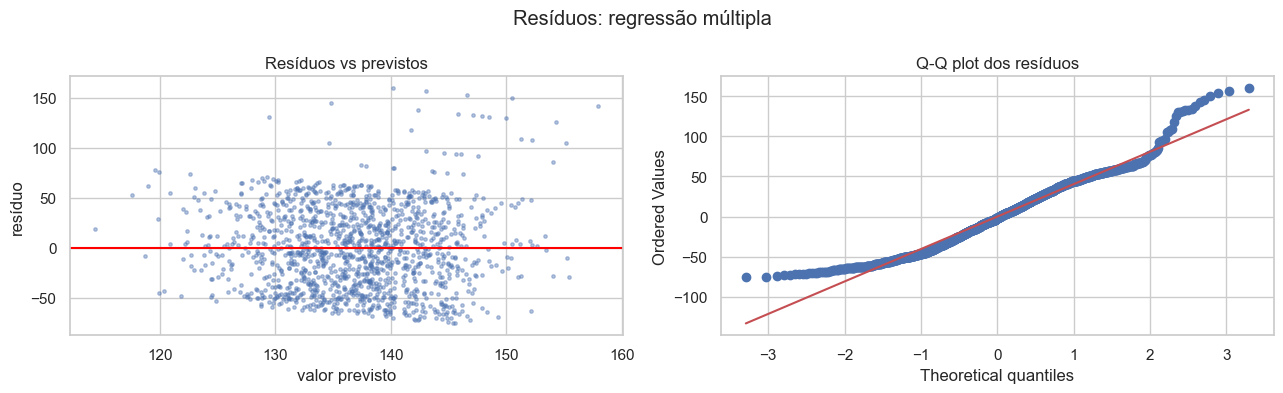

media dos residuos = 0.000 | skew = 0.43
Previsoes: min 114.4, max 157.9, desvio padrao 6.32


In [47]:
ols_multi = sm.OLS(y_train, sm.add_constant(X_train[BEST_MULTI].astype(float))).fit()
print(f'Features: {BEST_MULTI}\n')
print(ols_multi.summary().tables[1])
print(f'\nR2 treino = {ols_multi.rsquared:.4f} | R2 ajustado = {ols_multi.rsquared_adj:.4f}')
print(f'Teste F global: F = {ols_multi.fvalue:.3f}, p = {ols_multi.f_pvalue:.2e}')
eq = ' '.join(f'{v:+.3f} x {k}' for k, v in ols_multi.params.drop('const').items())
print(f'\nEquacao: target_regression = {ols_multi.params["const"]:.3f} {eq}')

plot_real_vs_pred(X_train['bmi'], y_train, ols_multi.fittedvalues, 'bmi (eixo x apenas para visualizar)',
                  'Regressão múltipla (treino)', line=False)
residual_plots(ols_multi.fittedvalues, ols_multi.resid, 'Resíduos: regressão múltipla')
print(f'Previsoes: min {ols_multi.fittedvalues.min():.1f}, max {ols_multi.fittedvalues.max():.1f}, '
      f'desvio padrao {ols_multi.fittedvalues.std():.2f}')

**Conclusões - modelo múltiplo escolhido: construção incremental com 7 features.**

$$\widehat{target} = 93.26 + 0.398\,bmi + 0.139\,age - 2.44\,smoking - 0.672\,salt + 0.034\,trig + 2.11\,phys.act + 3.71\,HbA1c$$

- **Teste *F* global:** F = 4.74, p = 2.8×10⁻⁵. Rejeitamos $H_0$ (todos os β = 0): as features, em conjunto, têm
  relação estatística com o target.
- **Coeficientes significativos (p < 0.05):** `bmi` (+0.40 por unidade), `age` (+0.14 por ano), `salt_intake`
  (−0.67) e `triglycerides` (+0.034). `HbA1c_level` (p = 0.055) e `smoking` (p = 0.068) ficam na fronteira;
  `physical_activity` não é significativo (p = 0.12).
- Os coeficientes de `bmi` (0.398) e `age` (0.139) são praticamente iguais aos dos modelos simples (0.425 e 0.141).
  Isto confirma que as features são independentes (VIF ≈ 1): juntá-las não altera o efeito de cada uma.
- **R² de treino = 0.023 (ajustado 0.018):** o modelo explica cerca de **2%** da variância, 4 vezes mais que a
  regressão simples, mas continua muito baixo.

**Visualização:** as previsões espalham-se um pouco mais que as do modelo simples (114–158, desvio padrão 6.3, contra
3.1), mas continuam muito concentradas face aos valores reais (desvio padrão 41.4). Os resíduos mantêm o mesmo
comportamento: sem padrão, com assimetria positiva (skew = 0.43).

**Interpretação clínica: cautela.** Alguns sinais não são os esperados clinicamente (por exemplo, mais sal associado
a um target *menor*). Como os efeitos são minúsculos e o target é desconhecido, **não devemos tirar conclusões
clínicas** destes coeficientes.

**Justificação da escolha:** é a combinação com menor RMSE de CV (41.191). Em alternativa, o trio `bmi` + `age` +
`HbA1c_level` tem um erro quase igual (41.208), com menos de metade das features. A diferença entre os dois (0.017)
é muito menor que a variabilidade entre folds, por isso o trio seria uma escolha igualmente defensável pelo
princípio da parcimónia (preferir o modelo mais simples quando o desempenho é equivalente).

### Resumo da Regressão Linear Múltipla

| Pergunta | Resposta | Evidência |
|---|---|---|
| Juntar features ajuda? | **Um pouco, até ~4–7 features** | RMSE de CV 41.31 (1 feature) → 41.19 (7) |
| Qual é o melhor grupo? | **`bmi`, `age`, `smoking`, `salt_intake`, `triglycerides`, `physical_activity`, `HbA1c_level`** | Menor RMSE de CV entre construção incremental, 286 combinações e 9 grupos clínicos |
| Porque é que `bmi` + `age` é o melhor par? | São as 2 features com mais sinal **e** são independentes entre si | r = 0.074 e 0.070; correlação entre ambas −0.007 |
| E com todas as features? | **Pior que a baseline** | *Overfitting*: R² de treino 0.0370, R² de CV −0.026 |
| Usar contínua + discretizada? | **Não** | Coeficientes instáveis e inflacionados, sem ganho de previsão |
| Faz sentido? | **Sim** | Combinar features fracas e independentes soma R² pequenos (0.0055 + 0.0049 + …), mas o total fica em ~2% |

## 8. Avaliação final no conjunto de teste

Com todas as escolhas fechadas **usando apenas o treino**, avaliamos agora os modelos no teste (600 registos
nunca usados). É esta avaliação que responde ao enunciado: *"Evaluate both models using appropriate metrics
(R², MAE, RMSE)"*.

Comparamos quatro modelos:
- **Baseline** (média do treino), a referência mínima;
- **Regressão simples** escolhida na secção 6;
- **Regressão múltipla** escolhida na secção 7;
- **Regressão com todas as features**, apenas para confirmar o *overfitting* (não é um modelo escolhido).

### 8.1 Métricas no teste

Cada modelo é treinado em todo o conjunto de treino e avaliado no teste. Mostramos as métricas de treino ao lado
das de teste: a diferença entre as duas mostra quanto cada modelo perde ao passar para dados novos.

In [48]:
final_models = {
    'Baseline (média)':                        ('media', FEATURES),
    f'Simples ({BEST_SIMPLE})':                 ('linear', [BEST_SIMPLE]),
    f'Múltipla ({" + ".join(BEST_MULTI)})':     ('linear', BEST_MULTI),
    f'Todas as features ({len(FEATURES)})':     ('linear', FEATURES),
}
preds, rows = {}, {}
for name, (tipo, cols) in final_models.items():
    prever = prever_media(y_train) if tipo == 'media' else ajustar_linear(X_train[cols], y_train)
    preds[name] = prever(X_test[cols])
    rows[name] = {**{f'treino_{k}': v for k, v in metrics(y_train, prever(X_train[cols])).items()},
                  **{f'teste_{k}': v for k, v in metrics(y_test, preds[name]).items()}}
results = pd.DataFrame(rows).T
names = list(preds)
results

,treino_R2,treino_MAE,treino_RMSE,teste_R2,teste_MAE,teste_RMSE
Baseline (média),0.0000,33.9128,41.3560,-0.0058,34.2872,41.0163
Simples (bmi),0.0055,33.9046,41.2423,-0.0024,34.1833,40.9479
Múltipla (bmi + age + smoking + salt_intake + triglycerides + physical_activity + HbA1c_level),0.0233,33.6568,40.8713,0.0045,34.1100,40.8067
Todas as features (30),0.0370,33.2981,40.5832,-0.0180,34.3145,41.2641


**Conclusões - resultados no teste (600 pacientes nunca vistos):**

| Modelo | R² | MAE | RMSE |
|---|---|---|---|
| Baseline (média) | −0.006 | 34.29 | 41.02 |
| Simples (`bmi`) | −0.002 | 34.18 | 40.95 |
| **Múltipla (7 features)** | **0.005** | **34.11** | **40.81** |
| Todas as features (30) | −0.018 | 34.31 | 41.26 |

- **A regressão múltipla é a melhor nas três métricas**, seguida da simples e da baseline. **A ordem é a mesma que
  em validação cruzada**: as escolhas feitas só com o treino generalizaram de forma coerente.
- O modelo com todas as features é **o pior**, abaixo da baseline. Tem o maior R² de treino (0.0370) e o menor de
  teste (−0.018), o que confirma o *overfitting* detetado em 7.5.
- As melhorias são **muito pequenas**: a múltipla erra em média **34.11** contra **34.29** da baseline, menos 0.18
  unidades (**0.5%**).
- Em todos os modelos o R² de teste é menor que o de treino, como esperado.

### 8.2 As diferenças entre modelos são reais? (*bootstrap*)

As diferenças da tabela anterior podem ser pequenas. Para saber se são reais ou fruto do acaso (de quais pacientes
calharam no teste), usamos ***bootstrap***: reamostramos o conjunto de teste 1000 vezes, com reposição, e
recalculamos as métricas em cada reamostra. Obtemos assim um **intervalo de confiança a 95%** para cada métrica e
para a diferença entre modelos.

Se o intervalo da diferença entre um modelo e a baseline incluir o zero, **não podemos afirmar que o modelo é
melhor que prever a média**.

In [49]:
rng = np.random.default_rng(SEED)
yt = y_test.to_numpy()
idx = [rng.integers(0, len(yt), len(yt)) for _ in range(1000)]
rmse = lambda a, b: np.sqrt(mean_squared_error(a, b))

boot = {}
for name, p in preds.items():
    r2s = [r2_score(yt[i], p[i]) for i in idx]; rm = [rmse(yt[i], p[i]) for i in idx]
    boot[name] = {'R2 IC95%': f'[{np.percentile(r2s, 2.5):.3f}, {np.percentile(r2s, 97.5):.3f}]',
                  'RMSE IC95%': f'[{np.percentile(rm, 2.5):.2f}, {np.percentile(rm, 97.5):.2f}]'}
for name in names[1:]:
    d = [rmse(yt[i], preds[name][i]) - rmse(yt[i], preds[names[0]][i]) for i in idx]
    boot[name]['dif. RMSE vs baseline (IC95%)'] = f'{np.mean(d):+.3f}  [{np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f}]'
pd.DataFrame(boot).T.fillna('-')

,R2 IC95%,RMSE IC95%,dif. RMSE vs baseline (IC95%)
Baseline (média),"[-0.026, -0.000]","[38.63, 43.29]",-
Simples (bmi),"[-0.026, 0.011]","[38.60, 43.19]","-0.065 [-0.292, +0.153]"
Múltipla (bmi + age + smoking + salt_intake + triglycerides + physical_activity + HbA1c_level),"[-0.031, 0.032]","[38.52, 42.96]","-0.194 [-0.742, +0.322]"
Todas as features (30),"[-0.057, 0.013]","[38.91, 43.44]","+0.256 [-0.369, +0.867]"


**Conclusões:**
- Os intervalos de confiança do RMSE **sobrepõem-se quase totalmente**: todos os modelos ficam entre ~38.5 e ~43.5.
- **Diferença de RMSE face à baseline:**
  - simples: −0.065, IC95% **[−0.29, +0.15]**;
  - múltipla: −0.194, IC95% **[−0.74, +0.32]**;
  - todas as features: +0.256, IC95% [−0.37, +0.87].
- **Todos os intervalos incluem o zero.**

**Justificação:** como o zero está dentro de todos os intervalos, **não podemos afirmar, com 95% de confiança,
que algum modelo é melhor do que prever a média**. As pequenas vantagens da tabela 4.1 podem resultar de quais
pacientes calharam no conjunto de teste. Com outra divisão treino/teste, a ordem poderia mudar.

### 8.3 Visualização da comparação

Dois tipos de gráfico:
1. **Barras com R², MAE e RMSE no teste**, para comparar os modelos diretamente;
2. **Valores previstos vs reais no teste.** Num modelo perfeito, todos os pontos ficariam sobre a diagonal
   vermelha. Num modelo que não aprende nada, os pontos formam uma linha horizontal na média.

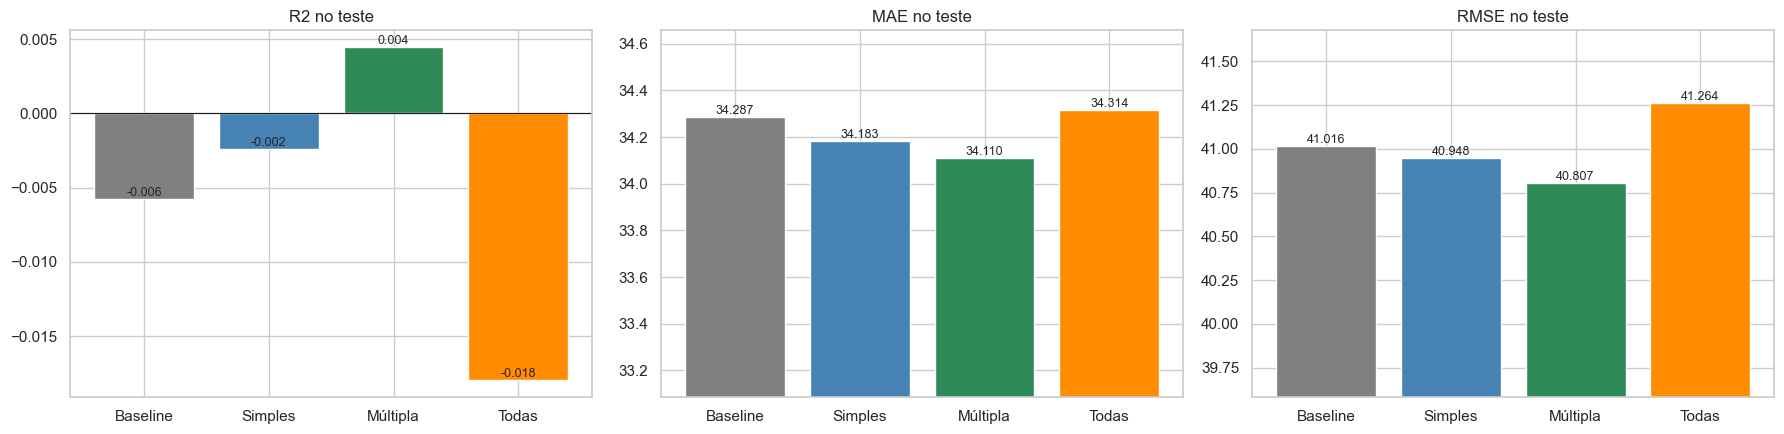

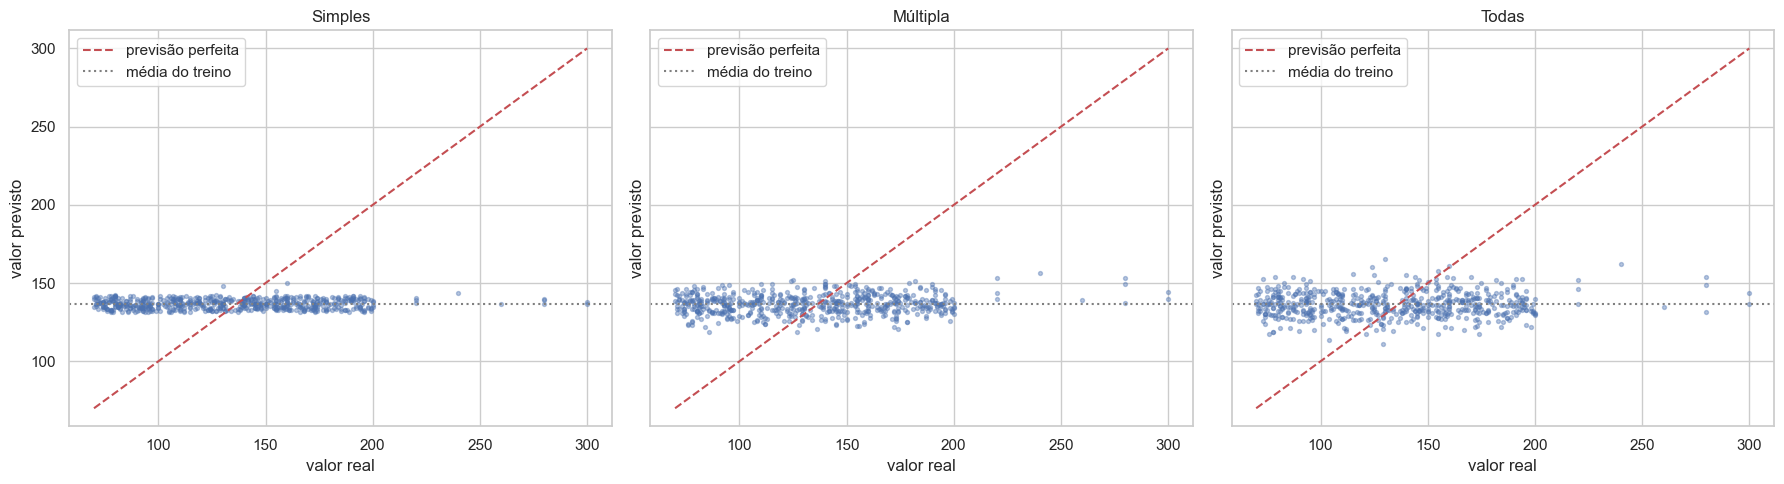

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
short = ['Baseline', 'Simples', 'Múltipla', 'Todas']
for ax, m in zip(axes, ['R2', 'MAE', 'RMSE']):
    vals = results[f'teste_{m}'].to_numpy()
    ax.bar(short, vals, color=['grey', 'steelblue', 'seagreen', 'darkorange'])
    ax.set_title(f'{m} no teste'); ax.axhline(0, color='k', lw=.8)
    for i, v in enumerate(vals): ax.text(i, v, f'{v:.3f}', ha='center', va='bottom', fontsize=9)
    if m != 'R2': ax.set_ylim(vals.min() * 0.97, vals.max() * 1.01)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, name, s in zip(axes, names[1:], short[1:]):
    ax.scatter(y_test, preds[name], s=8, alpha=.4)
    lims = [y_test.min(), y_test.max()]; ax.plot(lims, lims, 'r--', label='previsão perfeita')
    ax.axhline(y_train.mean(), color='grey', ls=':', label='média do treino')
    ax.set_xlabel('valor real'); ax.set_ylabel('valor previsto'); ax.set_title(s); ax.legend()
plt.tight_layout(); plt.show()

**Conclusões:**
- **Barras:** os quatro modelos têm métricas praticamente iguais (MAE entre 34.1 e 34.4; RMSE entre 40.8 e 41.3).
  As escalas dos gráficos de MAE e RMSE foram ampliadas para as diferenças serem visíveis; numa escala a partir de
  zero, as barras seriam indistinguíveis.
- **Previstos vs reais:** em vez de seguirem a diagonal vermelha, as previsões formam uma **faixa horizontal** à
  volta da média do treino (~137). Os pacientes com target 70 e os pacientes com target 300 recebem previsões
  semelhantes.

**Justificação:** é a imagem de um modelo que não encontrou nas features informação para distinguir pacientes. O
modelo múltiplo "abre" um pouco mais a faixa do que o simples, mas continua longe da diagonal.

### 8.4 Porque é que nenhuma feature explica o target? Um olhar final sobre `target_regression`

Antes da discussão, voltamos ao próprio target para perceber **de onde vem** a sua variação. Os gráficos de
valores reais vs previstos (6.5) sugerem que quase todos os valores estão espalhados de forma regular entre 70 e
200, com poucos valores acima. Verificamos:
- se, entre 70 e 200, a distribuição é compatível com uma **uniforme** (teste de Kolmogorov-Smirnov);
- quantos valores ficam acima de 200 e em que classe diagnóstica estão (uso apenas descritivo de `target_class`,
  como na EDA; não entra em nenhum modelo).

Valores entre 70 e 200: 1957 (97.9%) | KS vs uniforme(70, 200): D = 0.038, p = 0.00706
Valores acima de 200: 43 | por classe: {'DI_HY': 22, 'DI_HT': 21}
Proporcao de cada classe com target > 200: {'DI_HT': 0.247, 'DI_HY': 0.012, 'HT': 0.0}


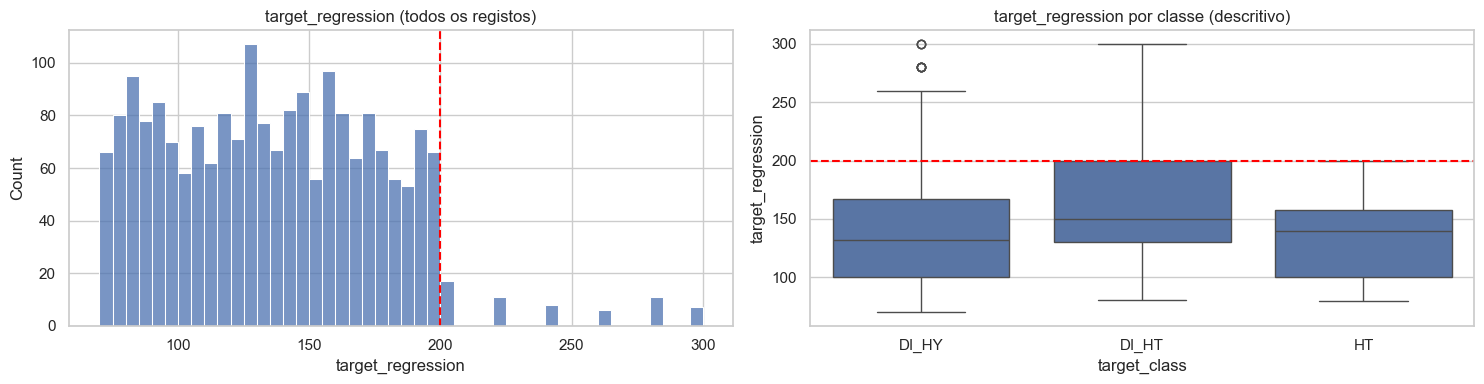

In [51]:
t = raw[TARGET]
inside = t[t <= 200]
ks_u = stats.kstest(inside, stats.uniform(loc=70, scale=130).cdf)
print(f'Valores entre 70 e 200: {len(inside)} ({len(inside)/len(t):.1%}) | KS vs uniforme(70, 200): '
      f'D = {ks_u.statistic:.3f}, p = {ks_u.pvalue:.3g}')
high = raw[t > 200]
print(f'Valores acima de 200: {len(high)} | por classe: {high.target_class.value_counts().to_dict()}')
print(f'Proporcao de cada classe com target > 200: '
      f'{(high.target_class.value_counts() / raw.target_class.value_counts()).fillna(0).round(3).to_dict()}')

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(t, bins=46, ax=axes[0]); axes[0].axvline(200, color='red', ls='--')
axes[0].set_title('target_regression (todos os registos)')
sns.boxplot(data=raw, x='target_class', y=TARGET, ax=axes[1]); axes[1].axhline(200, color='red', ls='--')
axes[1].set_title('target_regression por classe (descritivo)')
plt.tight_layout(); plt.show()

**Conclusões:**
- **97.9%** dos valores do target estão entre 70 e 200, com uma distribuição **quase uniforme** (histograma plano).
  O teste KS rejeita a uniformidade perfeita (p = 0.007), mas a distância é pequena (D = 0.038). Com quase 2000
  valores, até desvios mínimos ficam "significativos".
- Apenas **43 valores (2.1%) passam os 200**, e concentram-se na classe `DI_HT`: **24.7% dos pacientes `DI_HT`**
  têm target > 200, contra 1.2% de `DI_HY` e 0% de `HT`.

**Justificação - o que isto explica:**
1. **Um target uniforme, sem relação com as features, é o pior cenário para uma regressão.** Num intervalo de 70 a
   200, todos os valores são igualmente prováveis para qualquer paciente, seja qual for o seu BMI, idade ou
   colesterol. Não há nada que o modelo possa aprender.
2. **A pouca estrutura que existe está ligada à classe diagnóstica** (valores altos em `DI_HT`), que não podemos
   usar como preditor. Isto explica também porque a EDA encontrou em `target_class` a variável mais associada ao
   target (η² ≈ 0.027).
3. Distribuições "planas" já tinham sido observadas em muitas features na EDA (Parte 1, secção 2.2). Reforça a hipótese de
   dados **sintéticos**, em que o target terá sido gerado de forma praticamente independente das features.

## 9. Comparação, discussão e conclusões

### 9.1 Comparação dos dois modelos

| | **Regressão Linear Simples** | **Regressão Linear Múltipla** |
|---|---|---|
| Features | `bmi` | `bmi`, `age`, `smoking`, `salt_intake`, `triglycerides`, `physical_activity`, `HbA1c_level` |
| Como foram escolhidas | Melhor de 30 features, testadas uma a uma | Construção incremental, confirmada por 286 combinações e 9 grupos clínicos |
| R² treino | 0.0055 | 0.0233 |
| R² teste | −0.002 | **0.005** |
| MAE teste | 34.18 | **34.11** |
| RMSE teste | 40.95 | **40.81** |
| Diferença de RMSE face à baseline (IC95%) | −0.07 [−0.29, +0.15] | −0.19 [−0.74, +0.32] |
| Significância | *t*: p = 0.006 | *F*: p = 2.8×10⁻⁵ |

**A regressão múltipla é ligeiramente melhor** nas três métricas, em validação cruzada e no teste. Ao juntar várias
features fracas e independentes, acumula pequenos contributos: o R² de treino é 4 vezes maior que o da simples.

**Mas nenhum dos dois modelos é útil na prática.** Ambos erram, em média, cerca de 34 unidades, praticamente o
mesmo que prever sempre a média (34.29). As diferenças não são estatisticamente robustas.

### 9.2 Discussão: o resultado faz sentido?

**Sim, e era previsível a partir da EDA.** A cadeia de raciocínio é a seguinte:

1. **A EDA mostrou que a melhor correlação com o target é r ≈ 0.07 (`bmi`).** Na regressão simples, R² = r², por isso
   o limite era 0.0055 (0.55%). O modelo atingiu exatamente esse valor (secções 6.1 e 6.2).
2. **As features são independentes entre si**, por isso, na regressão múltipla, os R² individuais somam-se
   aproximadamente. Somando os contributos das ~7 melhores features (todos abaixo de 0.6%) obtém-se ~2%, que foi o
   resultado obtido (7.8).
3. **As features que mais ajudam são as que têm maior |r| e estão acima do ruído** (`bmi`, `age`). As que pioram o
   modelo são as que, na EDA e no teste do ruído (6.3), não se distinguem de números aleatórios (`hdl`,
   `alcohol_intake`, `heart_rate`…).
4. **Mais features não é melhor.** Com 30 features o modelo memoriza ruído do treino (*overfitting*) e fica pior do
   que a média em dados novos (7.5 e 8.1).
5. **A forma do modelo não é o problema.** Os resíduos não mostram curvatura; polinómios e `log1p` não trazem
   ganhos robustos (6.7 e 7.7).
6. **O próprio target explica o resultado.** É quase uniforme entre 70 e 200 e só os valores raros acima de 200 têm
   alguma ligação, à classe `DI_HT` (8.4). Não há estrutura nas features para o modelo aprender.

**Paralelo com a classificação:** na EDA vimos que `target_class` é dominada por `DI_HY` (90%), e um classificador
sem boas features tenderá a prever quase sempre essa classe. Aqui acontece o equivalente na regressão: **sem
features informativas, o modelo de mínimos quadrados converge para a média** e prevê ~137 para quase todos os
pacientes (6.5, 8.3). Em ambos os casos, a comparação com a *baseline* (classe maioritária / média) é obrigatória
para não sobrestimar o modelo.

**Significância estatística ≠ capacidade de previsão.** Vários coeficientes têm p < 0.05 e o teste *F* do modelo
múltiplo é altamente significativo (p = 2.8×10⁻⁵). Com 1400 registos, até efeitos minúsculos se distinguem de
zero. O p-value diz que o efeito provavelmente **existe**; o R², o MAE e o RMSE dizem que é **demasiado pequeno**
para prever.

### 9.3 Conclusões
- **Regressão simples:** `target_regression = 125.06 + 0.425 × bmi`. O `bmi` é a melhor feature isolada em todos
  os critérios, mas explica apenas 0.55% da variância.
- **Regressão múltipla:** 7 features (`bmi`, `age`, `smoking`, `salt_intake`, `triglycerides`, `physical_activity`,
  `HbA1c_level`), que explicam cerca de 2% da variância. O trio `bmi` + `age` + `HbA1c_level` é uma alternativa
  quase equivalente e mais simples.
- **Desempenho no teste:** R² ≈ 0, MAE ≈ 34, RMSE ≈ 41. **Nenhum modelo prevê melhor do que a média** de forma
  estatisticamente robusta.
- **É um resultado negativo, mas válido:** foi obtido com uma metodologia correta (escolhas só no treino, validação
  cruzada, teste usado uma vez, *baseline*, controlo com ruído, intervalos de confiança) e é coerente com a EDA.

---

# Da Parte 2 para a Parte 3

A Parte 2 confirmou, com modelos ajustados, o que a análise exploratória tinha previsto: **o alvo
contínuo não é previsível a partir destas *features***. O melhor modelo múltiplo fica em R² = 0.005 no
teste e erra, em média, praticamente o mesmo que prever sempre a média.

A Parte 3 ataca o **outro alvo**, e o ponto de partida é bem diferente:

| | Regressão (Parte 2) | Classificação (Parte 3) |
|---|---|---|
| Alvo | `target_regression`, contínuo | `target_class`, três categorias |
| Sinal detetado na Parte 1 | \|r\| máximo de 0.07 | `HbA1c_level` com **η² = 0.410** e `triglycerides` com 0.105 (secção 3.6) |
| Dificuldade principal | ausência de sinal | **desequilíbrio**: 89.9% dos registos em `DI_HY` e apenas 85 em `DI_HT` |
| Métrica de referência | RMSE contra a média | F1 macro e *balanced accuracy* contra o classificador trivial |
| Baseline a bater | prever sempre a média | prever sempre `DI_HY`, que já dá 0.899 de *accuracy* |

Há aqui um paralelo que a Parte 2 já tinha apontado: sem *features* informativas, a regressão converge
para a média e a classificação converge para a classe maioritária. **A comparação com a *baseline* é
obrigatória nos dois casos**, e é por isso que a Parte 3 começa por calculá-la.

A Parte 3 acrescenta ainda uma dimensão que a Parte 2 não explorou: **como o método de reamostragem
afeta a confiança na estimativa**, comparando *holdout*, k-fold, LOOCV e *bootstrap*.

# Parte 3: Aplicação de métodos - Classificação

**Dataset:** `dataset_grupo_22.csv`, com 2000 perfis de pacientes. **Variável a prever:** `target_class`, a categoria
diagnóstica (`DI_HY`, `HT`, `DI_HT`). O significado clínico dos códigos não é dado no enunciado.

### Objetivo (enunciado, secção 4)
1. Aplicar **Regressão Logística** e **Análise Discriminante Linear (LDA)** e **decidir qual é o método mais
   adequado**, justificando.
2. Avaliar com os métodos de reamostragem: ***holdout***, **validação cruzada (k = 5 e k = 10)**, **LOOCV** e
   ***bootstrap***.
3. Escolher métricas adequadas e **explicar como a variância é afetada pelo método de reamostragem**.

### Ponto de partida: o que a EDA já nos disse
| Resultado da EDA | Consequência para a classificação |
|---|---|
| `target_class` é **muito desequilibrada**: 89.9% `DI_HY`, 5.85% `HT`, 4.25% `DI_HT` | Um modelo sem cuidados tende a prever quase sempre `DI_HY`. A *accuracy* engana; são precisas métricas por classe e **estratificação** na reamostragem. |
| `HbA1c_level` separa fortemente `HT` das outras classes (η² = 0.41); `triglycerides` separa `DI_HY` das minoritárias (η² = 0.105) | Esperamos que `HT` seja relativamente fácil de identificar e que estas sejam as features com mais peso. |
| `DI_HT` e `DI_HY` sobrepõem-se muito | `DI_HT` deve ser a classe mais difícil. |
| As distribuições são pouco "normais" (uniformes, assimétricas, caudas longas) | Os pressupostos da LDA podem não se verificar (verificamos em 11.1). |
| Artefacto de precisão decimal ligado à classe | Logística e LDA usam o valor numérico de forma linear e não exploram as casas decimais; não criamos features a partir delas. |

## 10. Preparação dos dados

### 10.1 Carregamento dos dados e preparação do ambiente

Carregamos o dataset original (sem o alterar) e fixamos a semente aleatória em **22** (regra do projeto), para que
todas as divisões dos dados, validações cruzadas e reamostragens *bootstrap* sejam reprodutíveis.

In [52]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, StratifiedKFold, LeaveOneOut
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, recall_score,
                             precision_score, confusion_matrix, classification_report, ConfusionMatrixDisplay)

SEED = 22
np.random.seed(SEED)
pd.set_option('display.float_format', '{:.3f}'.format)
pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid')

dataset_name = 'dataset_grupo_22.csv'
dataset_path = next(p for p in [Path.cwd() / dataset_name, Path.cwd().parent / dataset_name] if p.is_file())
raw = pd.read_csv(dataset_path)
print('Dimensao do dataset:', raw.shape)
raw['target_class'].value_counts().to_frame('n').assign(**{'%': lambda d: d['n'] / len(raw) * 100})

Dimensao do dataset: (2000, 35)


,n,%
target_class,,
DI_HY,1798,89.900
HT,117,5.850
DI_HT,85,4.250


**Conclusões:** o dataset tem **2000 registos**: 1798 `DI_HY` (89.9%), 117 `HT` (5.85%) e **apenas 85 `DI_HT`
(4.25%)**. A classe maioritária é 21 vezes maior que a mais pequena. Este número vai condicionar tudo o que se segue:
a escolha das métricas, a necessidade de estratificar e o comportamento dos modelos.

### 10.2 Remoção de features, codificação e matriz de preditores

Aplicamos **a mesma preparação do notebook da regressão**, pelas mesmas razões (EDA, `01_EDA`):
- removemos `calcium_baseline` (constante), `systolic_index` (cópia de `systolic_bp`) e `age_normalized` (reescala
  de `age`). Estas duas últimas tornariam a matriz de covariâncias **singular**, o que é um problema direto para a
  LDA, que tem de inverter essa matriz;
- removemos também `ldl_alternative`: tem os mesmos valores de `ldl`, mas trocados entre pacientes (coincide em só
  18 de 2000 linhas). O valor não pertence ao paciente da linha, por isso é ruído;
- convertemos as categóricas em números (ordinais → 0, 1, 2…; binárias → 0/1; `employment_status` → *one-hot*);
- **retiramos os dois targets dos preditores**: `target_class` é o que queremos prever e `target_regression` é o
  outro resultado do trabalho.

As restantes 30 features ficam todas. A seleção de features é o tema da Parte 4 (Ridge/Lasso); aqui o objetivo é
comparar métodos de classificação e de reamostragem nas mesmas condições.

In [53]:
TARGET = 'target_class'
CLASSES = ['DI_HY', 'HT', 'DI_HT']          # ordem fixa: maioritária -> minoritárias
DROP_EDA = ['calcium_baseline', 'systolic_index', 'age_normalized', 'ldl_alternative']
ORDINAL = {
    'age_level': ['Young', 'Middle', 'Mature', 'Senior'],
    'bmi_level': ['Underweight', 'Normal', 'Overweight', 'Obese'],
    'smoking': ['Never', 'Former', 'Current'],
    'physical_activity': ['Low', 'Moderate', 'High'],
    'stress_level': ['Low', 'Medium', 'High'],
    'sugar_consumption': ['Low', 'Medium', 'High'],
    'education_level': ['Primary', 'Secondary', 'Tertiary'],
}
BINARY = {'gender': 'Male', 'family_history': 'Yes', 'low_hdl_cholesterol': 'Yes', 'high_ldl_cholesterol': 'Yes'}

data = raw.drop(columns=DROP_EDA).copy()
for col, levels in ORDINAL.items():
    data[col] = data[col].map({lvl: i for i, lvl in enumerate(levels)})
for col, positive in BINARY.items():
    data[col] = (data[col] == positive).astype(int)
data = pd.get_dummies(data, columns=['employment_status'], drop_first=True, dtype=int)

X = data.drop(columns=[TARGET, 'target_regression'])
y = data[TARGET]
assert X.isna().sum().sum() == 0
FEATURES = list(X.columns)
print(f'{X.shape[0]} registos x {len(FEATURES)} features')

2000 registos x 30 features


**Conclusões:** ficam **30 features** para os 2000 registos, sem valores em falta. Com cerca de 67 registos por
feature, há dados suficientes para estimar uma Regressão Logística ou uma LDA com covariância comum.

Ainda assim, a classe `DI_HT` tem só 85 pacientes. Isto inviabiliza, por exemplo, uma **QDA**: teria de estimar uma
matriz de covariâncias 30×30 (465 parâmetros) só com esses 85 pacientes, e a estimativa ficaria muito instável. É
uma das razões para nos ficarmos pelos dois métodos pedidos.

### 10.3 Métricas de avaliação: porque não basta a *accuracy*

A EDA mostrou que `target_class` é **muito desequilibrada** (≈ 90% `DI_HY`). Nestas condições, a *accuracy* engana:
um modelo que responda sempre `DI_HY` acerta em ≈ 90% dos casos sem ter aprendido nada. Usamos por isso as seguintes
métricas, adaptadas a 3 classes:

| Métrica | O que mede | Porque é útil aqui |
|---|---|---|
| **Recall por classe** | Dos pacientes de cada classe, quantos foram bem identificados | Mostra diretamente se as classes raras (`HT`, `DI_HT`) estão a ser detetadas |
| **Precision por classe** | Das previsões de cada classe, quantas estão certas | Mostra o custo de "inventar" diagnósticos |
| **F1 macro** (métrica principal) | Média simples do F1 das 3 classes | Cada classe pesa o mesmo, por isso falhar uma classe rara baixa muito a métrica |
| **Balanced accuracy** | Média simples dos recalls das 3 classes | Um modelo que prevê sempre a maioritária fica em 1/3 = 0.333 |
| *Accuracy* | Proporção de acertos | Só como referência secundária |
| **Matriz de confusão** | Que classes são confundidas com quais | Diagnóstico detalhado dos erros |

Para tornar isto concreto, avaliamos um **classificador de referência** (*baseline*) que prevê sempre a classe
maioritária.

In [54]:
def metrics(y_true, y_pred):
    rec = recall_score(y_true, y_pred, labels=CLASSES, average=None, zero_division=0)
    return {'f1_macro': f1_score(y_true, y_pred, labels=CLASSES, average='macro', zero_division=0),
            'bal_acc': balanced_accuracy_score(y_true, y_pred),
            'accuracy': accuracy_score(y_true, y_pred),
            **{f'recall_{c}': r for c, r in zip(CLASSES, rec)}}

baseline_pred = np.full(len(y), 'DI_HY')
pd.Series(metrics(y, baseline_pred), name='baseline (sempre DI_HY)').to_frame().T

,f1_macro,bal_acc,accuracy,recall_DI_HY,recall_HT,recall_DI_HT
baseline (sempre DI_HY),0.316,0.333,0.899,1.000,0.000,0.000


**Conclusões:** o classificador que responde sempre `DI_HY` tem **accuracy de 0.899**, o que parece um bom
resultado. Mas não identifica **nenhum** paciente `HT` nem `DI_HT` (recall = 0), e por isso tem:
- **F1 macro = 0.316**;
- **balanced accuracy = 0.333** (= 1/3).

**Justificação:** é a prova numérica de que a *accuracy* não serve como métrica principal neste problema. Daqui em
diante, a métrica principal é o **F1 macro**, complementado pela **balanced accuracy** e pelo **recall de cada
classe**. Qualquer modelo útil tem de ficar claramente acima de 0.316 e 0.333.

## 11. Regressão Logística vs LDA

**Regressão Logística:** modela diretamente a probabilidade de cada classe,
$P(Y=k \mid X) = \frac{e^{\beta_{k0} + \beta_k^T x}}{\sum_j e^{\beta_{j0} + \beta_j^T x}}$ (versão multinomial),
com os coeficientes estimados por **máxima verosimilhança**. **Não assume nada** sobre a distribuição das features.

**LDA:** modela a distribuição das features **dentro de cada classe** como normal multivariada, com uma **matriz de
covariâncias comum**, e usa o teorema de Bayes, $P(Y=k \mid X) \propto \pi_k \, f_k(x)$, onde $\pi_k$ é a
probabilidade a priori da classe. As fronteiras de decisão são lineares.

**Estratégia:**
1. verificar se os pressupostos da LDA se verificam nos nossos dados (11.1);
2. ajustar os dois métodos sem ajustes e ver o efeito do desequilíbrio (11.2);
3. corrigir o desequilíbrio e comparar (11.3);
4. testar se as diferenças são estatisticamente significativas (11.4).

### 11.1 Os pressupostos da LDA verificam-se?

A LDA assume que, **dentro de cada classe**, as features seguem uma distribuição **normal** e que
**todas as classes têm a mesma matriz de covariâncias**. A Regressão Logística não faz estas suposições. Saber se os
pressupostos se verificam ajuda a perceber qual dos métodos deve funcionar melhor.

Verificamos, para as features mais discriminativas da EDA:
- a **normalidade dentro de cada classe** (teste de Shapiro-Wilk e assimetria);
- a **igualdade das variâncias entre classes** (teste de Levene e rácio entre o maior e o menor desvio padrão).

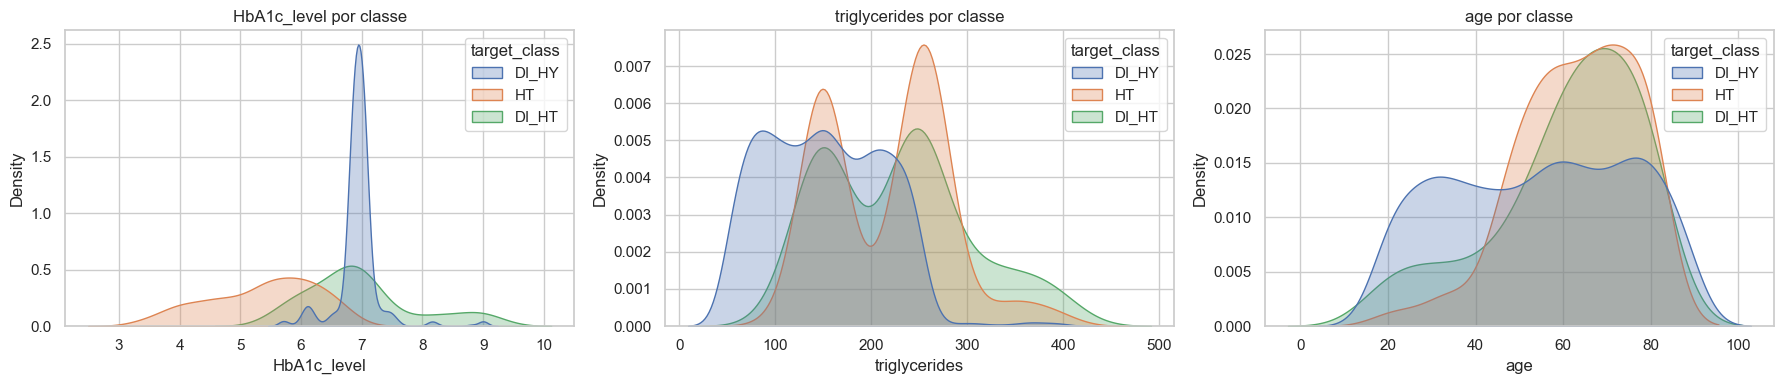

,std_DI_HY,std_HT,std_DI_HT,racio_std (max/min),p_Levene,skew_DI_HY,p_Shapiro_DI_HY
feature,,,,,,,
HbA1c_level,0.359,0.868,0.907,2.528,0.000,1.368,0.000
triglycerides,61.097,63.418,75.080,1.229,0.072,0.311,0.000
age,20.662,13.346,16.871,1.548,0.000,-0.080,0.000
bmi,7.285,6.013,5.819,1.252,0.000,0.086,0.000
blood_pressure,4.416,8.181,11.553,2.616,0.000,-0.733,0.000
crp_level,0.939,1.530,2.537,2.702,0.000,0.441,0.000


In [55]:
key = ['HbA1c_level', 'triglycerides', 'age', 'bmi', 'blood_pressure', 'crp_level']
rows = []
for f in key:
    groups = [data.loc[y == c, f] for c in CLASSES]
    stds = [g.std() for g in groups]
    rows.append({'feature': f,
                 **{f'std_{c}': s for c, s in zip(CLASSES, stds)},
                 'racio_std (max/min)': max(stds) / min(stds),
                 'p_Levene': stats.levene(*groups).pvalue,
                 'skew_DI_HY': stats.skew(groups[0]),
                 'p_Shapiro_DI_HY': stats.shapiro(groups[0].sample(500, random_state=SEED)).pvalue})
assumptions = pd.DataFrame(rows).set_index('feature')

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, f in zip(axes, ['HbA1c_level', 'triglycerides', 'age']):
    sns.kdeplot(data=data, x=f, hue=y, hue_order=CLASSES, common_norm=False, fill=True, alpha=.3, ax=ax)
    ax.set_title(f'{f} por classe')
plt.tight_layout(); plt.show()
assumptions

**Conclusões:** **os pressupostos da LDA não se verificam.**
- **Normalidade:** o teste de Shapiro-Wilk rejeita a normalidade (p < 0.001) em todas as features testadas. Os
  gráficos mostram distribuições claramente não normais, por exemplo `HbA1c_level` muito concentrada em `DI_HY`
  (assimetria 1.37) e `age` aproximadamente uniforme.
- **Covariâncias iguais:** o teste de Levene rejeita variâncias iguais entre classes em 5 das 6 features. Em
  `HbA1c_level`, o desvio padrão das classes minoritárias (≈ 0.87–0.91) é **2.5 vezes** maior que o de `DI_HY`
  (0.36); em `blood_pressure` e `crp_level` o rácio também passa de 2.6.

**O que isto implica:** à partida, estas violações favorecem a Regressão Logística, que não depende destes
pressupostos. No entanto, a LDA é conhecida por ser **robusta** a violações moderadas: as suas fronteiras de decisão
continuam a ser lineares e podem funcionar bem, mesmo que as probabilidades estimadas não sejam exatas. Por isso, a
decisão entre os dois métodos tem de ser feita pelos **resultados**, e não apenas pela teoria.

Os gráficos confirmam também a EDA: `HbA1c_level` separa bem `HT` (valores mais baixos), `triglycerides` desloca
`HT` e `DI_HT` para valores mais altos, e as curvas de `DI_HT` e `DI_HY` sobrepõem-se muito.

### 11.2 Primeiro ajuste: Regressão Logística e LDA "tal como vêm"

Ajustamos os dois métodos com as opções por defeito do scikit-learn:
- **Regressão Logística multinomial** (generalização da logística para 3 classes, com *softmax*), estimada por máxima
  verosimilhança. As features são padronizadas (`StandardScaler`), porque o scikit-learn aplica por
  defeito uma pequena regularização que depende da escala;
- **LDA**, que estima as médias de cada classe, uma covariância comum e as **probabilidades a priori** πₖ a partir
  das proporções das classes no treino.

Para não depender de uma única divisão dos dados, usamos **validação cruzada estratificada 10-fold**: cada paciente
recebe uma previsão feita por um modelo que nunca o viu. É o método de reamostragem padrão; a secção 12 compara-o com
os outros.

**Hipótese a testar:** como ~90% dos pacientes são `DI_HY`, esperamos que os modelos sem ajuste prevejam
`DI_HY` na maioria dos casos e falhem as classes minoritárias.

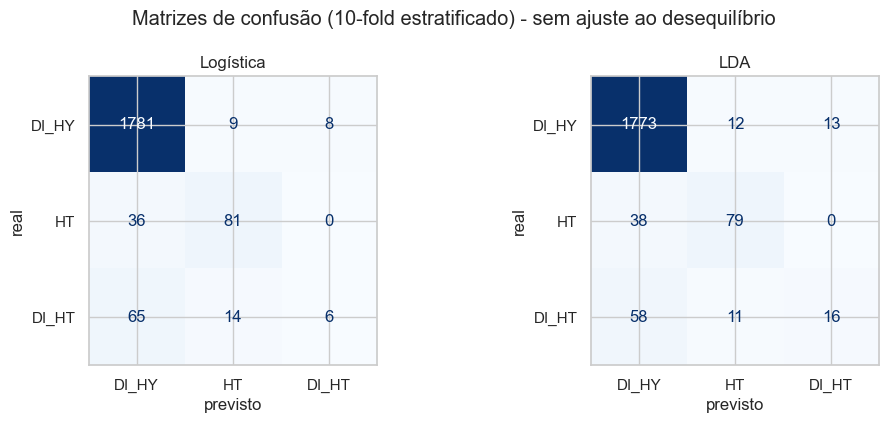

,f1_macro,bal_acc,accuracy,recall_DI_HY,recall_HT,recall_DI_HT
Logística,0.607,0.584,0.934,0.991,0.692,0.071
LDA,0.656,0.617,0.934,0.986,0.675,0.188
baseline (sempre DI_HY),0.316,0.333,0.899,1.000,0.000,0.000


In [56]:
MODELS = {
    'Logística':          lambda: LogisticRegression(max_iter=5000),
    'LDA':                lambda: LinearDiscriminantAnalysis(),
    'Logística (pesos)':  lambda: LogisticRegression(max_iter=5000, class_weight='balanced'),
    'LDA (priors iguais)': lambda: LinearDiscriminantAnalysis(priors=[1/3] * 3),
}

def ajustar(fabrica, X_tr, y_tr):
    """Padroniza com as estatisticas do treino e ajusta o modelo.
    Escrito a mao em vez de um Pipeline, para a padronizacao ficar dentro de cada particao."""
    escala = StandardScaler().fit(X_tr)
    modelo = fabrica().fit(escala.transform(X_tr), y_tr)
    return lambda X_novo: modelo.predict(escala.transform(X_novo))

def prever_por_cv(fabrica, cv):
    """Equivalente manual ao cross_val_predict: cada observacao e prevista
    pelo modelo ajustado sem ela."""
    previsto = pd.Series(index=y.index, dtype=object)
    for idx_treino, idx_teste in cv.split(X, y):
        prever = ajustar(fabrica, X.iloc[idx_treino], y.iloc[idx_treino])
        previsto.iloc[idx_teste] = prever(X.iloc[idx_teste])
    return previsto.to_numpy()

def pontuacoes_por_fold(fabrica, cv):
    """Equivalente manual ao cross_validate: F1 macro e balanced accuracy em cada particao."""
    linhas = []
    for idx_treino, idx_teste in cv.split(X, y):
        prever = ajustar(fabrica, X.iloc[idx_treino], y.iloc[idx_treino])
        p = prever(X.iloc[idx_teste])
        linhas.append({'f1_macro': f1_score(y.iloc[idx_teste], p, average='macro'),
                        'bal_acc': balanced_accuracy_score(y.iloc[idx_teste], p)})
    return pd.DataFrame(linhas)
CV10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

def show_confusions(names, preds, title):
    fig, axes = plt.subplots(1, len(names), figsize=(5.2 * len(names), 4.3))
    for ax, n in zip(np.atleast_1d(axes), names):
        ConfusionMatrixDisplay(confusion_matrix(y, preds[n], labels=CLASSES), display_labels=CLASSES).plot(
            ax=ax, cmap='Blues', colorbar=False)
        ax.set_title(n); ax.set_xlabel('previsto'); ax.set_ylabel('real')
    fig.suptitle(title); plt.tight_layout(); plt.show()

cv_preds = {n: prever_por_cv(m, CV10) for n, m in MODELS.items()}
show_confusions(['Logística', 'LDA'], cv_preds, 'Matrizes de confusão (10-fold estratificado) - sem ajuste ao desequilíbrio')
first = pd.DataFrame({n: metrics(y, cv_preds[n]) for n in ['Logística', 'LDA']}).T
first.loc['baseline (sempre DI_HY)'] = metrics(y, baseline_pred)
first

**Conclusões: a hipótese confirma-se.** Sem ajustes, os dois modelos preveem quase sempre `DI_HY`.

| | F1 macro | Bal. acc. | Accuracy | Recall `DI_HY` | Recall `HT` | Recall `DI_HT` |
|---|---|---|---|---|---|---|
| Baseline (sempre `DI_HY`) | 0.316 | 0.333 | 0.899 | 1.000 | 0.000 | 0.000 |
| Logística | 0.607 | 0.584 | 0.934 | 0.991 | 0.692 | **0.071** |
| LDA | **0.656** | **0.617** | 0.934 | 0.986 | 0.675 | **0.188** |

- **`DI_HY`** é reconhecida quase sempre (recall ≈ 0.99).
- **`HT`** é razoavelmente bem detetada (recall ≈ 0.68–0.69 nos dois modelos), graças a `HbA1c_level`, que separa
  bem esta classe.
- **`DI_HT`** quase nunca é detetada. A Logística acerta em apenas 6 dos 85 pacientes (7%); a LDA em 16 (19%). Na
  matriz de confusão, a maioria dos `DI_HT` aparece como `DI_HY`.
- A *accuracy* (0.93) parece excelente, mas está a medir sobretudo a classe maioritária.

**Justificação - porque é que isto acontece?** Os dois métodos procuram minimizar o erro **total**. Com 1798 `DI_HY`
contra 85 `DI_HT`, e com `DI_HT` muito sobreposta a `DI_HY` (EDA), a forma mais "barata" de errar pouco é classificar
os casos duvidosos como `DI_HY`. Na LDA isto é explícito: a probabilidade a priori de `DI_HY` é 0.90 contra 0.04 de
`DI_HT`, e a regra de Bayes favorece a classe mais frequente.

**Porque é que a LDA deteta mais `DI_HT` que a Logística?** A LDA usa a estrutura de covariâncias de todas as
classes ao mesmo tempo (as médias de cada classe e uma covariância comum). Quando uma classe tem poucos exemplos, isto
dá-lhe estimativas mais estáveis do que a Logística, que ajusta coeficientes separados para cada classe a partir dos
poucos casos disponíveis.

### 11.3 Corrigir o desequilíbrio

O problema de 11.2 tem uma causa conhecida para cada método:
- na **Regressão Logística**, a função de verosimilhança é uma soma sobre todos os pacientes. Com 1798 `DI_HY` contra
  85 `DI_HT`, errar um `DI_HT` custa quase nada no total. Com `class_weight='balanced'`, cada paciente passa a pesar
  o inverso da frequência da sua classe: um `DI_HT` passa a valer ~21 vezes um `DI_HY`;
- na **LDA**, a regra de Bayes multiplica a verosimilhança pela probabilidade a priori πₖ. Com π(`DI_HY`) = 0.90 e
  π(`DI_HT`) = 0.04, um paciente só é classificado como `DI_HT` se os dados forem muito fortes. Com
  **priors iguais** (1/3 cada), a decisão passa a depender só da semelhança com cada classe.

Comparamos as 4 versões com as mesmas partições de validação cruzada.

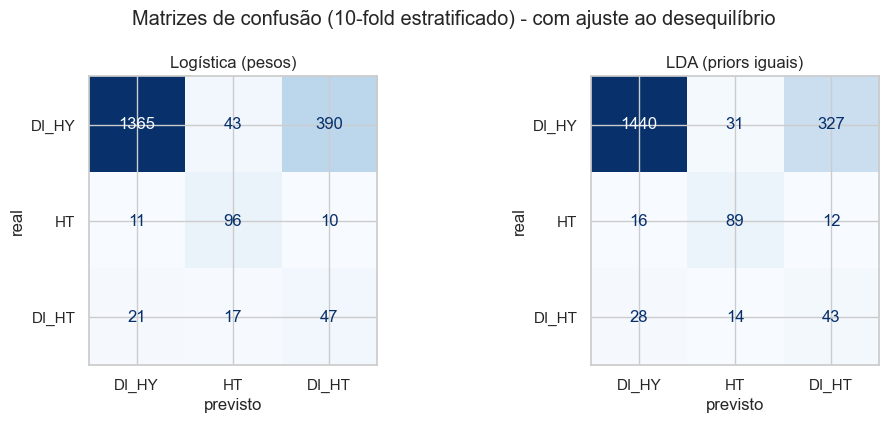

,f1_macro,bal_acc,accuracy,recall_DI_HY,recall_HT,recall_DI_HT,precision_DI_HT,n_previstos_DI_HT
Logística,0.607,0.584,0.934,0.991,0.692,0.071,0.429,14.000
LDA,0.656,0.617,0.934,0.986,0.675,0.188,0.552,29.000
Logística (pesos),0.578,0.711,0.754,0.759,0.821,0.553,0.105,447.000
LDA (priors iguais),0.590,0.689,0.786,0.801,0.761,0.506,0.113,382.000


In [57]:
show_confusions(['Logística (pesos)', 'LDA (priors iguais)'], cv_preds,
                'Matrizes de confusão (10-fold estratificado) - com ajuste ao desequilíbrio')
versions = pd.DataFrame({n: metrics(y, p) for n, p in cv_preds.items()}).T
for n, p in cv_preds.items():
    versions.loc[n, 'precision_DI_HT'] = precision_score(y, p, labels=['DI_HT'], average='macro', zero_division=0)
    versions.loc[n, 'n_previstos_DI_HT'] = (p == 'DI_HT').sum()
versions

**Conclusões:** as versões ajustadas detetam muito mais pacientes das classes minoritárias, mas pagam um preço.

| | F1 macro | Bal. acc. | Accuracy | Recall `DI_HY` | Recall `HT` | Recall `DI_HT` | Precision `DI_HT` | Nº previstos `DI_HT` |
|---|---|---|---|---|---|---|---|---|
| Logística | 0.607 | 0.584 | 0.934 | 0.991 | 0.692 | 0.071 | 0.429 | 14 |
| LDA | **0.656** | 0.617 | **0.934** | 0.986 | 0.675 | 0.188 | **0.552** | 29 |
| Logística (pesos) | 0.578 | **0.711** | 0.754 | 0.759 | **0.821** | **0.553** | 0.105 | 447 |
| LDA (priors iguais) | 0.590 | 0.689 | 0.786 | 0.801 | 0.761 | 0.506 | 0.113 | 382 |

- **Ganho:** o recall de `DI_HT` passa de 0.07 para **0.55** (Logística) e de 0.19 para **0.51** (LDA). O de `HT`
  também sobe. A *balanced accuracy* melhora muito (0.58 → 0.71 e 0.62 → 0.69).
- **Custo:** para encontrar mais `DI_HT`, os modelos passam a classificar como `DI_HT` muitos pacientes que são
  `DI_HY`. A Logística prevê 447 `DI_HT` quando só existem 85. A **precision de `DI_HT` cai para ≈ 0.11** (só 1 em
  cada 9 previsões `DI_HT` está certa) e a *accuracy* desce para 0.75–0.79.
- O **F1 macro desce ligeiramente**, porque combina recall e precision: o ganho no recall das minoritárias é
  anulado pela queda da precision de `DI_HT` e do recall de `DI_HY`.

**Justificação - porque é que não há "almoços grátis"?** As classes `DI_HT` e `DI_HY` sobrepõem-se muito (EDA).
Mudar os pesos ou as priors **não cria informação nova**: apenas desloca a fronteira de decisão. Na zona de
sobreposição, ou se perdem os `DI_HT` (versões sem ajuste) ou se apanham juntamente com muitos `DI_HY` (versões
ajustadas). É o mesmo compromisso que se obtém ao baixar o limiar de decisão de um classificador.

**Qual versão é melhor?** Depende do que custa mais errar:
- se o objetivo for **não deixar escapar** pacientes `DI_HT`/`HT` (rastreio), as versões ajustadas são preferíveis;
- se o objetivo for **não dar falsos diagnósticos**, as versões sem ajuste são preferíveis.

Como o desequilíbrio é a característica central deste problema, e o enunciado pede métricas adequadas, **comparamos
sempre os dois métodos nas duas versões** nas secções seguintes.

### 11.4 Que versão usar? Comparação com significância estatística

As diferenças entre versões podem ser pequenas. Para saber se são **reais** ou fruto de quais pacientes calharam em
cada fold, obtemos o F1 macro e a *balanced accuracy* em **cada um dos 10 folds**,
com as **mesmas partições** para todos os modelos, e aplicamos um **teste *t* emparelhado** entre modelos.

In [58]:
fold_scores = {}
for n, m in MODELS.items():
    fold_scores[n] = pontuacoes_por_fold(m, CV10)

summary = pd.DataFrame({n: {'F1 macro (média)': s.f1_macro.mean(), 'F1 macro (dp)': s.f1_macro.std(),
                            'Bal. acc. (média)': s.bal_acc.mean(), 'Bal. acc. (dp)': s.bal_acc.std()}
                        for n, s in fold_scores.items()}).T
display(summary)

pairs = [('LDA', 'Logística'), ('LDA (priors iguais)', 'Logística (pesos)'),
         ('Logística (pesos)', 'Logística'), ('LDA (priors iguais)', 'LDA')]
tests = []
for a, b in pairs:
    for met in ('f1_macro', 'bal_acc'):
        d = fold_scores[a][met] - fold_scores[b][met]
        tests.append({'comparação': f'{a}  vs  {b}', 'métrica': met, 'diferença média': d.mean(),
                      'folds em que A > B': f'{(d > 0).sum()}/10', 'p-value (t emparelhado)': stats.ttest_rel(
                          fold_scores[a][met], fold_scores[b][met]).pvalue})
pd.DataFrame(tests)

,F1 macro (média),F1 macro (dp),Bal. acc. (média),Bal. acc. (dp)
Logística,0.604,0.048,0.585,0.038
LDA,0.651,0.048,0.616,0.040
Logística (pesos),0.579,0.037,0.713,0.062
LDA (priors iguais),0.592,0.044,0.690,0.047


,comparação,métrica,diferença média,folds em que A > B,p-value (t emparelhado)
0,LDA vs Logística,f1_macro,0.047,7/10,0.054
1,LDA vs Logística,bal_acc,0.031,7/10,0.119
2,LDA (priors iguais) vs Logística (pesos),f1_macro,0.013,7/10,0.369
3,LDA (priors iguais) vs Logística (pesos),bal_acc,-0.023,3/10,0.297
4,Logística (pesos) vs Logística,f1_macro,-0.025,4/10,0.183
5,Logística (pesos) vs Logística,bal_acc,0.128,10/10,0.000
6,LDA (priors iguais) vs LDA,f1_macro,-0.059,2/10,0.043
7,LDA (priors iguais) vs LDA,bal_acc,0.074,8/10,0.017


**Conclusões:**

| Comparação | F1 macro | Balanced accuracy |
|---|---|---|
| **LDA vs Logística** (sem ajuste) | LDA +0.047, melhor em 7/10 folds, **p = 0.054** | LDA +0.031, 7/10 folds, p = 0.119 |
| **LDA (priors iguais) vs Logística (pesos)** | LDA +0.013, 7/10 folds, p = 0.369 | Logística +0.023, 7/10 folds, p = 0.297 |
| Logística (pesos) vs Logística | −0.025, p = 0.183 | **+0.128, 10/10 folds, p < 0.001** |
| LDA (priors iguais) vs LDA | **−0.059, p = 0.043** | **+0.074, p = 0.017** |

- **Sem ajuste, a LDA é melhor que a Logística no F1 macro** em 7 dos 10 folds (+0.047), mas a diferença fica **no
  limite da significância** (p = 0.054, ligeiramente acima de 0.05).
- **Com ajuste, os dois métodos ficam estatisticamente empatados**: a LDA tem um F1 macro ligeiramente superior e a
  Logística uma *balanced accuracy* ligeiramente superior, mas nenhuma das diferenças é significativa (p > 0.29).
- **O ajuste ao desequilíbrio** melhora sempre de forma significativa a *balanced accuracy* (a Logística melhora nos 10
  folds), à custa de uma pequena descida do F1 macro (significativa na LDA).

**Justificação:** um teste emparelhado compara os dois modelos **nos mesmos folds**, eliminando a variabilidade que
vem de quais pacientes calharam em cada fold. Por isso consegue detetar diferenças que as médias sozinhas não
mostram. Os desvios padrão entre folds (0.037–0.062) são da mesma ordem das diferenças entre modelos, e é por isso que
a maioria das diferenças LDA vs Logística não é significativa. Como os 10 folds partilham dados de treino, não são
totalmente independentes, e os p-values devem ser lidos como indicativos.

## 12. Métodos de reamostragem

O enunciado pede quatro formas de estimar o desempenho em pacientes novos. Todas respondem à mesma pergunta (*"que
desempenho terá o modelo em dados que nunca viu?"*), mas de maneiras diferentes, com **custo, enviesamento e
variância** diferentes.

| Método | Treino em cada repetição | Teste | Nº de modelos |
|---|---|---|---|
| *Holdout* | 70% (1400) | 30% (600), uma vez | 1 |
| *k-fold* (k = 5 / 10) | (k−1)/k dos dados (1600 / 1800) | cada fold uma vez | 5 / 10 |
| LOOCV | 1999 | 1 paciente, 2000 vezes | 2000 |
| *Bootstrap* OOB | 2000 sorteados com reposição (~63% distintos) | os ~37% que ficaram de fora | 200 |

**Cuidados comuns a todos os métodos:**
- a padronização (`StandardScaler`) está dentro de um *pipeline*, por isso é ajustada **apenas com os dados de treino
  de cada repetição**. Ajustá-la com todos os dados deixaria passar informação do teste para o treino;
- sempre que possível usamos **estratificação**, para que todas as classes estejam representadas no teste;
- avaliamos os **quatro modelos** da secção 11 com todos os métodos.

### 12.1 *Holdout* (método do conjunto de validação)

**Como funciona:** divide-se os dados uma vez em treino (70%) e teste (30%); o modelo aprende no
treino e é avaliado no teste. Usamos divisão **estratificada**, para que as 3 classes apareçam no teste nas mesmas
proporções que no dataset: com só 85 `DI_HT`, uma divisão não estratificada podia deixar o teste com muito poucos.

Mostramos o relatório completo (`classification_report`) para os quatro modelos.

In [59]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
print('Teste:', y_te.value_counts().to_dict())
holdout = {}
for n, m in MODELS.items():
    pred = ajustar(m, X_tr, y_tr)(X_te)
    holdout[n] = metrics(y_te, pred)
    if n in ('Logística (pesos)', 'LDA (priors iguais)'):
        print(f'\n=== {n} ===')
        print(classification_report(y_te, pred, labels=CLASSES, digits=3, zero_division=0))
pd.DataFrame(holdout).T

Teste: {'DI_HY': 539, 'HT': 35, 'DI_HT': 26}

=== Logística (pesos) ===
              precision    recall  f1-score   support

       DI_HY      0.969     0.800     0.876       539
          HT      0.508     0.857     0.638        35
       DI_HT      0.062     0.231     0.098        26

    accuracy                          0.778       600
   macro avg      0.513     0.629     0.538       600
weighted avg      0.902     0.778     0.828       600


=== LDA (priors iguais) ===
              precision    recall  f1-score   support

       DI_HY      0.967     0.861     0.911       539
          HT      0.588     0.857     0.698        35
       DI_HT      0.116     0.308     0.168        26

    accuracy                          0.837       600
   macro avg      0.557     0.675     0.592       600
weighted avg      0.908     0.837     0.866       600



,f1_macro,bal_acc,accuracy,recall_DI_HY,recall_HT,recall_DI_HT
Logística,0.581,0.606,0.937,0.989,0.829,0.000
LDA,0.609,0.602,0.932,0.985,0.743,0.077
Logística (pesos),0.538,0.629,0.778,0.800,0.857,0.231
LDA (priors iguais),0.592,0.675,0.837,0.861,0.857,0.308


**Conclusões:** o conjunto de teste tem 539 `DI_HY`, 35 `HT` e só **26 `DI_HT`**.

| | F1 macro | Bal. acc. | Recall `HT` | Recall `DI_HT` |
|---|---|---|---|---|
| Logística | 0.581 | 0.606 | 0.829 | **0.000** |
| LDA | 0.609 | 0.602 | 0.743 | 0.077 |
| Logística (pesos) | 0.538 | 0.629 | 0.857 | 0.231 |
| LDA (priors iguais) | **0.592** | **0.675** | 0.857 | **0.308** |

- Os relatórios mostram o mesmo padrão da secção 11: `DI_HY` e `HT` são bem identificadas (F1 de 0.88–0.91 e
  0.64–0.70), e **`DI_HT` é a classe problemática** (F1 0.10–0.17, precision 0.06–0.12).
- A Logística sem ajuste **não identifica nenhum dos 26 `DI_HT`** do teste.
- Neste *holdout* em particular, a LDA com priors iguais é a melhor nas duas métricas principais.

**Justificação - porquê desconfiar de um único *holdout*?** Os resultados diferem dos da validação cruzada (por
exemplo, o recall de `DI_HT` da Logística (pesos) é 0.23 aqui contra 0.55 em 10-fold). Com só 26 `DI_HT` no teste,
**cada paciente `DI_HT` acertado ou falhado muda o recall em ~4 pontos percentuais**. A estimativa depende muito de
quais pacientes calharam no teste, o que medimos a seguir.

### 12.2 Quanto varia o *holdout*? Repetir a divisão 100 vezes

O resultado de um *holdout* depende de **quais** pacientes calharam no teste: a estimativa tem variância, e com
outra divisão o resultado muda. Para medir essa variância, repetimos o *holdout*
estratificado com **100 sementes diferentes** e vemos como se distribuem as métricas.

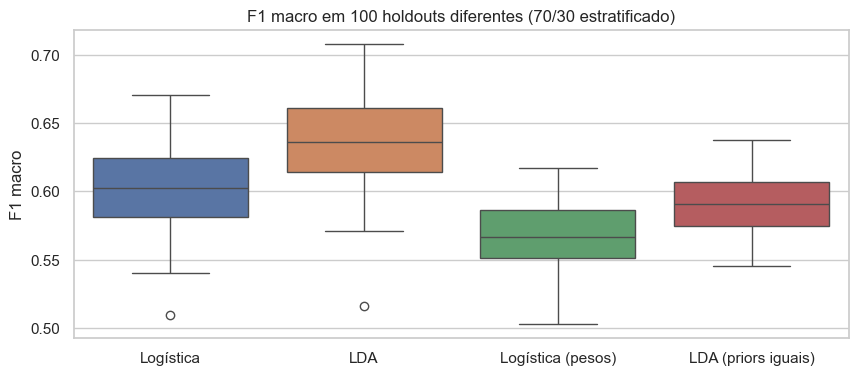

,média,dp,mín,máx,recall DI_HT dp
Logística,0.604,0.032,0.509,0.671,0.048
LDA,0.638,0.035,0.516,0.708,0.064
Logística (pesos),0.567,0.024,0.503,0.617,0.104
LDA (priors iguais),0.590,0.021,0.546,0.637,0.102


In [60]:
def repeated_holdout(model, n_rep=100, test_size=0.30):
    out = []
    for s in range(n_rep):
        a, b, c, d = train_test_split(X, y, test_size=test_size, stratify=y, random_state=s)
        out.append(metrics(d, ajustar(model, a, c)(b)))
    return pd.DataFrame(out)

rep_holdout = {n: repeated_holdout(MODELS[n]) for n in MODELS}
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=pd.DataFrame({n: r.f1_macro for n, r in rep_holdout.items()}), ax=ax)
ax.set_ylabel('F1 macro'); ax.set_title('F1 macro em 100 holdouts diferentes (70/30 estratificado)')
plt.show()
pd.DataFrame({n: {'média': r.f1_macro.mean(), 'dp': r.f1_macro.std(), 'mín': r.f1_macro.min(),
                  'máx': r.f1_macro.max(), 'recall DI_HT dp': r.recall_DI_HT.std()}
              for n, r in rep_holdout.items()}).T

**Conclusões:** repetir o *holdout* 100 vezes mostra que **a mesma metodologia dá resultados muito diferentes
consoante a divisão**:

| | F1 macro médio | Desvio padrão | Mínimo | Máximo | dp do recall `DI_HT` |
|---|---|---|---|---|---|
| Logística | 0.604 | 0.032 | 0.509 | 0.671 | 0.048 |
| LDA | 0.638 | 0.035 | 0.516 | 0.708 | 0.064 |
| Logística (pesos) | 0.567 | 0.024 | 0.503 | 0.617 | **0.104** |
| LDA (priors iguais) | 0.590 | **0.021** | 0.546 | 0.637 | **0.102** |

- O F1 macro da LDA varia entre **0.52 e 0.71** consoante a divisão: uma diferença de 0.19 só por acaso.
- O recall de `DI_HT` tem um desvio padrão de **0.10**: numa divisão pode ser 0.3 e noutra 0.6.
- O *holdout* único da secção 12.1 (0.538 para a Logística (pesos)) está **abaixo da média** das 100 repetições
  (0.567). Se só tivéssemos feito essa divisão, teríamos subestimado o modelo.

**Justificação - de onde vem esta variância?**
1. **Teste pequeno para as classes raras:** só ~26 `DI_HT` e ~35 `HT` em cada teste, por isso poucos pacientes mudam
   muito as métricas por classe.
2. **Treino reduzido:** o modelo aprende com 70% dos dados, ou seja, só ~60 `DI_HT`. Divisões diferentes produzem
   modelos diferentes.
3. **Uma única medição:** não há média de várias avaliações para "suavizar" o acaso.

Curiosamente, as versões ajustadas têm um F1 macro **mais estável** (dp 0.021–0.024) do que as não ajustadas
(0.032–0.035). Sem ajuste, o F1 de `DI_HT` depende de acertar em poucos casos, e oscila entre perto de 0 e valores
razoáveis de divisão para divisão.

### 12.3 Validação cruzada *k-fold* (k = 5 e k = 10)

**Como funciona:** os dados são divididos em *k* partes (*folds*); cada fold serve uma vez de teste
enquanto os outros *k−1* treinam o modelo. Cada paciente é testado **exatamente uma vez**. Usamos a versão
**estratificada**: com classes desequilibradas, cada fold mantém as proporções das classes.

Há **duas formas de variância** a distinguir:
1. **Entre folds:** quanto variam as *k* métricas dentro de uma mesma validação cruzada;
2. **Da estimativa:** quanto muda a **média** final se repetirmos a validação cruzada com outra partição aleatória.
   Repetimos 20 vezes, com 20 sementes.

In [61]:
def repeated_kfold(model, k, n_rep=20):
    fold_level, means = [], []
    for s in range(n_rep):
        cv = StratifiedKFold(n_splits=k, shuffle=True, random_state=s)
        r = pontuacoes_por_fold(model, cv)
        fold_level.append(r.f1_macro.to_numpy())
        means.append({'f1_macro': r.f1_macro.mean(), 'bal_acc': r.bal_acc.mean()})
    return np.concatenate(fold_level), pd.DataFrame(means)

kfold = {}
for k in (5, 10):
    for n in MODELS:
        folds, means = repeated_kfold(MODELS[n], k)
        kfold[(k, n)] = {'folds': folds, 'means': means}

kfold_table = pd.DataFrame({f'{k}-fold | {n}': {
    'F1 macro (estimativa)': v['means'].f1_macro.mean(),
    'dp entre folds': v['folds'].std(),
    'dp da estimativa (20 repetições)': v['means'].f1_macro.std(),
    'Bal. acc. (estimativa)': v['means'].bal_acc.mean()} for (k, n), v in kfold.items()}).T
kfold_table

,F1 macro (estimativa),dp entre folds,dp da estimativa (20 repetições),Bal. acc. (estimativa)
5-fold | Logística,0.608,0.039,0.010,0.586
5-fold | LDA,0.642,0.049,0.010,0.608
5-fold | Logística (pesos),0.573,0.025,0.007,0.707
5-fold | LDA (priors iguais),0.586,0.027,0.006,0.682
10-fold | Logística,0.612,0.058,0.010,0.591
10-fold | LDA,0.647,0.068,0.009,0.613
10-fold | Logística (pesos),0.575,0.038,0.004,0.709
10-fold | LDA (priors iguais),0.586,0.040,0.006,0.683


**Conclusões:**

| | Estimativa F1 macro | dp entre folds | dp da estimativa (20 rep.) | Bal. acc. |
|---|---|---|---|---|
| 5-fold · Logística (pesos) | 0.573 | 0.025 | 0.007 | 0.707 |
| 5-fold · LDA (priors iguais) | 0.586 | 0.027 | 0.006 | 0.682 |
| 10-fold · Logística (pesos) | 0.575 | 0.038 | **0.004** | 0.709 |
| 10-fold · LDA (priors iguais) | 0.586 | 0.040 | 0.006 | 0.683 |
| 10-fold · LDA (sem ajuste) | **0.647** | 0.068 | 0.009 | 0.613 |

1. **A estimativa da validação cruzada é muito mais estável que a do *holdout*.** Repetindo com outra partição, a
   média do 10-fold muda apenas 0.004–0.010 (desvio padrão), contra 0.021–0.035 no *holdout*: uma redução de
   **3 a 6 vezes**. Isto acontece porque a média de *k* avaliações cancela grande parte do acaso, e porque **todos
   os pacientes são usados como teste** uma vez.
2. **A variabilidade entre folds é maior com k = 10 do que com k = 5** (por exemplo 0.038 vs 0.025). Com k = 10, cada
   fold de teste tem só ~200 pacientes e ~8–9 `DI_HT`, por isso cada avaliação individual é mais "ruidosa".
3. **Ainda assim, a estimativa final é igual ou mais estável com k = 10**, porque é a média de mais avaliações.
4. **A estimativa sobe ligeiramente de k = 5 para k = 10** (0.573 → 0.575 na Logística (pesos)). Com k = 10 o modelo
   treina com 1800 pacientes em vez de 1600, e aprende um pouco melhor as classes raras: o k = 5 é ligeiramente mais
   **pessimista**.
5. **A ordem dos modelos mantém-se:** LDA > Logística no F1 macro, Logística (pesos) > LDA (priors iguais) na
   *balanced accuracy*.

### 12.4 *Leave-One-Out* (LOOCV)

**Como funciona:** é o caso extremo do *k-fold*, com *k = N* = 2000. Treina-se o modelo 2000 vezes,
sempre com 1999 pacientes, e testa-se no paciente que ficou de fora.

Duas particularidades importantes:
- cada fold tem **um só paciente**, por isso o "F1 de cada fold" não existe (com uma previsão só se pode acertar ou
  errar). As métricas calculam-se juntando as 2000 previsões;
- o LOOCV é **determinístico**: só há uma forma de deixar um paciente de fora de cada vez, logo repetir dá sempre o
  mesmo resultado. Também não pode ser estratificado.

In [62]:
loo_preds, loo_time = {}, {}
for n, m in MODELS.items():
    t0 = time.time()
    loo_preds[n] = prever_por_cv(m, LeaveOneOut())
    loo_time[n] = time.time() - t0
loo_table = pd.DataFrame({n: {**metrics(y, p), 'tempo (s)': loo_time[n], 'nº de modelos treinados': len(y)}
                          for n, p in loo_preds.items()}).T
loo_table

,f1_macro,bal_acc,accuracy,recall_DI_HY,recall_HT,recall_DI_HT,tempo (s),nº de modelos treinados
Logística,0.628,0.596,0.935,0.991,0.692,0.106,63.520,2000.000
LDA,0.662,0.621,0.935,0.987,0.675,0.200,12.154,2000.000
Logística (pesos),0.575,0.706,0.746,0.750,0.803,0.565,79.161,2000.000
LDA (priors iguais),0.585,0.681,0.780,0.795,0.752,0.494,11.533,2000.000


**Conclusões:**

| | F1 macro | Bal. acc. | Recall `DI_HT` | Tempo |
|---|---|---|---|---|
| Logística | 0.628 | 0.596 | 0.106 | ~64 s |
| LDA | **0.662** | 0.621 | 0.200 | ~12 s |
| Logística (pesos) | 0.575 | **0.706** | **0.565** | ~79 s |
| LDA (priors iguais) | 0.585 | 0.681 | 0.494 | ~12 s |

- Nas versões sem ajuste, o LOOCV dá as estimativas **mais altas** de todos os métodos (por exemplo LDA 0.662 vs
  0.647 em 10-fold e 0.638 no *holdout* ×100). Cada modelo treina com 1999 pacientes, quase o dataset completo, por
  isso é o método **menos pessimista (menos enviesado)**. Nas versões ajustadas, o LOOCV fica praticamente igual ao
  10-fold (0.575 e 0.585 contra 0.575 e 0.586).
- As conclusões são as mesmas: sem ajuste a LDA é melhor; com ajuste a LDA tem melhor F1 macro e a Logística melhor
  *balanced accuracy*.
- O custo foi de 12 a 79 segundos por modelo, com a **LDA 5 a 7 vezes mais rápida** do que a Logística. O ciclo de 2000 ajustes corre em série, e os tempos absolutos dependem da máquina e variam entre execuções; o rácio entre os modelos é que se mantém. Ainda assim é pouco, porque estes modelos são rápidos de treinar. Com modelos
  mais pesados, 2000 ajustes por modelo seriam proibitivos.

**Variância do LOOCV:**
- **Repetir o LOOCV dá sempre o mesmo resultado** (variância de partição = 0): só há uma forma de deixar cada
  paciente de fora.
- No entanto, **isto não significa que a estimativa seja precisa**. Os 2000 modelos são quase idênticos (diferem em
  um paciente), por isso os seus erros estão muito correlacionados. Segundo a teoria (ISLP, 5.1.4), a estimativa do
  LOOCV tem **variância elevada em relação ao verdadeiro erro**: se tivéssemos recolhido outros 2000 pacientes, o
  resultado do LOOCV podia mudar bastante.
- Também **não é possível estratificar** e não há "métrica por fold" (cada fold tem um único paciente), por isso não
  há forma de medir a dispersão a partir dos próprios resultados.

### 12.5 *Bootstrap* com avaliação *out-of-bag* (OOB)

**Como funciona:** em cada iteração tira-se uma amostra **com reposição**
do mesmo tamanho do dataset (2000). Alguns pacientes aparecem repetidos e outros ficam de fora; a probabilidade de um
paciente ficar de fora é $(1 - 1/N)^N \approx e^{-1} \approx 36.8\%$. O modelo treina com a amostra *bootstrap* e é
avaliado nos pacientes que ficaram de fora (*out-of-bag*), que nunca viu.

Repetimos **200 vezes** e obtemos a distribuição das métricas, a média, o desvio padrão e
um intervalo de confiança a 95% (percentis 2.5 e 97.5).

In [63]:
def bootstrap_oob(model, B=200, seed=SEED):
    rng = np.random.default_rng(seed)
    idx_all = np.arange(len(y))
    out = []
    for _ in range(B):
        inb = rng.choice(idx_all, size=len(y), replace=True)
        oob = np.setdiff1d(idx_all, inb)
        prever = ajustar(model, X.iloc[inb], y.iloc[inb])
        out.append({**metrics(y.iloc[oob], prever(X.iloc[oob])), 'oob_frac': len(oob) / len(y),
                    'n_DI_HT_oob': (y.iloc[oob] == 'DI_HT').sum()})
    return pd.DataFrame(out)

boot = {n: bootstrap_oob(MODELS[n]) for n in MODELS}
boot_table = pd.DataFrame({n: {'F1 macro (média)': b.f1_macro.mean(), 'dp': b.f1_macro.std(),
                               'IC95% inf': b.f1_macro.quantile(.025), 'IC95% sup': b.f1_macro.quantile(.975),
                               'Bal. acc. (média)': b.bal_acc.mean(), 'fração OOB média': b.oob_frac.mean(),
                               'nº DI_HT no OOB (média)': b.n_DI_HT_oob.mean()} for n, b in boot.items()}).T
boot_table

,F1 macro (média),dp,IC95% inf,IC95% sup,Bal. acc. (média),fração OOB média,nº DI_HT no OOB (média)
Logística,0.615,0.030,0.563,0.689,0.592,0.367,30.565
LDA,0.640,0.029,0.580,0.701,0.605,0.367,30.565
Logística (pesos),0.561,0.022,0.521,0.606,0.695,0.367,30.565
LDA (priors iguais),0.592,0.021,0.546,0.629,0.687,0.367,30.565


**Conclusões:**

| | F1 macro médio | dp | IC95% | Bal. acc. |
|---|---|---|---|---|
| Logística | 0.615 | 0.030 | [0.563, 0.689] | 0.592 |
| LDA | **0.640** | 0.029 | [0.580, 0.701] | 0.605 |
| Logística (pesos) | 0.561 | 0.022 | [0.521, 0.606] | **0.695** |
| LDA (priors iguais) | 0.592 | **0.021** | [0.546, 0.629] | 0.687 |

- A fração média de pacientes *out-of-bag* é **0.367**, exatamente o valor teórico $e^{-1} \approx 0.368$. Cada
  conjunto OOB tem em média ~31 `DI_HT`.
- O *bootstrap* devolve uma **distribuição completa** e um **intervalo de confiança** para o desempenho. Os
  intervalos da LDA e da Logística sobrepõem-se bastante, o que confirma que as diferenças entre os dois métodos são
  modestas.
- Para a Logística (pesos), a estimativa é **mais baixa** do que a do 10-fold e do LOOCV: 0.561 contra 0.575.

**Justificação - porque é que o *bootstrap* é pessimista?** Cada amostra *bootstrap* tem 2000 pacientes, mas só ~63%
são **distintos** (os outros são repetições). O modelo aprende, na prática, com ~1264 pacientes diferentes, menos que
no 5-fold (1600). Isto afeta mais a Logística, que precisa de exemplos variados das classes raras para estimar os
seus coeficientes. A LDA, que só precisa de médias e de uma covariância comum, é menos afetada (0.592 vs 0.586 no
10-fold).

## 13. Como é que o método de reamostragem afeta a variância?

Esta é a pergunta central do enunciado: *"indicate how the variance is affected by the resampling methods used"*.
Juntamos aqui os resultados das secções 12.1–12.5.

### 13.1 Comparação lado a lado

Para cada método e modelo mostramos:
- a **estimativa** do F1 macro;
- a **variabilidade das avaliações individuais** (entre divisões, folds ou iterações);
- a **variabilidade da estimativa final** (quanto muda a estimativa se o procedimento for repetido);
- o **custo** (nº de modelos treinados).

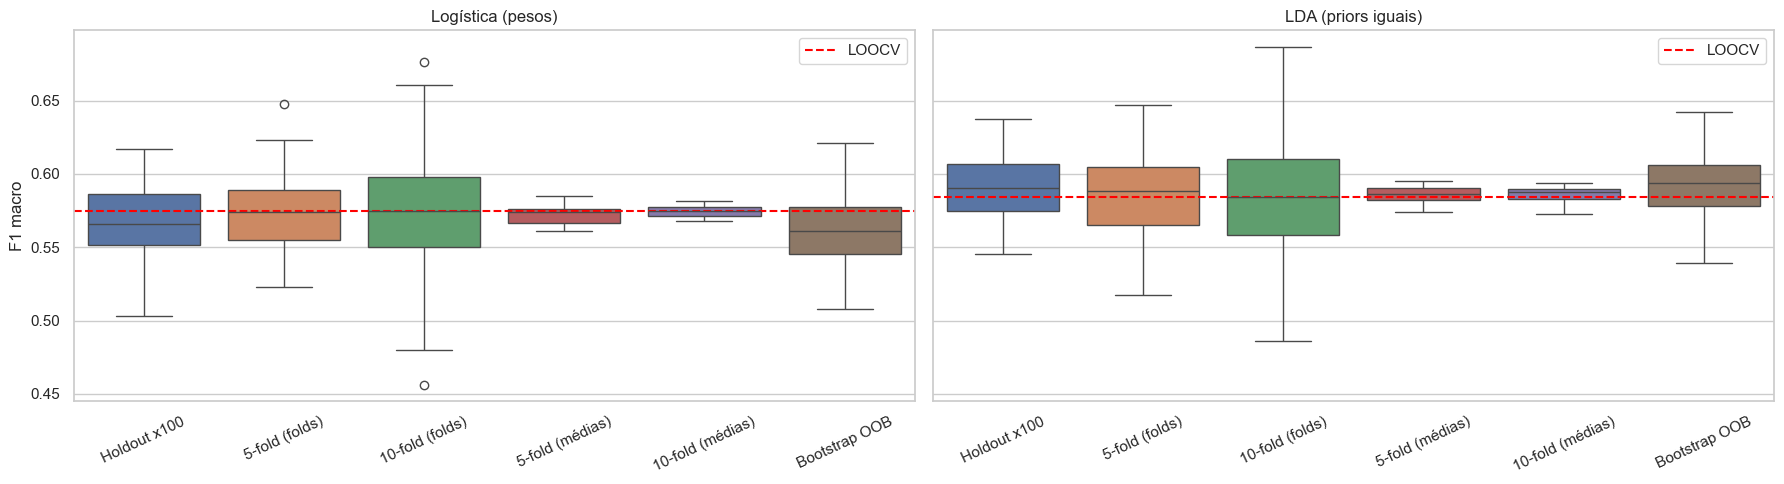

F1 macro  dp das avaliações  \
modelo              método                                               
Logística (pesos)   Holdout (1 divisão)       0.538                NaN   
                    5-fold estratificado      0.573              0.025   
                    10-fold estratificado     0.575              0.038   
                    LOOCV                     0.575                NaN   
                    Bootstrap OOB (B=200)     0.561              0.022   
LDA (priors iguais) Holdout (1 divisão)       0.592                NaN   
                    5-fold estratificado      0.586              0.027   
                    10-fold estratificado     0.586              0.040   
                    LOOCV                     0.585                NaN   
                    Bootstrap OOB (B=200)     0.592              0.021   

                                           dp da estimativa  nº modelos  
modelo              método                                               
Logística (pesos)   Holdout (1 divisão)               0.024           1  
                    5-fold estratificado              0.007           5  
                    10-fold estratificado             0.004          10  
                    LOOCV                             0.000        2000  
                    Bootstrap OOB (B=200)             0.002         200  
LDA (priors iguais) Holdout (1 divisão)               0.021           1  
                    5-fold estratificado              0.006           5  
                    10-fold estratificado             0.006          10  
                    LOOCV                             0.000        2000  
                    Bootstrap OOB (B=200)             0.001         200

In [64]:
rows = []
for n in MODELS:
    rows.append({'modelo': n, 'método': 'Holdout (1 divisão)', 'F1 macro': holdout[n]['f1_macro'],
                 'dp das avaliações': np.nan, 'dp da estimativa': rep_holdout[n].f1_macro.std(), 'nº modelos': 1})
    for k in (5, 10):
        v = kfold[(k, n)]
        rows.append({'modelo': n, 'método': f'{k}-fold estratificado', 'F1 macro': v['means'].f1_macro.mean(),
                     'dp das avaliações': v['folds'].std(), 'dp da estimativa': v['means'].f1_macro.std(), 'nº modelos': k})
    rows.append({'modelo': n, 'método': 'LOOCV', 'F1 macro': loo_table.loc[n, 'f1_macro'],
                 'dp das avaliações': np.nan, 'dp da estimativa': 0.0, 'nº modelos': len(y)})
    rows.append({'modelo': n, 'método': 'Bootstrap OOB (B=200)', 'F1 macro': boot[n].f1_macro.mean(),
                 'dp das avaliações': boot[n].f1_macro.std(),
                 'dp da estimativa': boot[n].f1_macro.std() / np.sqrt(len(boot[n])), 'nº modelos': 200})
variance = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(18, 5), sharey=True)
for ax, n in zip(axes, ['Logística (pesos)', 'LDA (priors iguais)']):
    dist = pd.DataFrame({'Holdout x100': rep_holdout[n].f1_macro,
                         '5-fold (folds)': pd.Series(kfold[(5, n)]['folds']),
                         '10-fold (folds)': pd.Series(kfold[(10, n)]['folds']),
                         '5-fold (médias)': kfold[(5, n)]['means'].f1_macro,
                         '10-fold (médias)': kfold[(10, n)]['means'].f1_macro,
                         'Bootstrap OOB': boot[n].f1_macro})
    sns.boxplot(data=dist, ax=ax); ax.axhline(loo_table.loc[n, 'f1_macro'], color='red', ls='--', label='LOOCV')
    ax.set_title(n); ax.tick_params(axis='x', rotation=25); ax.legend()
axes[0].set_ylabel('F1 macro')
plt.tight_layout(); plt.show()
variance[variance.modelo.isin(['Logística (pesos)', 'LDA (priors iguais)'])].set_index(['modelo', 'método'])

**Conclusões (versões ajustadas; as versões sem ajuste seguem o mesmo padrão):**

| Método | Estimativa F1 (Log. pesos / LDA priors) | dp das avaliações | **dp da estimativa** | Nº modelos |
|---|---|---|---|---|
| *Holdout* (1 divisão) | 0.538 / 0.592 | - | **0.024 / 0.021** | 1 |
| 5-fold estratificado | 0.573 / 0.586 | 0.025 / 0.027 | 0.007 / 0.006 | 5 |
| 10-fold estratificado | 0.575 / 0.586 | 0.038 / 0.040 | 0.004 / 0.006 | 10 |
| LOOCV | 0.575 / 0.585 | - | 0 (determinístico) | 2000 |
| *Bootstrap* OOB (B = 200) | 0.561 / 0.592 | 0.022 / 0.021 | 0.002 / 0.001 | 200 |

*O "dp da estimativa" do bootstrap é o erro padrão da média das 200 iterações ($dp/\sqrt{200}$).*

**Como é que o método de reamostragem afeta a variância?**

1. ***Holdout*: a estimativa com mais variância.** É uma única medição num teste de 600 pacientes com ~26 `DI_HT`. A
   divisão sozinha pode mudar o F1 macro em ±0.04–0.05 (dois desvios padrão). Como vimos, o *holdout* único ficou
   abaixo da média das repetições.
2. ***k-fold*: variância muito menor**, porque cada paciente é testado uma vez e o resultado é a média de *k*
   avaliações. A estimativa é **3 a 6 vezes mais estável** do que a do *holdout*. Cada fold individual varia mais
   com *k* maior (folds de teste mais pequenos), mas a média fica mais estável.
3. **LOOCV: sem variância de partição** (é determinístico), mas os 2000 modelos treinados são quase iguais e os seus
   erros estão correlacionados. A estimativa tem pouco enviesamento, mas **variância elevada em relação ao verdadeiro
   erro**, e não pode ser medida a partir dos próprios resultados.
4. ***Bootstrap*: a variância de cada iteração é semelhante à de um *holdout*** (dp 0.021–0.030), mas ao fazer a média
   de 200 iterações a estimativa final fica muito estável. É o único método que dá diretamente um **intervalo de
   confiança**. O custo é ser **pessimista**, porque cada modelo treina com só ~63% de pacientes distintos.

**O gráfico** mostra isto visualmente: as caixas das avaliações individuais (*holdout* ×100, folds, *bootstrap*) são
largas, e as das **médias** do 5-fold e do 10-fold são muito estreitas.

**Enviesamento:** quanto menos dados o modelo usa para treinar, mais pessimista é a estimativa. A ordem das
estimativas da Logística (pesos) segue essa lógica: *bootstrap* (~63% de pacientes distintos) 0.561 < 5-fold (80%)
0.573 < 10-fold (90%) 0.575 ≈ LOOCV (99.95%) 0.575. O *holdout* (70%) ficou ainda mais abaixo (0.538) por azar da
divisão. A partir de ~90% dos dados de treino, a estimativa praticamente estabiliza.

### 13.2 O efeito de *k* na validação cruzada

A escolha de *k* envolve um compromisso:
- ***k* pequeno** → cada modelo treina com menos dados → estimativa **pessimista** (mais enviesada), mas mais
  estável e mais barata;
- ***k* grande** (no limite, LOOCV) → treino quase com todos os dados → estimativa **pouco enviesada**, mas os
  modelos são muito parecidos entre si e o custo cresce.

Medimos, para *k* ∈ {2, 3, 5, 10, 20}, a estimativa média, a variabilidade **entre folds** e a variabilidade **da
estimativa** (10 repetições com sementes diferentes), para a versão ponderada de cada modelo.

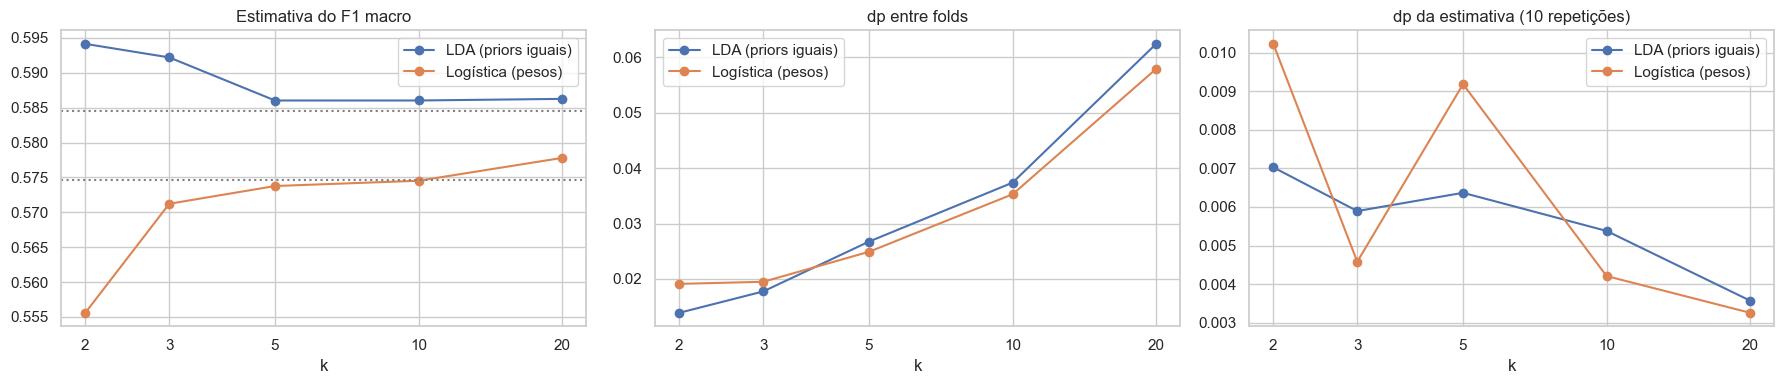

tamanho do treino  DI_HT por fold de teste  F1 macro  \
modelo              k                                                          
Logística (pesos)   2                1000                   42.500     0.556   
                    3                1333                   28.300     0.571   
                    5                1600                   17.000     0.574   
                    10               1800                    8.500     0.575   
                    20               1900                    4.200     0.578   
LDA (priors iguais) 2                1000                   42.500     0.594   
                    3                1333                   28.300     0.592   
                    5                1600                   17.000     0.586   
                    10               1800                    8.500     0.586   
                    20               1900                    4.200     0.586   

                        dp entre folds  dp da estimativa  
modelo              k                                     
Logística (pesos)   2            0.019             0.010  
                    3            0.019             0.005  
                    5            0.025             0.009  
                    10           0.035             0.004  
                    20           0.058             0.003  
LDA (priors iguais) 2            0.014             0.007  
                    3            0.018             0.006  
                    5            0.027             0.006  
                    10           0.037             0.005  
                    20           0.062             0.004

In [65]:
k_rows = []
for n in ['Logística (pesos)', 'LDA (priors iguais)']:
    for k in (2, 3, 5, 10, 20):
        folds, means = repeated_kfold(MODELS[n], k, n_rep=10)
        k_rows.append({'modelo': n, 'k': k, 'tamanho do treino': int(len(y) * (k - 1) / k),
                       'DI_HT por fold de teste': round(85 / k, 1), 'F1 macro': means.f1_macro.mean(),
                       'dp entre folds': folds.std(), 'dp da estimativa': means.f1_macro.std()})
k_effect = pd.DataFrame(k_rows)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for n, g in k_effect.groupby('modelo'):
    axes[0].plot(g.k, g['F1 macro'], marker='o', label=n)
    axes[1].plot(g.k, g['dp entre folds'], marker='o', label=n)
    axes[2].plot(g.k, g['dp da estimativa'], marker='o', label=n)
for ax, t in zip(axes, ['Estimativa do F1 macro', 'dp entre folds', 'dp da estimativa (10 repetições)']):
    ax.set_xlabel('k'); ax.set_title(t); ax.set_xscale('log'); ax.set_xticks([2, 3, 5, 10, 20]); ax.set_xticklabels([2, 3, 5, 10, 20]); ax.legend()
for n in ['Logística (pesos)', 'LDA (priors iguais)']:
    axes[0].axhline(loo_table.loc[n, 'f1_macro'], ls=':', color='grey')
plt.tight_layout(); plt.show()
k_effect.set_index(['modelo', 'k'])

**Conclusões:**

| k | Treino | `DI_HT` por fold | F1 Log. (pesos) | F1 LDA (priors) | dp entre folds | dp da estimativa |
|---|---|---|---|---|---|---|
| 2 | 1000 | 42.5 | 0.556 | 0.594 | 0.019 / 0.014 | **0.010 / 0.007** |
| 5 | 1600 | 17.0 | 0.574 | 0.586 | 0.025 / 0.027 | 0.009 / 0.006 |
| 10 | 1800 | 8.5 | 0.575 | 0.586 | 0.035 / 0.037 | 0.004 / 0.005 |
| 20 | 1900 | 4.2 | 0.578 | 0.586 | **0.058 / 0.062** | **0.003 / 0.004** |

1. **Enviesamento:** a estimativa da Logística (pesos) **sobe com *k*** (0.556 → 0.578): com k = 2 o modelo treina
   só com metade dos dados, e o desempenho é subestimado. A LDA é praticamente insensível a *k* (0.586–0.594): estima
   poucos parâmetros (médias e uma covariância comum), por isso aprende quase o mesmo com 1000 ou com 1900 pacientes.
2. **Variância entre folds:** **aumenta** com *k* (0.014–0.019 → 0.058–0.062). Com k = 20, cada fold de teste tem
   apenas ~4 `DI_HT`, e um único paciente acertado ou falhado muda muito o F1 desse fold.
3. **Variância da estimativa:** **tende a diminuir** com *k* (0.010 → 0.003 na Logística), com alguma oscilação
   entre valores intermédios. A média de muitos folds é mais estável do que a média de poucos, e os modelos treinados
   com mais dados são mais parecidos entre si.

**Justificação - porquê k = 5 ou k = 10?** *k* pequeno é pessimista; *k* = N (LOOCV) é pouco enviesado mas caro e com
variância elevada em relação ao verdadeiro erro. Neste dataset, **k = 10 é um bom equilíbrio**: a estimativa coincide
praticamente com o LOOCV, é estável entre repetições (dp ≈ 0.005) e custa 10 ajustes em vez de 2000. Com classes tão
pequenas, **não convém usar *k* muito maior que 10**, porque os folds de teste ficariam com pouquíssimos pacientes
das classes raras.

## 14. Qual é o método mais adequado?

Juntamos as evidências de todos os métodos de reamostragem para as duas versões ponderadas (que, como se viu em 11.3,
são as que detetam as classes minoritárias). Se a ordem entre Regressão Logística e LDA for a mesma em todos os
métodos de reamostragem, a conclusão é robusta.

Mostramos também os **coeficientes** da Regressão Logística, para confirmar que o modelo usa as features que a EDA
identificou como informativas.

In [66]:
decision = pd.DataFrame({
    'Holdout':           {n: holdout[n]['bal_acc'] for n in MODELS},
    'Holdout x100 (média)': {n: rep_holdout[n].bal_acc.mean() for n in MODELS},
    '5-fold':            {n: kfold[(5, n)]['means'].bal_acc.mean() for n in MODELS},
    '10-fold':           {n: kfold[(10, n)]['means'].bal_acc.mean() for n in MODELS},
    'LOOCV':             {n: loo_table.loc[n, 'bal_acc'] for n in MODELS},
    'Bootstrap OOB':     {n: boot[n].bal_acc.mean() for n in MODELS},
})
decision_f1 = pd.DataFrame({
    'Holdout':           {n: holdout[n]['f1_macro'] for n in MODELS},
    'Holdout x100 (média)': {n: rep_holdout[n].f1_macro.mean() for n in MODELS},
    '5-fold':            {n: kfold[(5, n)]['means'].f1_macro.mean() for n in MODELS},
    '10-fold':           {n: kfold[(10, n)]['means'].f1_macro.mean() for n in MODELS},
    'LOOCV':             {n: loo_table.loc[n, 'f1_macro'] for n in MODELS},
    'Bootstrap OOB':     {n: boot[n].f1_macro.mean() for n in MODELS},
})
print('=== Balanced accuracy por método de reamostragem ===');  display(decision)
print('=== F1 macro por método de reamostragem ===');           display(decision_f1)

escala_total = StandardScaler().fit(X)
lr = MODELS['Logística (pesos)']().fit(escala_total.transform(X), y)
coefs = pd.DataFrame(lr.coef_.T, index=FEATURES, columns=lr.classes_)
coefs['|coef| máx'] = coefs.abs().max(axis=1)
coefs.sort_values('|coef| máx', ascending=False).head(10)

=== Balanced accuracy por método de reamostragem ===


,Holdout,Holdout x100 (média),5-fold,10-fold,LOOCV,Bootstrap OOB
Logística,0.606,0.586,0.586,0.591,0.596,0.592
LDA,0.602,0.603,0.608,0.613,0.621,0.605
Logística (pesos),0.629,0.699,0.707,0.709,0.706,0.695
LDA (priors iguais),0.675,0.688,0.682,0.683,0.681,0.687


=== F1 macro por método de reamostragem ===


,Holdout,Holdout x100 (média),5-fold,10-fold,LOOCV,Bootstrap OOB
Logística,0.581,0.604,0.608,0.612,0.628,0.615
LDA,0.609,0.638,0.642,0.647,0.662,0.640
Logística (pesos),0.538,0.567,0.573,0.575,0.575,0.561
LDA (priors iguais),0.592,0.590,0.586,0.586,0.585,0.592


,DI_HT,DI_HY,HT,|coef| máx
HbA1c_level,0.784,0.826,-1.610,1.610
triglycerides,0.523,-0.697,0.174,0.697
bmi_level,0.454,-0.353,-0.102,0.454
high_ldl_cholesterol,0.418,-0.136,-0.282,0.418
ldl,-0.340,0.164,0.176,0.340
employment_status_Retired,0.106,0.229,-0.335,0.335
physical_activity,0.305,-0.066,-0.239,0.305
employment_status_Unemployed,-0.186,0.303,-0.117,0.303
age,0.281,-0.197,-0.084,0.281
education_level,-0.248,-0.000,0.248,0.248


**Conclusões:**

**F1 macro (métrica principal):**

| | Holdout | Holdout ×100 | 5-fold | 10-fold | LOOCV | Bootstrap |
|---|---|---|---|---|---|---|
| Logística | 0.581 | 0.604 | 0.608 | 0.612 | 0.628 | 0.615 |
| **LDA** | **0.609** | **0.638** | **0.642** | **0.647** | **0.662** | **0.640** |
| Logística (pesos) | 0.538 | 0.567 | 0.573 | 0.575 | 0.575 | 0.561 |
| LDA (priors iguais) | 0.592 | 0.590 | 0.586 | 0.586 | 0.585 | 0.592 |

**Balanced accuracy:**

| | Holdout | Holdout ×100 | 5-fold | 10-fold | LOOCV | Bootstrap |
|---|---|---|---|---|---|---|
| Logística | 0.606 | 0.586 | 0.586 | 0.591 | 0.596 | 0.592 |
| LDA | 0.602 | 0.603 | 0.608 | 0.613 | 0.621 | 0.605 |
| **Logística (pesos)** | 0.629 | **0.699** | **0.707** | **0.709** | **0.706** | **0.695** |
| LDA (priors iguais) | **0.675** | 0.688 | 0.682 | 0.683 | 0.681 | 0.687 |

- **Sem ajuste, a LDA ganha à Logística em todos os métodos de reamostragem** no F1 macro (6/6), e em 5/6 na
  *balanced accuracy* (a exceção é o *holdout* único, por 0.004).
- **Com ajuste**, a LDA tem melhor F1 macro em todos os métodos (6/6), e a Logística tem melhor *balanced accuracy*
  em todos exceto o *holdout* único (5/6). As diferenças são pequenas e não significativas (11.4).
- A **ordem dos modelos é a mesma em todos os métodos de reamostragem**: o que muda é o nível da estimativa (o
  enviesamento), não a conclusão. Isto torna a decisão robusta.

**Coeficientes da Logística:** as features com mais peso são **`HbA1c_level`** (coeficiente −1.61 para `HT`: quanto
mais baixa, mais provável `HT`) e **`triglycerides`** (+0.52 para `DI_HT`, −0.70 para `DI_HY`), seguidas de
`bmi_level` e `high_ldl_cholesterol`. São, sobretudo, as features que a EDA identificou como informativas. O modelo
está a aprender padrões com sentido clínico, e não ruído. Os coeficientes de features como `employment_status` e
`education_level` são mais pequenos e serão avaliados com Lasso na parte de seleção de features.

## 15. Conclusões e escolha do método

### 15.1 Qual é o método mais adequado? → **LDA**

| Critério | Logística | LDA | Vantagem |
|---|---|---|---|
| F1 macro sem ajuste (todos os métodos) | 0.58–0.63 | **0.61–0.66** | LDA, no limite da significância (p = 0.054) |
| F1 macro com ajuste (todos os métodos) | 0.54–0.58 | **0.59** | LDA, 6/6 métodos (não significativo) |
| Balanced accuracy com ajuste | **0.63–0.71** | 0.68–0.69 | Logística, 5/6 métodos (não significativo) |
| Deteção de `DI_HT` sem ajuste (recall) | 0.07–0.11 | **0.19–0.20** | LDA (cerca de 2× mais casos) |
| Falsos `DI_HT` com ajuste (10-fold) | 447 previstos | **382 previstos** | LDA (menos falsos alarmes) |
| Estabilidade (dp em 100 *holdouts*, com ajuste) | 0.024 | **0.021** | LDA |
| Sensibilidade a ter menos dados de treino (k = 2 → 20; *bootstrap*) | sensível (0.556 → 0.578) | **estável** (≈ 0.59) | LDA |
| Pressupostos | **nenhum** | normalidade e covariâncias iguais (violados) | Logística |
| Custo computacional (LOOCV) | ~64–79 s | **~12 s** (5 a 7× mais rápida) | LDA |

**Justificação:**
1. **Melhor desempenho na métrica principal**, em todos os métodos de reamostragem e nas duas versões (com e sem
   ajuste). Na versão sem ajuste a diferença fica no limite da significância (p = 0.054).
2. **Melhor com classes pequenas.** Com só 85 `DI_HT`, a LDA beneficia de estimar parâmetros partilhados (uma
   covariância comum para todas as classes), o que lhe dá estimativas mais estáveis. A Logística tem de estimar 30
   coeficientes por classe a partir de poucos exemplos. A LDA é especialmente útil quando há poucos exemplos e as
   classes estão bem separadas, como `HT` está por `HbA1c_level`.
3. **Mais estável:** menor variância entre divisões e quase insensível à quantidade de dados de treino.
4. **Apesar dos pressupostos violados**, as fronteiras lineares da LDA funcionam bem, o que confirma a sua robustez na
   prática. A vantagem teórica da Logística (não ter pressupostos) não se traduziu num melhor desempenho.

**Ressalva honesta:** se o critério fosse **só** a *balanced accuracy* com ajuste ao desequilíbrio, a Logística
(pesos) seria ligeiramente melhor (0.709 vs 0.683 em 10-fold). Como esta diferença não é significativa (p = 0.297),
e a LDA ganha em quase todos os outros critérios, a recomendação mantém-se.

**Que versão da LDA?** A escolha depende do custo dos erros:
- **LDA com priors iguais**, se o objetivo for **detetar** os pacientes `HT`/`DI_HT` (rastreio). O recall de `DI_HT`
  sobe de ~0.19 para ~0.51, mas com muitos falsos alarmes (precision ≈ 0.11);
- **LDA sem ajuste**, se o objetivo for maximizar o F1 macro e **evitar falsos diagnósticos**, aceitando que a
  maioria dos `DI_HT` passa despercebida.

Num contexto clínico, deixar escapar um diagnóstico costuma ser mais grave do que um falso alarme que leva a mais
exames. Por isso, **recomendamos a LDA com priors iguais**.

### 15.2 Como a variância é afetada pelos métodos de reamostragem
| Método | Enviesamento | Variância da estimativa | Custo | Quando usar |
|---|---|---|---|---|
| *Holdout* | pessimista (treina com 70%) | **a mais alta** (dp 0.02–0.035; F1 entre 0.50 e 0.71) | 1 ajuste | conjunto de teste final, dados muito grandes |
| 5-fold | ligeiramente pessimista | baixa (dp ≈ 0.006–0.010) | 5 ajustes | bom compromisso, dados pequenos ou modelos caros |
| **10-fold** | pequeno | **baixa** (dp ≈ 0.004–0.010) | 10 ajustes | **recomendado neste dataset** |
| LOOCV | o menor | 0 entre repetições, mas alta em relação ao verdadeiro erro (modelos correlacionados) | 2000 ajustes | dados muito pequenos, modelos baratos |
| *Bootstrap* OOB | pessimista (~63% de pacientes distintos) | baixa na média; dá intervalos de confiança | 200 ajustes | quando se quer quantificar a incerteza |

**Ideias principais:**
- **Fazer a média de várias avaliações reduz a variância.** Por isso o *k-fold* e o *bootstrap* são muito mais
  estáveis do que um único *holdout*.
- **Avaliações individuais com poucos dados de teste são ruidosas**, sobretudo nas classes raras: com k = 20, cada
  fold tem ~4 `DI_HT`.
- **Treinar com menos dados torna a estimativa pessimista** (*bootstrap*, k pequeno, *holdout*). Treinar com quase
  todos (LOOCV) reduz o enviesamento, mas aumenta o custo e a correlação entre os modelos.
- **A estratificação é essencial** com este desequilíbrio: garante que cada teste tem `HT` e `DI_HT` suficientes.
- **A conclusão (LDA vs Logística) foi a mesma com todos os métodos.** O método de reamostragem muda a confiança na
  estimativa, mas não a ordem dos modelos.

### 15.3 Limitações e próximos passos
- **`DI_HT` continua difícil:** o F1 desta classe nunca passa de ~0.2. A sobreposição com `DI_HY` limita qualquer
  classificador linear, e não há informação nas features para separar melhor estas classes.
- **Probabilidades da LDA:** com os pressupostos violados, as probabilidades estimadas pela LDA podem não estar bem
  calibradas. A classificação continua válida, mas as probabilidades devem ser interpretadas com cautela.
- **O artefacto de precisão decimal** identificado na EDA não é explorado por estes modelos lineares, mas convém
  confirmar com o docente a origem dos dados.
- **Próximos passos (seleção de features):** aplicar regularização Ridge (L2) e Lasso (L1) à Regressão Logística,
  comparar todas as features com um conjunto reduzido, usar **10-fold estratificado** como método de avaliação
  (justificado na secção 13), e verificar se o Lasso mantém sobretudo `HbA1c_level`, `triglycerides`, `age` e `bmi`.

### Referências
- James, Witten, Hastie & Tibshirani - *An Introduction to Statistical Learning with Python* (ISLP), cap. 4
  (classificação) e cap. 5 (métodos de reamostragem).
- Documentação scikit-learn (`LogisticRegression`, `LinearDiscriminantAnalysis`, `StratifiedKFold`, `LeaveOneOut`).

---

# Da Parte 3 para a Parte 4

A Parte 3 respondeu a "que método usar e como avaliá-lo". A Parte 4 responde a uma pergunta diferente:
**de quantas variáveis precisamos realmente?**

O que fica estabelecido e é reutilizado:

| Da Parte 3 | Como é usado na Parte 4 |
|---|---|
| A validação cruzada **estratificada** é indispensável com 85 registos na classe menor (secção 13) | Todas as partições da Parte 4 são estratificadas |
| O **F1 macro** é a métrica principal, com a *balanced accuracy* e o *recall* por classe como apoio (secção 10.3) | São exatamente as métricas reportadas na Parte 4 |
| O desequilíbrio só se resolve com **compensação de classes**, não com a escolha do modelo | A secção 24 retoma o `class_weight='balanced'` no contexto da regularização |
| A Regressão Logística é um dos dois métodos comparados (secção 11) | É o modelo ao qual se aplicam as penalizações Ridge, Lasso e Elastic Net |
| A Parte 3 fechou a prever que o Lasso manteria sobretudo `HbA1c_level`, `triglycerides`, `age` e `bmi` (secção 15.3) | A secção 23 confronta essa previsão com o que o Lasso de facto seleciona |

A ligação à Parte 1 também se fecha aqui: a secção 23 compara a lista de variáveis que o Lasso elimina
com a lista que os testes estatísticos da análise exploratória tinham classificado como não
informativas. **São dois métodos independentes a responder à mesma pergunta**, e a concordância entre
eles é, por si só, um resultado.

# Parte 4: Seleção de Features

Avaliação do impacto da seleção de features no desempenho da classificação, usando os métodos de
regularização Ridge, Lasso e Elastic Net, conforme pedido na secção 5 do enunciado.

## 16. Enquadramento

A regularização acrescenta um termo de penalização à função de perda do modelo. Na regressão linear a
perda de base é a soma dos quadrados dos resíduos e na regressão logística é o simétrico da
log-verosimilhança. As penalizações são as mesmas nos dois casos:

| Modelo | Penalização | Parâmetro `l1_ratio` | Anula coeficientes |
|---|---|---|---|
| Ridge | λ Σ βⱼ² , norma L2 | 0 | Não |
| Lasso | λ Σ \|βⱼ\| , norma L1 | 1 | Sim |
| Elastic Net | mistura das duas | entre 0 e 1 | Sim |

A partir da versão 1.8 do scikit-learn, a penalização é especificada pelo parâmetro `l1_ratio`:
- `l1_ratio` = 0: Ridge puro (apenas $L_2$).
- `l1_ratio` = 1: Lasso puro (apenas $L_1$).
- `l1_ratio` = 0.5: Mistura equilibrada de 50/50.

A intensidade da penalização é dada por `C`, que é o
**inverso de λ**: valores pequenos de `C` significam penalização forte.

O alvo é `target_class`, variável qualitativa com três categorias. A variável `target_regression` é o
alvo da tarefa de regressão e fica excluída dos preditores.

## 17. Preparação dos dados

Carregam-se os dados e removem-se as **quatro colunas** que a análise exploratória decidiu eliminar:
`calcium_baseline`, que é constante, `systolic_index`, que duplica `systolic_bp`, `age_normalized`,
que é uma reescala determinística de `age`, e `ldl_alternative`, que contém os mesmos valores de `ldl`
mas trocados de linha, coincidindo em apenas 18 dos 2000 registos e sem qualquer relação com o perfil
lipídico do paciente.

As quatro são removidas por razões demonstradas na análise exploratória e independentes do desempenho
de qualquer modelo. Nenhuma outra variável é retirada nesta fase: essa é precisamente a decisão que a
seleção de *features* vai tomar.

A divisão em treino e teste é **estratificada**, o que preserva as proporções das três classes em ambas
as partições. Isto é importante porque a classe `DI_HT` tem apenas 85 registos no total.

Por fim, as variáveis são padronizadas com `StandardScaler`. Este passo é obrigatório, pois o termo de
penalização é sensível à escala e, sem ele, variáveis com valores maiores seriam penalizadas mais do
que as outras apenas por causa das unidades. O escalador é **ajustado apenas no conjunto de treino** e
depois aplicado ao de teste, para que nenhuma informação do teste influencie o modelo.

In [67]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             recall_score, confusion_matrix, classification_report)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:.4f}'.format)
sns.set_theme(style='whitegrid', context='notebook')

RANDOM_STATE = 22
print('scikit-learn:', sklearn.__version__)

nome_ficheiro = 'dataset_grupo_22.csv'
caminhos = [Path.cwd() / nome_ficheiro, Path.cwd().parent / nome_ficheiro]
caminho = next((p for p in caminhos if p.is_file()), None)
if caminho is None:
    raise FileNotFoundError(f'Nao foi encontrado {nome_ficheiro}.')

df = pd.read_csv(caminho)
TARGET_REG, TARGET_CLS = 'target_regression', 'target_class'

# Colunas removidas na analise exploratoria: constante, duplicadas e sem ligacao ao paciente
REMOVIDAS = ['calcium_baseline', 'age_normalized', 'systolic_index', 'ldl_alternative']

num_cols = [c for c in df.select_dtypes(include='number').columns
            if c not in REMOVIDAS + [TARGET_REG]]
cat_cols = [c for c in df.select_dtypes(exclude='number').columns if c != TARGET_CLS]

# Codificacao das categoricas em colunas binarias
X = pd.get_dummies(df[num_cols + cat_cols], columns=cat_cols, drop_first=True)
y = df[TARGET_CLS]
colunas = list(X.columns)
classes = sorted(y.unique())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

# Padronizacao: ajustada no treino, aplicada ao teste
escalador = StandardScaler()
X_train_esc = escalador.fit_transform(X_train)
X_test_esc = escalador.transform(X_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Nomes das duas contagens usadas em todo o notebook, com o total no proprio nome
N_COLUNAS = len(colunas)
N_VARIAVEIS = len(num_cols) + len(cat_cols)
COL_COLUNAS = f'colunas mantidas (de {N_COLUNAS})'
COL_VARIAVEIS = f'variaveis mantidas (de {N_VARIAVEIS})'

print(f'Variaveis originais: {len(num_cols)} numericas + {len(cat_cols)} categoricas '
      f'= {len(num_cols) + len(cat_cols)}')
print(f'Colunas apos get_dummies: {len(colunas)}')
print(f'Treino: {len(X_train)} | Teste: {len(X_test)}')
print('\nDistribuicao das classes (treino / teste, em %):')
print(pd.DataFrame({'treino': y_train.value_counts(normalize=True) * 100,
                    'teste': y_test.value_counts(normalize=True) * 100}).round(2))

scikit-learn: 1.9.1
Variaveis originais: 17 numericas + 12 categoricas = 29
Colunas apos get_dummies: 39
Treino: 1500 | Teste: 500

Distribuicao das classes (treino / teste, em %):
              treino   teste
target_class                
DI_HY        89.8700 90.0000
HT            5.8700  5.8000
DI_HT         4.2700  4.2000


**Conclusões:** Ficam **29 variáveis originais**, 17 numéricas e 12 categóricas, que após a codificação
das categóricas em colunas binárias dão origem a **39 colunas**.

A estratificação funcionou. As proporções das três classes são praticamente idênticas no treino e no
teste, 89.87 contra 90.00 por cento em `DI_HY`, 5.87 contra 5.80 em `HT` e 4.27 contra 4.20 em `DI_HT`,
mantendo o desequilíbrio original.

## 18. Os três modelos regularizados

Os parâmetros principais da `LogisticRegression` são:

- **`solver='saga'`**, o algoritmo de otimização, e o único que suporta as três penalizações;
- **`l1_ratio`**, que escolhe a penalização, com 0 para Ridge, 1 para Lasso e 0.5 para Elastic Net;
- **`C`**, a intensidade da regularização, inversa de λ;
- **`max_iter`**, o número máximo de iterações permitidas ao algoritmo.

Ajustam-se primeiro os três modelos com `C = 1`, um valor intermédio da escala, para observar o
comportamento base antes de qualquer afinação. Como as classes estão desequilibradas, reporta-se a
*accuracy*, mas também o **F1 macro** e a **balanced accuracy**, que atribuem igual peso às três
classes.

In [68]:
MODELOS = [('Ridge', 0.0), ('Lasso', 1.0), ('Elastic Net', 0.5)]

def magnitudes(modelo):
    """Maior coeficiente absoluto de cada coluna, considerando as tres classes."""
    return np.abs(modelo.coef_).max(axis=0)

def metricas(modelo, X_esc, nome, extra=None):
    previsto = modelo.predict(X_esc)
    resultado = {'modelo': nome,
                 'accuracy': accuracy_score(y_test, previsto),
                 'F1 macro': f1_score(y_test, previsto, average='macro'),
                 'balanced acc': balanced_accuracy_score(y_test, previsto)}
    if extra:
        resultado.update(extra)
    return resultado

linhas = []
for nome, ratio in MODELOS:
    modelo = LogisticRegression(solver='saga', l1_ratio=ratio, C=1.0,
                                max_iter=10000, random_state=RANDOM_STATE)
    modelo.fit(X_train_esc, y_train)
    linhas.append(metricas(modelo, X_test_esc, nome,
                           {'l1_ratio': ratio, 'C': 1.0,
                            COL_COLUNAS: int((magnitudes(modelo) > 1e-4).sum())}))

pd.DataFrame(linhas).set_index('modelo')[['l1_ratio', 'C', 'accuracy',
                                          'F1 macro', 'balanced acc', COL_COLUNAS]]

,l1_ratio,C,accuracy,F1 macro,balanced acc,colunas mantidas (de 39)
modelo,,,,,,
Ridge,0.0000,1.0000,0.9440,0.6020,0.6185,39
Lasso,1.0000,1.0000,0.9440,0.6020,0.6185,35
Elastic Net,0.5000,1.0000,0.9440,0.6020,0.6185,37


**Conclusões:** Com `C = 1` as três penalizações dão exatamente o mesmo resultado: 0.9440 de
*accuracy*, 0.6020 de F1 macro e 0.6185 de balanced accuracy.

A diferença de comportamento está no número de colunas mantidas: o **Ridge mantém as 39**, o **Lasso
anula quatro** e o **Elastic Net anula duas**. É o comportamento previsto pela teoria, com o Elastic
Net a posicionar-se entre os outros dois, embora com uma penalização tão fraca a esparsidade seja ainda
residual e sem efeito nas métricas.

A *accuracy* acima de 0.94 parece excelente, mas o F1 macro fica em 0.6020 e a balanced accuracy em
0.6185. A distância entre estas métricas revela que o modelo acerta sobretudo na classe maioritária, o
que confirma a importância de não avaliar este problema apenas pela *accuracy*.

## 19. Exploração de diferentes valores de C

Para compreender o efeito da regularização é necessário observar como os modelos se comportam ao longo
de toda a gama de penalizações, e não apenas num valor isolado. Percorrem-se por isso doze valores de
`C` numa escala logarítmica entre 0.001 e 100, **com as três penalizações**, registando em cada ponto
quantas variáveis sobrevivem e qual o desempenho obtido.

O desempenho é medido por **validação cruzada estratificada em 5 partições sobre o conjunto de treino**,
com a padronização ajustada dentro de cada partição. Desta forma obtemos a informação de que a secção 20 precisa para escolher o `C`, e o conjunto de teste permanece
intocado até à avaliação final.

Registam-se **duas contagens diferentes**, e convém distinguir as duas:

- **colunas mantidas**, de 39. É o número de colunas com coeficiente diferente de zero, ou seja a
  complexidade efetiva do modelo. Como o problema tem três classes, uma coluna conta como mantida se o
  seu coeficiente for não nulo para pelo menos uma delas.
- **variáveis mantidas**, de 29. É o número de variáveis originais que continuam no modelo. Os dois
  números diferem porque cada variável categórica com *k* níveis ocupa *k−1* colunas binárias.

Uma variável conta como mantida se **pelo menos uma** das suas colunas sobreviver.

In [69]:
GRELHA_C = np.logspace(-3, 2, 12)

def variaveis_mantidas(modelo, nomes_colunas):
    """Converte as colunas mantidas nas variaveis originais correspondentes."""
    valores = magnitudes(modelo)
    vivas = {nomes_colunas[i] for i in range(len(nomes_colunas)) if valores[i] > 1e-4}
    numericas = [c for c in num_cols if c in vivas]
    categoricas = [c for c in cat_cols
                   if any(v.startswith(c + '_') for v in vivas)]
    return numericas, categoricas, len(vivas)

def avaliar_cv(l1_ratio, C, X_treino_df, y_treino, class_weight=None):
    """Validacao cruzada estratificada, padronizando dentro de cada particao."""
    pontuacoes = []
    for idx_treino, idx_validacao in cv.split(X_treino_df, y_treino):
        X_a = X_treino_df.iloc[idx_treino]
        X_b = X_treino_df.iloc[idx_validacao]
        y_a = y_treino.iloc[idx_treino]
        y_b = y_treino.iloc[idx_validacao]

        escala = StandardScaler()
        X_a_esc = escala.fit_transform(X_a)   # ajustado so nesta particao
        X_b_esc = escala.transform(X_b)       # aplicado a particao de validacao

        modelo = LogisticRegression(solver='saga', l1_ratio=l1_ratio, C=C,
                                    max_iter=10000, class_weight=class_weight,
                                    random_state=RANDOM_STATE)
        modelo.fit(X_a_esc, y_a)
        pontuacoes.append(f1_score(y_b, modelo.predict(X_b_esc), average='macro'))
    return float(np.mean(pontuacoes)), float(np.std(pontuacoes))

registos = []
for nome, ratio in MODELOS:
    for C in GRELHA_C:
        media, desvio = avaliar_cv(ratio, C, X_train, y_train)
        modelo = LogisticRegression(solver='saga', l1_ratio=ratio, C=C,
                                    max_iter=10000, random_state=RANDOM_STATE)
        modelo.fit(X_train_esc, y_train)          # so para contar o que sobrevive
        mantidas_num, mantidas_cat, n_colunas = variaveis_mantidas(modelo, colunas)
        registos.append({'modelo': nome, 'C': C,
                         COL_COLUNAS: n_colunas,
                         COL_VARIAVEIS: len(mantidas_num) + len(mantidas_cat),
                         'F1 macro (CV)': media, 'desvio (CV)': desvio})

percurso = pd.DataFrame(registos)
ordem = [nome for nome, _ in MODELOS]
percurso.pivot(index='C', columns='modelo',
               values=[COL_VARIAVEIS, 'F1 macro (CV)']).reindex(ordem, axis=1, level=1)

variaveis mantidas (de 29)                     F1 macro (CV)         \
modelo                        Ridge   Lasso Elastic Net         Ridge  Lasso   
C                                                                              
0.0010                      29.0000  0.0000      0.0000        0.3155 0.3155   
0.0028                      29.0000  0.0000      1.0000        0.3966 0.3155   
0.0081                      29.0000  2.0000      2.0000        0.5037 0.3566   
0.0231                      29.0000  4.0000     10.0000        0.5786 0.5242   
0.0658                      29.0000 11.0000     16.0000        0.5881 0.5623   
0.1874                      29.0000 15.0000     22.0000        0.5973 0.6117   
0.5337                      29.0000 23.0000     26.0000        0.6217 0.6064   
1.5199                      29.0000 27.0000     28.0000        0.6303 0.6251   
4.3288                      29.0000 28.0000     28.0000        0.6303 0.6293   
12.3285                     29.0000 28.0000     29.0000        0.6268 0.6277   
35.1119                     29.0000 29.0000     29.0000        0.6244 0.6244   
100.0000                    29.0000 29.0000     29.0000        0.6244 0.6244   

                      
modelo   Elastic Net  
C                     
0.0010        0.3155  
0.0028        0.3155  
0.0081        0.4380  
0.0231        0.5375  
0.0658        0.5972  
0.1874        0.6052  
0.5337        0.6170  
1.5199        0.6287  
4.3288        0.6303  
12.3285       0.6277  
35.1119       0.6244  
100.0000      0.6244

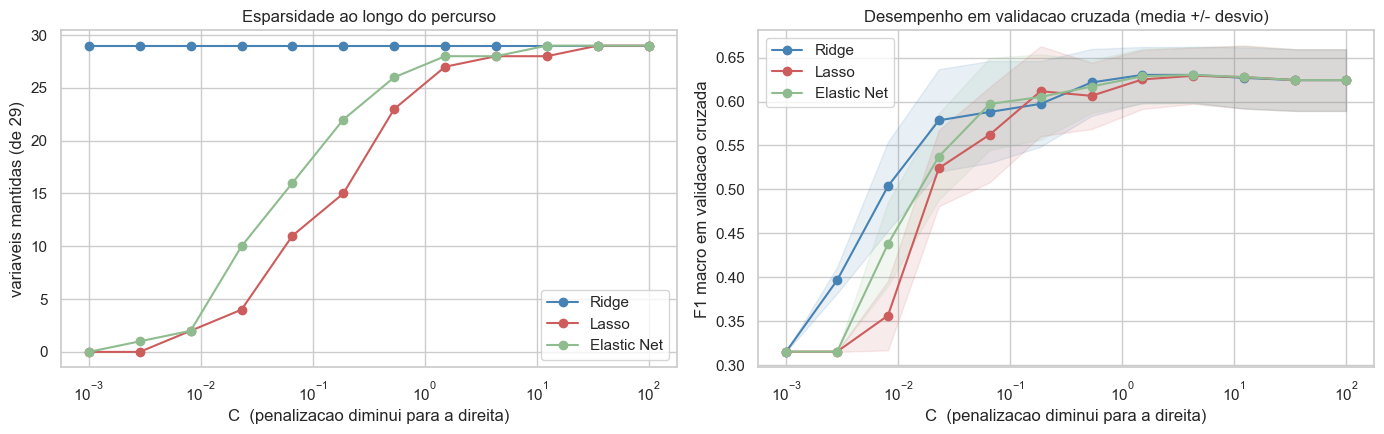

In [70]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
cores = {'Ridge': 'steelblue', 'Lasso': 'indianred', 'Elastic Net': 'darkseagreen'}

for nome, _ in MODELOS:
    linhas_modelo = percurso[percurso['modelo'] == nome]
    ax1.plot(linhas_modelo['C'], linhas_modelo[COL_VARIAVEIS], 'o-',
             color=cores[nome], label=nome)
    media = linhas_modelo['F1 macro (CV)']
    desvio = linhas_modelo['desvio (CV)']
    ax2.plot(linhas_modelo['C'], media, 'o-', color=cores[nome], label=nome)
    ax2.fill_between(linhas_modelo['C'], media - desvio, media + desvio,
                     color=cores[nome], alpha=0.12)

ax1.set_xscale('log'); ax1.set_xlabel('C  (penalizacao diminui para a direita)')
ax1.set_ylabel(COL_VARIAVEIS)
ax1.set_title('Esparsidade ao longo do percurso'); ax1.legend()

ax2.set_xscale('log'); ax2.set_xlabel('C  (penalizacao diminui para a direita)')
ax2.set_ylabel('F1 macro em validacao cruzada')
ax2.set_title('Desempenho em validacao cruzada (media +/- desvio)'); ax2.legend()

plt.tight_layout(); plt.show()

**Conclusões:** O percurso mostra, nos dois painéis, comportamentos muito diferentes entre as três
penalizações.

**Esparsidade.** O **Ridge mantém as 29 variáveis em todos os valores de `C`**, do mais penalizado ao
menos penalizado. É a demonstração visual de que o Ridge nunca seleciona: encolhe os coeficientes mas
não os anula. O **Lasso** é o mais agressivo, com nenhuma variável até `C` igual a 0.0028, duas em
0.008, que são `HbA1c_level` e `triglycerides`, quatro em 0.023, onze em 0.066, quinze em 0.187, vinte
e três em 0.534 e vinte e sete em 1.52, só chegando às vinte e nove em 35.1. O **Elastic Net** fica
entre os dois, como se espera de uma mistura das duas normas: dez variáveis onde o Lasso tem quatro,
dezasseis onde tem onze, e vinte e duas onde tem quinze.

Uma ressalva sobre a contagem do Ridge. Em `C` igual a 0.001 conta 29 variáveis mantidas, mas o seu F1
macro é 0.3155, exatamente o do classificador trivial. Os coeficientes estão todos praticamente a zero
sem estarem **exatamente** a zero, e o limiar de 1e-4 usado na contagem não distingue as duas
situações. **A contagem de variáveis mantidas só é informativa para penalizações que anulam
coeficientes**, ou seja para o Lasso e o Elastic Net.

**Desempenho.** As três curvas têm a mesma forma, sobem, atingem um máximo de **0.6303** e estabilizam.
O Ridge chega lá em `C` igual a 1.5199, o Elastic Net em 4.3288 e o Lasso fica ligeiramente abaixo, com
0.6293 em 4.3288. A diferença entre o melhor e o pior é de 0.0010, contra um desvio entre partições de
cerca de 0.032.

Em penalização forte, porém, **o Ridge é claramente melhor**: em `C` igual a 0.0231 obtém 0.5786 contra
0.5242 do Lasso. Faz sentido, porque nesse regime o Lasso já só tem quatro variáveis enquanto o Ridge
conserva um pouco de todas. A vantagem desaparece assim que a penalização afrouxa.

A partir de `C` igual a 35.1 as três estabilizam em 0.6244, que corresponde ao modelo praticamente sem
regularização. **Regularizar traz um ganho real, de 0.0059 em F1 macro**, mas modesto.

O máximo de cada uma destas curvas é exatamente o que a secção seguinte utiliza.

## 20. Escolha de C por validação cruzada

O percurso da secção anterior já contém tudo o que é preciso para decidir: para cada penalização e cada
valor de `C`, a média e o desvio-padrão do F1 macro obtido nas cinco partições de validação. Basta
portanto **tomar o máximo de cada curva**, sem repetir cálculos.

Escolhido o `C`, cada modelo é reajustado sobre a totalidade do treino e só então avaliado no conjunto
de teste, que até este ponto não participou em nenhuma decisão.

In [71]:
def ajustar_em(l1_ratio, C, X_treino_df, media, desvio, class_weight=None):
    """Reajusta o modelo no treino completo para um C ja escolhido."""
    escala = StandardScaler()
    X_esc = escala.fit_transform(X_treino_df)
    modelo = LogisticRegression(solver='saga', l1_ratio=l1_ratio, C=C,
                                max_iter=10000, class_weight=class_weight,
                                random_state=RANDOM_STATE).fit(X_esc, y_train)
    return {'C': C, 'f1_cv': media, 'desvio_cv': desvio,
            'modelo': modelo, 'escala': escala}

def afinar(l1_ratio, X_treino_df, class_weight=None, grelha=None):
    """Percorre uma grelha de C, escolhe o melhor e reajusta no treino completo."""
    grelha = GRELHA_C if grelha is None else grelha
    avaliacoes = [(C,) + avaliar_cv(l1_ratio, C, X_treino_df, y_train, class_weight)
                  for C in grelha]
    melhor_C, media, desvio = max(avaliacoes, key=lambda linha: linha[1])
    return ajustar_em(l1_ratio, melhor_C, X_treino_df, media, desvio, class_weight)

def resumo(ajuste, nome, X_teste_df, nomes_colunas, k):
    previsto = ajuste['modelo'].predict(ajuste['escala'].transform(X_teste_df))
    recalls = recall_score(y_test, previsto, average=None, labels=classes)
    _, _, n_colunas = variaveis_mantidas(ajuste['modelo'], nomes_colunas)
    return {'modelo': nome, 'variaveis do conjunto': k, 'C*': ajuste['C'],
            'F1 macro (CV)': ajuste['f1_cv'],
            'desvio (CV)': ajuste['desvio_cv'],
            'F1 macro (teste)': f1_score(y_test, previsto, average='macro'),
            'accuracy': accuracy_score(y_test, previsto),
            'balanced acc': balanced_accuracy_score(y_test, previsto),
            'colunas mantidas': n_colunas,
            **{f'recall {c}': r for c, r in zip(classes, recalls)}}

# O melhor C de cada modelo sai diretamente do percurso ja calculado na seccao 19
ajustes = {}
for nome, ratio in MODELOS:
    linhas_modelo = percurso[percurso['modelo'] == nome]
    melhor = linhas_modelo.loc[linhas_modelo['F1 macro (CV)'].idxmax()]
    ajustes[nome] = ajustar_em(ratio, melhor['C'], X_train,
                               melhor['F1 macro (CV)'], melhor['desvio (CV)'])

pd.DataFrame([resumo(a, nome, X_test, colunas, N_VARIAVEIS)
              for nome, a in ajustes.items()]).set_index('modelo').round(4)

,variaveis do conjunto,C*,F1 macro (CV),desvio (CV),F1 macro (teste),accuracy,balanced acc,colunas mantidas,recall DI_HT,recall DI_HY,recall HT
modelo,,,,,,,,,,,
Ridge,29,1.5199,0.6303,0.0318,0.5978,0.9440,0.6185,39,0.0000,0.9933,0.8621
Lasso,29,4.3288,0.6293,0.0319,0.5978,0.9440,0.6185,38,0.0000,0.9933,0.8621
Elastic Net,29,4.3288,0.6303,0.0318,0.5978,0.9440,0.6185,38,0.0000,0.9933,0.8621


**Conclusões:** Tomando o máximo de cada curva do percurso, o Ridge escolhe `C` igual a **1.5199** e o
Lasso e o Elastic Net escolhem **4.3288**. Os valores de F1 macro em validação cruzada são 0.6303 no
Ridge, 0.6293 no Lasso e 0.6303 no Elastic Net, com desvios entre partições de 0.0318, 0.0319 e 0.0318.
A diferença entre o melhor e o pior é de 0.0010, mais de trinta vezes menor do que a dispersão entre
partições. **Nenhuma das três é superior às outras neste problema.**

Note-se que o Ridge atinge 0.6303 tanto em `C` igual a 1.5199 como em 4.3288. Perante um empate, a
seleção fica com o primeiro, ou seja com a penalização mais forte, o que é a escolha preferível entre
duas soluções equivalentes.

No conjunto de teste, usado aqui pela primeira vez, os três obtêm exatamente o mesmo: 0.9440 de
*accuracy*, 0.6185 de balanced accuracy e 0.5978 de F1 macro. **O *recall* da classe `DI_HT` é 0.0000
nos três**, ou seja, nenhuma das 21 ocorrências desta classe é detetada. É o problema que a secção 24
aborda.

O `C` escolhido corresponde a uma penalização fraca, e por isso quase nenhuma variável é eliminada, com
38 a 39 colunas mantidas em 39 e as 29 variáveis presentes nos três modelos. Isto acontece porque a
penalização que maximiza o desempenho é insuficiente para anular coeficientes. Para obter um conjunto
efetivamente reduzido é necessário impor uma penalização mais forte, o que se faz na secção 23.

A grelha usada tem apenas doze valores, espaçados por um fator de **2.848**, que é a razão entre pontos
consecutivos de `np.logspace(-3, 2, 12)`. O `C` escolhido é por isso uma aproximação grosseira: o
verdadeiro ótimo pode estar em qualquer ponto entre os dois vizinhos. A secção seguinte procura, dentro
desse intervalo, um valor intermédio melhor.

## 21. Refinamento de C no intervalo mais favorável

A grelha da secção 19 percorre cinco ordens de grandeza em doze pontos, o que é adequado para localizar
a zona de bom desempenho mas demasiado largo para identificar o melhor valor dentro dela. Entre dois
pontos consecutivos há um fator de **2.848**, e o ótimo pode estar em qualquer ponto desse intervalo.

Refina-se por isso a procura. Para cada penalização toma-se o intervalo entre os **dois vizinhos** do
`C` escolhido na grelha grossa e avaliam-se nove valores igualmente espaçados em escala logarítmica,
pela mesma validação cruzada estratificada e com a padronização sempre feita dentro de cada partição.

Além da média do F1 macro, regista-se o **desvio-padrão entre as cinco partições**. É essa dispersão
que permite decidir se uma diferença entre dois valores de `C` é real ou se cabe dentro da variação
natural da validação cruzada.

In [72]:
def grelha_fina(C_central, n=9):
    """Nove valores entre os dois vizinhos de C_central na grelha grossa."""
    i = int(np.argmin(np.abs(GRELHA_C - C_central)))
    inferior = GRELHA_C[max(i - 1, 0)]
    superior = GRELHA_C[min(i + 1, len(GRELHA_C) - 1)]
    return np.logspace(np.log10(inferior), np.log10(superior), n)

percursos_finos = {}
for nome, ratio in MODELOS:
    linhas_finas = [{'C': C, 'F1 macro (CV)': m, 'desvio (CV)': d}
                    for C in grelha_fina(ajustes[nome]['C'])
                    for m, d in [avaliar_cv(ratio, C, X_train, y_train)]]
    percursos_finos[nome] = pd.DataFrame(linhas_finas)

comparacao_C = []
for nome, _ in MODELOS:
    percurso_fino = percursos_finos[nome]
    melhor = percurso_fino.loc[percurso_fino['F1 macro (CV)'].idxmax()]
    comparacao_C.append({
        'modelo': nome,
        'C (grelha grossa)': ajustes[nome]['C'],
        'F1 macro (grossa)': ajustes[nome]['f1_cv'],
        'C (grelha fina)': melhor['C'],
        'F1 macro (fina)': melhor['F1 macro (CV)'],
        'desvio (fina)': melhor['desvio (CV)'],
        'ganho': melhor['F1 macro (CV)'] - ajustes[nome]['f1_cv']})

comparacao_C = pd.DataFrame(comparacao_C).set_index('modelo')
comparacao_C

,C (grelha grossa),F1 macro (grossa),C (grelha fina),F1 macro (fina),desvio (fina),ganho
modelo,,,,,,
Ridge,1.5199,0.6303,1.5199,0.6303,0.0318,0.0000
Lasso,4.3288,0.6293,5.6234,0.6303,0.0318,0.0010
Elastic Net,4.3288,0.6303,3.3322,0.6303,0.0318,0.0000


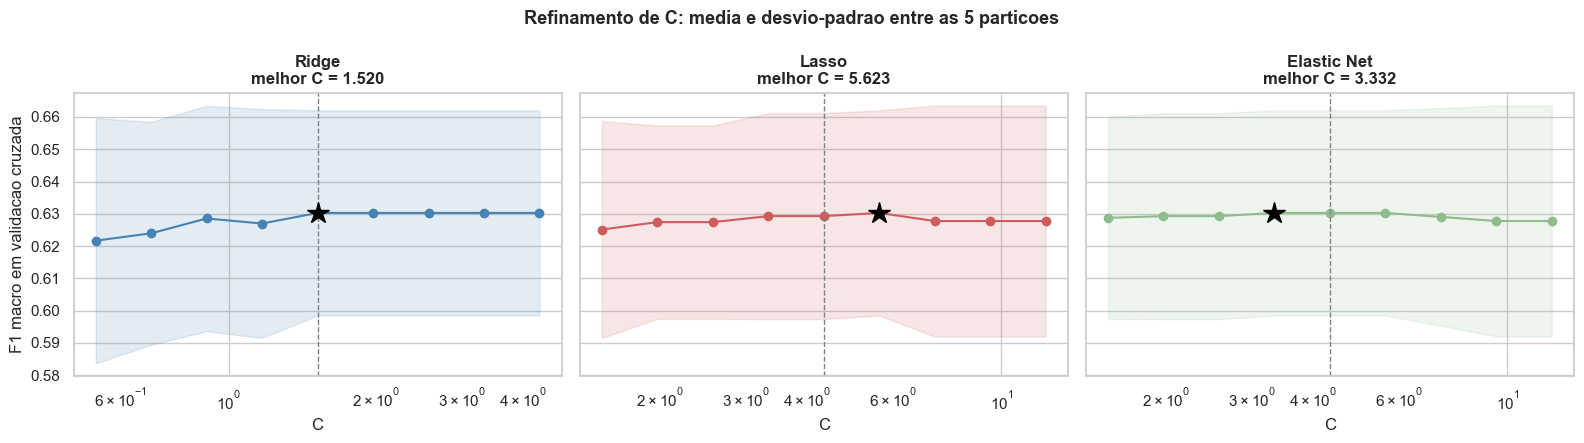

In [73]:
fig, eixos = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
cores = {'Ridge': 'steelblue', 'Lasso': 'indianred', 'Elastic Net': 'darkseagreen'}

for eixo, (nome, _) in zip(eixos, MODELOS):
    percurso_fino = percursos_finos[nome]
    media = percurso_fino['F1 macro (CV)']
    desvio = percurso_fino['desvio (CV)']
    eixo.plot(percurso_fino['C'], media, 'o-', color=cores[nome])
    eixo.fill_between(percurso_fino['C'], media - desvio, media + desvio,
                      color=cores[nome], alpha=0.15)
    eixo.axvline(ajustes[nome]['C'], ls='--', color='grey', lw=1)
    melhor = percurso_fino.loc[media.idxmax()]
    eixo.plot(melhor['C'], melhor['F1 macro (CV)'], '*', ms=16, color='black')
    eixo.set_xscale('log')
    eixo.set_xlabel('C')
    eixo.set_title(f"{nome}\nmelhor C = {melhor['C']:.3f}", weight='bold')

eixos[0].set_ylabel('F1 macro em validacao cruzada')
fig.suptitle('Refinamento de C: media e desvio-padrao entre as 5 particoes',
             fontsize=13, weight='bold')
plt.tight_layout(); plt.show()

**Conclusões:** O refinamento percorre, para o Ridge, o intervalo entre `C` igual a 0.534 e 4.329, e
para o Lasso e o Elastic Net o intervalo entre 1.520 e 12.329, que são em cada caso os dois vizinhos do
valor escolhido na grelha grossa.

Os resultados são praticamente nulos. O **Ridge mantém-se em 1.5199**, sem que nenhum dos nove valores
intermédios o supere. O **Lasso desloca-se para 5.6234**, com um ganho de 0.0010, e o **Elastic Net
para 3.3322**, com ganho zero, por empate com o valor anterior.

Curiosamente, após o refinamento **os três passam a ter exatamente o mesmo desempenho**, 0.6303 de F1
macro com desvio de 0.0318. A pequena vantagem que o Ridge e o Elastic Net tinham sobre o Lasso
desaparece quando este encontra o seu melhor valor.

A comparação decisiva é com o **desvio-padrão entre as cinco partições**, de 0.0318, ou seja mais de
trinta vezes o único ganho obtido. As bandas do gráfico tornam isso visível: a curva é **plana em toda
a região** e qualquer valor de `C` entre 1 e 10 produz um desempenho estatisticamente indistinguível.

A conclusão não é que o refinamento foi inútil, mas sim que **o desempenho é insensível a `C` nesta
zona**. Isso é informação útil, pois significa que a escolha do hiperparâmetro não é um ponto frágil do
modelo, e que não vale a pena procurar mais fundo: o que limita o desempenho é o sinal disponível nas
variáveis e não a afinação da penalização.

In [74]:
ajustes_finos = {nome: ajustar_em(ratio, linha['C (grelha fina)'], X_train,
                                  linha['F1 macro (fina)'], linha['desvio (fina)'])
                 for (nome, ratio), (_, linha) in zip(MODELOS, comparacao_C.iterrows())}

pd.DataFrame([resumo(a, nome, X_test, colunas, len(num_cols) + len(cat_cols))
              for nome, a in ajustes_finos.items()]).set_index('modelo').round(4)

,variaveis do conjunto,C*,F1 macro (CV),desvio (CV),F1 macro (teste),accuracy,balanced acc,colunas mantidas,recall DI_HT,recall DI_HY,recall HT
modelo,,,,,,,,,,,
Ridge,29,1.5199,0.6303,0.0318,0.5978,0.9440,0.6185,39,0.0000,0.9933,0.8621
Lasso,29,5.6234,0.6303,0.0318,0.5978,0.9440,0.6185,38,0.0000,0.9933,0.8621
Elastic Net,29,3.3322,0.6303,0.0318,0.5978,0.9440,0.6185,38,0.0000,0.9933,0.8621


**Conclusões:** Reajustando os modelos no `C` refinado e avaliando no conjunto de teste, os resultados
são **exatamente iguais aos da grelha grossa**: 0.9440 de *accuracy*, 0.6185 de balanced accuracy e
0.5978 de F1 macro nos três.

Isto confirma a planura observada na validação cruzada. Verificou-se que, nos três modelos, a passagem
do `C` grosso para o refinado **não altera uma única das 500 previsões do teste**.

Os *recalls* por classe expõem o problema real: 0.9933 em `DI_HY`, 0.8621 em `HT` e **0.0000 em
`DI_HT`**. O modelo não deteta um único caso da classe minoritária, limitação que a secção 24 aborda.

## 22. Coeficientes e variáveis selecionadas

Comparam-se as magnitudes dos coeficientes das três penalizações no valor de `C` refinado na secção
anterior. Como o problema tem três classes, o modelo estima uma matriz de coeficientes com uma linha
por classe, pelo que se usa o maior valor absoluto das três como medida da influência de cada coluna.

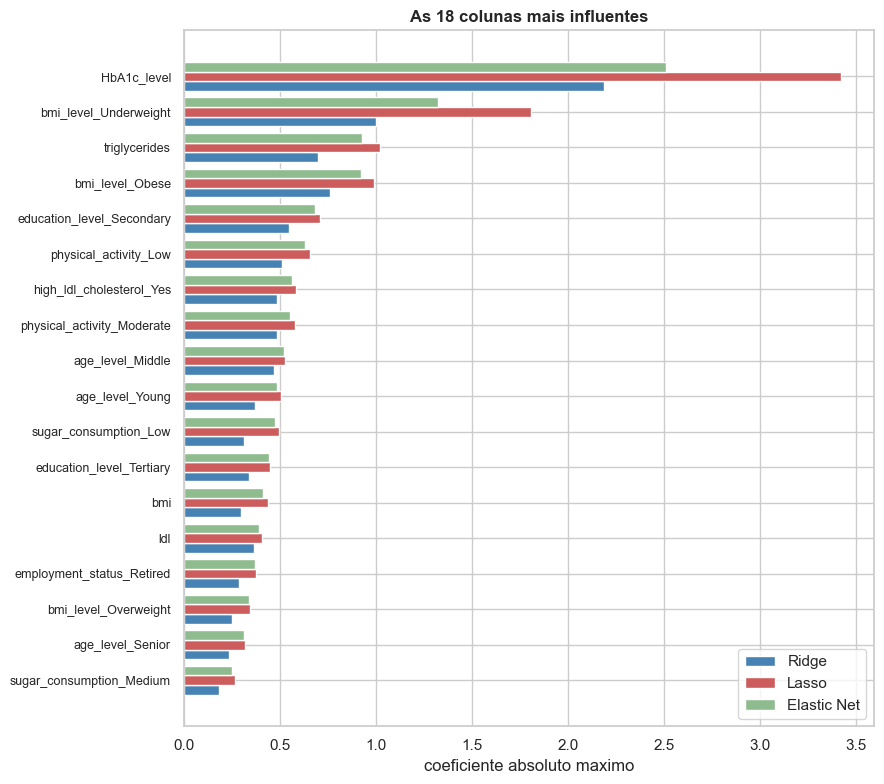

,Ridge,Lasso,Elastic Net
HbA1c_level,2.1857,3.4228,2.5093
bmi_level_Underweight,1.0014,1.8048,1.3216
triglycerides,0.6970,1.0225,0.9276
bmi_level_Obese,0.7577,0.9871,0.9231
education_level_Secondary,0.5477,0.7088,0.6841
physical_activity_Low,0.5101,0.6574,0.6271
high_ldl_cholesterol_Yes,0.4839,0.5799,0.5633
physical_activity_Moderate,0.4842,0.5796,0.5526
age_level_Middle,0.4658,0.5232,0.5221
age_level_Young,0.3695,0.5060,0.4815


In [75]:
tabela_coef = pd.DataFrame(
    {nome: magnitudes(a['modelo']) for nome, a in ajustes_finos.items()},
    index=colunas
).sort_values('Lasso', ascending=False)

fig, ax = plt.subplots(figsize=(9, 8))
topo = tabela_coef.head(18).iloc[::-1]
posicao = np.arange(len(topo))
for deslocamento, nome, cor in [(-0.27, 'Ridge', 'steelblue'),
                                (0.0, 'Lasso', 'indianred'),
                                (0.27, 'Elastic Net', 'darkseagreen')]:
    ax.barh(posicao + deslocamento, topo[nome], height=0.27, label=nome, color=cor)
ax.set_yticks(posicao); ax.set_yticklabels(topo.index, fontsize=9)
ax.set_xlabel('coeficiente absoluto maximo')
ax.set_title('As 18 colunas mais influentes', weight='bold'); ax.legend()
plt.tight_layout(); plt.show()

tabela_coef.round(4).head(12)

**Conclusões:** As três penalizações concordam na ordenação das variáveis. `HbA1c_level` domina de
forma destacada, com um coeficiente máximo de 3.42 no Lasso, cerca do dobro do seguinte, que é
`bmi_level_Underweight` com 1.80. Seguem-se `triglycerides` com 1.02, `bmi_level_Obese` com 0.99 e
`education_level_Secondary` com 0.71.

As magnitudes do Ridge são **sistematicamente menores nas variáveis dominantes**, com 2.19 contra 3.42
em `HbA1c_level` e 1.00 contra 1.80 em `bmi_level_Underweight`. É o efeito esperado da norma L2, que
distribui a penalização por todos os coeficientes em vez de a concentrar nos pequenos. O Elastic Net
fica, também aqui, entre os outros dois.

Esta hierarquia coincide com a que a análise exploratória tinha estabelecido por via estatística, nos
testes de Kruskal-Wallis, onde `HbA1c_level` e `triglycerides` apresentaram os maiores tamanhos de
efeito, com η² de 0.410 e 0.105, e onde `bmi_level` surgiu entre as categóricas com maior V de Cramér.
**Dois métodos independentes identificam as mesmas variáveis como relevantes.**

## 23. Conjunto completo vs. conjuntos reduzidos

O enunciado pede que se avalie o **impacto** da seleção de *features* no desempenho. Impacto é uma
diferença, e por isso é preciso comparar o conjunto completo com conjuntos mais pequenos, nas mesmas
condições.

**De onde vêm os conjuntos reduzidos.** Não são escolhidos à mão nem retirados das conclusões da
análise exploratória. São os conjuntos que o **próprio Lasso seleciona** em dois pontos do percurso da
secção 19, bastando para isso impor uma penalização mais forte do que a que maximiza o desempenho.

**Porquê estes dois pontos e não outros.** O percurso tem doze valores de `C`, mas a maior parte não
serve para esta comparação:

| `C` | Variáveis mantidas | Porque não serve, ou serve |
|---|---|---|
| 0.001 a 0.0028 | 0 | o modelo colapsa na classe maioritária |
| 0.0081 a 0.0231 | 2 a 4 | redução demasiado violenta, o modelo deixa de ser utilizável |
| **0.0658** | **11** | **corte agressivo, pouco mais de um terço das variáveis, e ainda funcional** |
| **0.1874** | **15** | **corte intermédio, aproximadamente metade das variáveis** |
| 0.5337 | 23 | mantém 23 de 29, pouca redução a medir |
| 1.5199 e acima | 27 a 29 | praticamente nenhuma redução |

Os dois pontos escolhidos são, portanto, **os únicos em que existe de facto um compromisso para
quantificar**: um corte moderado e um corte agressivo, suficientemente afastados um do outro para que a
diferença entre eles seja visível, e ambos acima do limiar em que o modelo deixa de funcionar.

**O que este critério é e o que não é.** É uma decisão sobre a granularidade da comparação, tomada à
vista do percurso, e não um critério estatístico. Existem regras formais para escolher o nível de
penalização, mas não fazem parte da matéria dada, e por isso prefere-se assumir o julgamento a invocar
um rigor que não se aplicou. O que **não** é decisão nossa é a composição dos conjuntos: dado o ponto
de corte, as variáveis que o compõem são determinadas inteiramente pelo Lasso.

Cada conjunto é avaliado com as três penalizações, com o `C` novamente escolhido pelo mesmo
procedimento em duas fases da secção 21 e a padronização refeita dentro de cada partição, para que a
comparação seja justa.

In [76]:
def colunas_das_variaveis(variaveis_num, variaveis_cat):
    """Colunas codificadas que correspondem a um conjunto de variaveis originais."""
    return [c for c in colunas
            if c in variaveis_num or any(c.startswith(k + '_') for k in variaveis_cat)]

def selecao_do_lasso(C):
    modelo = LogisticRegression(solver='saga', l1_ratio=1.0, C=C,
                                max_iter=10000, random_state=RANDOM_STATE)
    modelo.fit(X_train_esc, y_train)
    mantidas_num, mantidas_cat, _ = variaveis_mantidas(modelo, colunas)
    return mantidas_num, mantidas_cat

def afinar_em_duas_fases(l1_ratio, X_treino_df):
    """Grelha grossa seguida de refinamento, como na seccao 21."""
    grosso = afinar(l1_ratio, X_treino_df)
    return afinar(l1_ratio, X_treino_df, grelha=grelha_fina(grosso['C']))

# Dois pontos do percurso da seccao 19: penalizacao intermedia e penalizacao forte
C_INTERMEDIO, C_FORTE = GRELHA_C[5], GRELHA_C[4]
medio_num, medio_cat = selecao_do_lasso(C_INTERMEDIO)
forte_num, forte_cat = selecao_do_lasso(C_FORTE)
n_medio = len(medio_num) + len(medio_cat)
n_forte = len(forte_num) + len(forte_cat)

CONJUNTOS = {
    'Completo': (num_cols, cat_cols),
    f'Reduzido ({n_medio})': (medio_num, medio_cat),
    f'Reduzido ({n_forte})': (forte_num, forte_cat),
}

print(f'Conjunto reduzido com {n_forte} variaveis (C = {C_FORTE:.4f}):')
print(' ', sorted(forte_num + forte_cat))
print(f'\nEliminadas no conjunto de {n_medio} variaveis (C = {C_INTERMEDIO:.4f}):')
print(' ', sorted(set(num_cols + cat_cols) - set(medio_num + medio_cat)))

linhas_comp = []
for nome, (v_num, v_cat) in CONJUNTOS.items():
    cols_conj = colunas_das_variaveis(v_num, v_cat)
    for lab, ratio in MODELOS:
        ajuste = afinar_em_duas_fases(ratio, X_train[cols_conj])
        linhas_comp.append(resumo(ajuste, f'{nome} | {lab}', X_test[cols_conj],
                                  cols_conj, len(v_num) + len(v_cat)))

resultados = pd.DataFrame(linhas_comp).set_index('modelo')
resultados.round(4)

Conjunto reduzido com 11 variaveis (C = 0.0658):
  ['HbA1c_level', 'age', 'age_level', 'blood_pressure', 'bmi', 'bmi_level', 'crp_level', 'employment_status', 'low_hdl_cholesterol', 'smoking', 'triglycerides']

Eliminadas no conjunto de 15 variaveis (C = 0.1874):
  ['age', 'alcohol_intake', 'bmi', 'cholesterol', 'diastolic_bp', 'family_history', 'gender', 'hdl', 'heart_rate', 'ldl', 'salt_intake', 'sleep_hours', 'stress_level', 'systolic_bp']


,variaveis do conjunto,C*,F1 macro (CV),desvio (CV),F1 macro (teste),accuracy,balanced acc,colunas mantidas,recall DI_HT,recall DI_HY,recall HT
modelo,,,,,,,,,,,
Completo | Ridge,29,1.5199,0.6303,0.0318,0.5978,0.9440,0.6185,39,0.0000,0.9933,0.8621
Completo | Lasso,29,5.6234,0.6303,0.0318,0.5978,0.9440,0.6185,38,0.0000,0.9933,0.8621
Completo | Elastic Net,29,3.3322,0.6303,0.0318,0.5978,0.9440,0.6185,38,0.0000,0.9933,0.8621
Reduzido (15) | Ridge,15,1.9745,0.6472,0.0247,0.6020,0.9440,0.6185,24,0.0000,0.9933,0.8621
Reduzido (15) | Lasso,15,4.3288,0.6458,0.0237,0.6020,0.9440,0.6185,24,0.0000,0.9933,0.8621
Reduzido (15) | Elastic Net,15,3.3322,0.6458,0.0237,0.6020,0.9440,0.6185,24,0.0000,0.9933,0.8621
Reduzido (11) | Ridge,11,0.6933,0.6152,0.0519,0.5967,0.9400,0.6170,17,0.0000,0.9889,0.8621
Reduzido (11) | Lasso,11,0.9006,0.6201,0.0635,0.5967,0.9400,0.6170,16,0.0000,0.9889,0.8621
Reduzido (11) | Elastic Net,11,1.1700,0.6152,0.0519,0.5967,0.9400,0.6170,17,0.0000,0.9889,0.8621


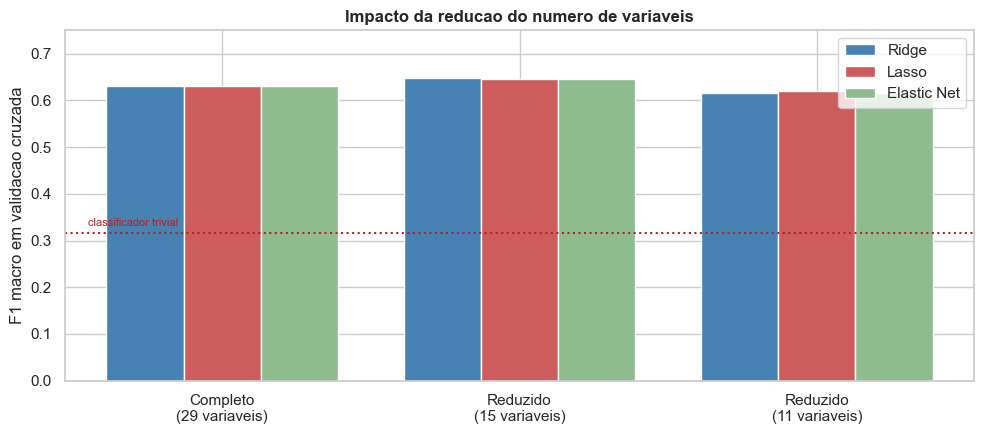

In [77]:
fig, ax = plt.subplots(figsize=(10, 4.5))
largura = 0.26
posicao = np.arange(len(CONJUNTOS))
for deslocamento, (lab, _), cor in zip([-largura, 0, largura], MODELOS,
                                       ['steelblue', 'indianred', 'darkseagreen']):
    valores = [resultados.loc[f'{nome} | {lab}', 'F1 macro (CV)'] for nome in CONJUNTOS]
    ax.bar(posicao + deslocamento, valores, largura, label=lab, color=cor)
ax.set_xticks(posicao)
ax.set_xticklabels([f"{n.split(' (')[0]}\n({len(v[0]) + len(v[1])} variaveis)"
                    for n, v in CONJUNTOS.items()])
# Referencia: o pior ponto do percurso, onde o modelo preve so a classe maioritaria
trivial = percurso['F1 macro (CV)'].min()
ax.axhline(trivial, ls=':', color='firebrick')
ax.text(-0.45, trivial + 0.015, 'classificador trivial', fontsize=8, color='firebrick')

ax.set_ylabel('F1 macro em validacao cruzada'); ax.set_ylim(0, 0.75)
ax.set_title('Impacto da reducao do numero de variaveis', weight='bold'); ax.legend()
plt.tight_layout(); plt.show()

**Conclusões:** O resultado é mais forte do que a simples ausência de custo.

| Conjunto | Variáveis | Melhor F1 macro (CV) | Diferença para o completo | Desvio (CV) |
|---|---|---|---|---|
| Completo | 29 | 0.6303 | - | 0.0318 |
| Reduzido | 15 | **0.6472** (Ridge) | **+0.0169** | 0.0247 |
| Reduzido | 11 | 0.6201 (Lasso) | −0.0102 | 0.0635 |

**Reduzir a quase metade das variáveis melhora o desempenho.** O conjunto de 15 variáveis atinge 0.6472
em validação cruzada contra 0.6303 do completo, e consegue-o com um **desvio entre partições menor**,
0.0247 contra 0.0318. No conjunto de teste a vantagem mantém-se, embora mais pequena, com 0.6020 contra
0.5978. Isto é o comportamento clássico da seleção de *features*: remover variáveis sem sinal reduz a
variância do modelo e o ganho compensa o pouco que se perde em viés.

A ressalva obrigatória é que **+0.0169 continua a ser inferior ao desvio entre partições**, pelo que a
evidência aponta no sentido da melhoria mas não a estabelece de forma conclusiva.

Descer a 11 variáveis já tem um preço, de 0.0102 face ao completo, e sobretudo torna o resultado
**muito mais instável**, com o desvio a subir para 0.0635, o dobro do conjunto completo. É o sinal de
que se cortou abaixo do necessário.

**Os conjuntos não são encaixados, e isso é informativo.** As 11 variáveis **não** são um subconjunto
das 15: `age` e `bmi` entram em `C` igual a 0.0658 e saem em 0.1874. A razão é que o conjunto de 15
inclui `age_level` e `bmi_level`, as versões discretizadas das mesmas grandezas. Com mais orçamento de
penalização, o Lasso **troca** a variável contínua pela categórica, que capta a mesma informação de
forma mais eficaz para este problema. O percurso do Lasso não é, portanto, uma sequência de inclusões:
variáveis podem entrar e voltar a sair.

**A seleção concorda com a análise exploratória.** Das 14 variáveis eliminadas no conjunto de 15, onze,
`alcohol_intake`, `cholesterol`, `diastolic_bp`, `gender`, `hdl`, `heart_rate`, `ldl`, `salt_intake`,
`sleep_hours`, `stress_level` e `systolic_bp`, **constam todas** da lista de variáveis que os testes
estatísticos tinham classificado como não informativas (p-value acima de 0.05 no Kruskal-Wallis ou no
χ²). Dessa lista só `crp_level` e `plasma_value` escapam ao corte. As outras três são `age`, `bmi` e `family_history`, e as duas
primeiras saem apenas porque as suas versões discretizadas ficaram, como se explicou acima.

O conjunto de 11 mantém `HbA1c_level`, `triglycerides`, `age`, `bmi` e `blood_pressure`, cinco das seis
variáveis numéricas com efeito significativo na análise exploratória, mais `age_level`, `bmi_level` e
`low_hdl_cholesterol`, esta última a de maior V de Cramér. Inclui porém `crp_level`, que os testes
estatísticos não tinham destacado, com p-value de 0.298. A seleção por penalização **não elimina todo o
ruído**, o que justifica confrontá-la sempre com a evidência estatística prévia.

Dentro de cada conjunto as três penalizações são praticamente equivalentes, com diferenças máximas de
0.0049. O *recall* de `DI_HT` é **zero em todas as nove combinações**, o que mostra que o problema do
desequilíbrio não se resolve por via da seleção de variáveis nem da regularização.

Uma ressalva de método: os conjuntos reduzidos são definidos por um Lasso ajustado sobre a totalidade
do treino e depois avaliados por validação cruzada sobre esse mesmo treino. As partições de validação
contribuíram indiretamente para a escolha das variáveis, pelo que os valores dos conjuntos reduzidos
são ligeiramente otimistas. O conjunto de teste, esse, nunca participou em nenhuma decisão.

## 24. Efeito do balanceamento das classes

Todos os modelos anteriores obtêm *accuracy* acima de 0.94 mas balanced accuracy de apenas 0.6185. A
razão é que acertam quase sempre na classe maioritária e falham a minoritária, consequência de cerca de
90 por cento dos registos pertencerem a uma única classe.

O parâmetro `class_weight='balanced'` pondera cada classe pelo inverso da sua frequência, obrigando o
modelo a dar importância às classes pequenas. Com 1348 registos `DI_HY`, 88 `HT` e 64 `DI_HT` no
treino, os pesos atribuídos são 0.371, 5.682 e 7.812.

As duas configurações são afinadas pelo **mesmo procedimento em duas fases** usado nas secções 20 e 21.

Esta comparação usa apenas a **penalização L2**, porque o algoritmo `saga` **não
converge** quando se aplica `class_weight`. 

A alternativa seria o `liblinear`, mas esse deixou de suportar problemas multiclasse a partir da versão
1.8 do scikit-learn. O `lbfgs`, que converge sem dificuldade, **suporta apenas a penalização L2**, pelo
que o Lasso e o Elastic Net ficam sem solver viável nesta comparação. Usa-se por isso `lbfgs` com L2
nos dois lados, o que mantém a comparação internamente coerente.

In [78]:
def avaliar_cv_lbfgs(C, class_weight):
    """Mesma validacao cruzada manual, com o solver lbfgs e penalizacao L2."""
    pontuacoes = []
    for idx_treino, idx_validacao in cv.split(X_train, y_train):
        escala = StandardScaler()
        X_a_esc = escala.fit_transform(X_train.iloc[idx_treino])
        X_b_esc = escala.transform(X_train.iloc[idx_validacao])
        modelo = LogisticRegression(solver='lbfgs', l1_ratio=0.0, C=C, max_iter=10000,
                                    class_weight=class_weight,
                                    random_state=RANDOM_STATE)
        modelo.fit(X_a_esc, y_train.iloc[idx_treino])
        pontuacoes.append(f1_score(y_train.iloc[idx_validacao],
                                   modelo.predict(X_b_esc), average='macro'))
    return float(np.mean(pontuacoes)), float(np.std(pontuacoes))

def afinar_lbfgs_duas_fases(class_weight):
    """Grelha grossa seguida de refinamento, como nas seccoes 20 e 21."""
    grosso = max(((C,) + avaliar_cv_lbfgs(C, class_weight) for C in GRELHA_C),
                 key=lambda linha: linha[1])
    fino = max(((C,) + avaliar_cv_lbfgs(C, class_weight) for C in grelha_fina(grosso[0])),
               key=lambda linha: linha[1])
    return grosso, fino

comparacao_peso = []
previsoes = {}
for peso in (None, 'balanced'):
    grosso, fino = afinar_lbfgs_duas_fases(peso)
    melhor_C, f1_cv, desvio_cv = fino

    escala = StandardScaler()
    X_esc = escala.fit_transform(X_train)
    modelo = LogisticRegression(solver='lbfgs', l1_ratio=0.0, C=melhor_C,
                                max_iter=10000, class_weight=peso,
                                random_state=RANDOM_STATE).fit(X_esc, y_train)
    previsto = modelo.predict(escala.transform(X_test))
    recalls = recall_score(y_test, previsto, average=None, labels=classes)
    comparacao_peso.append({
        'class_weight': str(peso),
        'C (grelha grossa)': grosso[0], 'F1 macro (grossa)': grosso[1],
        'C* (refinado)': melhor_C,
        'F1 macro (CV)': f1_cv, 'desvio (CV)': desvio_cv,
        'F1 macro (teste)': f1_score(y_test, previsto, average='macro'),
        'accuracy': accuracy_score(y_test, previsto),
        'balanced acc': balanced_accuracy_score(y_test, previsto),
        **{f'recall {c}': r for c, r in zip(classes, recalls)}})
    previsoes[str(peso)] = previsto

pd.DataFrame(comparacao_peso).set_index('class_weight').round(4)

,C (grelha grossa),F1 macro (grossa),C* (refinado),F1 macro (CV),desvio (CV),F1 macro (teste),accuracy,balanced acc,recall DI_HT,recall DI_HY,recall HT
class_weight,,,,,,,,,,,
None,1.5199,0.6303,1.5199,0.6303,0.0318,0.5978,0.9440,0.6185,0.0000,0.9933,0.8621
balanced,0.0081,0.6224,0.0137,0.6252,0.0302,0.6585,0.8460,0.7809,0.5238,0.8533,0.9655


=== sem balanceamento ===
              precision    recall  f1-score   support

       DI_HT     0.0000    0.0000    0.0000        21
       DI_HY     0.9551    0.9933    0.9739       450
          HT     0.7812    0.8621    0.8197        29

    accuracy                         0.9440       500
   macro avg     0.5788    0.6185    0.5978       500
weighted avg     0.9049    0.9440    0.9240       500

=== com class_weight='balanced' ===
              precision    recall  f1-score   support

       DI_HT     0.1528    0.5238    0.2366        21
       DI_HY     0.9871    0.8533    0.9154       450
          HT     0.7179    0.9655    0.8235        29

    accuracy                         0.8460       500
   macro avg     0.6193    0.7809    0.6585       500
weighted avg     0.9365    0.8460    0.8815       500



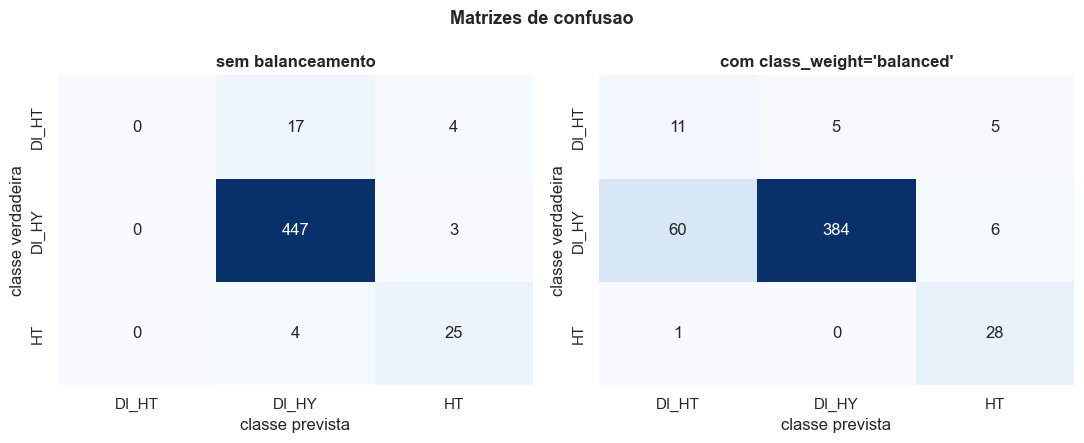

In [79]:
CONFIGURACOES = [('None', 'sem balanceamento'),
                 ('balanced', "com class_weight='balanced'")]

for rotulo, titulo in CONFIGURACOES:
    print(f'=== {titulo} ===')
    print(classification_report(y_test, previsoes[rotulo], labels=classes, digits=4))

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.5))
for eixo, (rotulo, titulo) in zip(eixos, CONFIGURACOES):
    matriz = confusion_matrix(y_test, previsoes[rotulo], labels=classes)
    sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=classes, yticklabels=classes, ax=eixo)
    eixo.set_xlabel('classe prevista'); eixo.set_ylabel('classe verdadeira')
    eixo.set_title(titulo, weight='bold')
fig.suptitle('Matrizes de confusao', fontsize=13, weight='bold')
plt.tight_layout(); plt.show()

**Conclusões:** Desta vez o refinamento produz efeito do lado compensado. Sem compensação o melhor `C`
mantém-se em **1.5199**, com ganho zero. Com `class_weight='balanced'`, a grelha grossa escolhe 0.0081
e o refinamento desloca-o para **0.0137**, com um ganho de 0.0028, que continua a ser dez vezes menor
do que o desvio entre partições.

A penalização ótima com compensação é cerca de **cem vezes mais forte** do que sem ela. Ao dar peso
7.812 às 64 observações de `DI_HT`, o modelo passa a ter muito mais incentivo para se ajustar a casos
individuais, e precisa de regularização bastante mais agressiva para não o fazer em excesso.

**O efeito nas métricas é o resultado mais marcante de todo o notebook.** Sem compensação, o modelo
atinge 0.9440 de *accuracy* mas **0.0000 de *recall* em `DI_HT`**: não identifica uma única das 21
ocorrências desta classe. Com compensação, o *recall* sobe para 0.5238, a balanced accuracy de 0.6185
para 0.7809 e, ao contrário do que seria de esperar, **o F1 macro no teste também sobe**, de 0.5978
para 0.6585. A *accuracy* desce para 0.8460.

Ou seja, **neste caso a compensação não é um compromisso, é uma melhoria em quase toda a linha**. A
razão é que um *recall* de zero numa das três classes arrasta o F1 macro para baixo: o F1 dessa classe
é 0.0000 e entra na média com o mesmo peso das outras duas.

As matrizes de confusão mostram o que está por trás. Sem compensação, das 21 ocorrências reais de
`DI_HT` o modelo encaminha **17 para `DI_HY` e 4 para `HT`**, sem acertar nenhuma. Com compensação
identifica **11**, mas em contrapartida classifica erradamente **60 registos de `DI_HY` como `DI_HT`**.
O efeito na precisão é severo: em `DI_HT` fica em 0.1528, ou seja, quando o modelo anuncia `DI_HT`
acerta em cerca de um caso em cada sete.

Note-se ainda que a compensação **beneficia também a classe `HT`**, cujo *recall* sobe de 0.8621 para
0.9655.

Em ambas as configurações os erros concentram-se na separação entre `DI_HT` e `DI_HY`, as duas classes
cuja sobreposição a análise exploratória já tinha identificado.

A configuração preferível depende do custo relativo dos dois tipos de erro, informação de natureza
clínica que o enunciado não fornece. Mas aqui, ao contrário do caso habitual, a compensação melhora as
duas métricas que dão peso igual às classes e só piora a *accuracy*, que é precisamente a métrica
menos fiável neste problema.

## 25. Discussão

**As três penalizações desempenham de forma equivalente.** Depois do refinamento, Ridge, Lasso e
Elastic Net obtêm exatamente o mesmo F1 macro em validação cruzada no conjunto completo, 0.6303, e nos
conjuntos reduzidos as diferenças entre elas não passam de 0.0049, valor muito inferior ao
desvio-padrão entre partições, que ronda 0.03. A escolha entre elas não se justifica, neste problema,
pelo desempenho.

**O Ridge nunca seleciona, e agora vê-se.** No painel de esparsidade da secção 19 a sua linha é uma
horizontal em 29 variáveis para todos os valores de `C`, enquanto as do Lasso e do Elastic Net descem.
É a diferença entre encolher coeficientes e anulá-los, mostrada em vez de afirmada.

**O Ridge não tinha vantagem a oferecer.** A sua razão de ser é estabilizar coeficientes quando os
preditores estão correlacionados. A análise exploratória mostrou que, removidas as colunas redundantes,
**as correlações entre as variáveis retidas são praticamente nulas**, com todos os fatores de
inflação da variância abaixo de 1.05, sendo o máximo 1.0441, e o número de condição a cair de 1.75e+15
para 1.29 (Parte 1, secção 3.2). Em conjuntos de dados onde os preditores estão fortemente
correlacionados, o Ridge supera claramente a solução não regularizada; aqui não há colinearidade para
estabilizar.

**A afinação de `C` não é o fator limitante.** O refinamento da secção 21 mostrou que todo o intervalo
entre `C` igual a 1 e 10 produz desempenhos indistinguíveis, com ganhos trinta vezes menores do que a
variação entre partições. O que limita o modelo é o sinal disponível nas variáveis.

**A seleção de *features* compensa, e mais do que o esperado.** Passar de 29 para 15 variáveis **melhora**
o F1 macro em validação cruzada, de 0.6303 para 0.6472, e reduz a dispersão entre partições de 0.0318
para 0.0247. É o argumento clássico a favor da seleção: menos variáveis sem sinal significam menos
variância. Cortar além disso, para 11 variáveis, inverte o efeito e duplica a dispersão.

**A seleção confirma a análise exploratória.** Onze das catorze variáveis eliminadas sem custo são
exatamente as que os testes estatísticos tinham classificado como não informativas, e as que
sobrevivem às penalizações mais fortes incluem `HbA1c_level` e `triglycerides`, as duas com maior
tamanho de efeito. A concordância entre um método automático e uma análise estatística independente
reforça as duas.

**O desequilíbrio é a limitação dominante.** Nenhuma combinação de penalização e de conjunto de
variáveis deteta uma única ocorrência de `DI_HT`: o *recall* é zero nas nove combinações testadas na
secção 23. Só a compensação de classes resolve o problema, elevando-o para 0.5238. A limitação não está
na regularização, mas nas 85 ocorrências que esta classe tem no conjunto de dados.

## 26. Referências

**Enunciado e dados**

- *Aprendizagem Automática (APRAU), Assignment*, ISEP, MEI, 2026/2027, versão 1.0, secção 5.
- `dataset_grupo_22.csv`, subconjunto de 2000 registos fornecido ao grupo 22.

**Aulas da unidade curricular** (Elsa Ferreira Gomes, ISEP, 2026/2027)

- *T5, Linear Model Selection and Regularization: Ridge Regression, the Lasso and Elastic Net*,
  incluindo a secção sobre regularização aplicada à classificação.
- *TP5, Example: Ridge, Lasso and Elastic net Regression*, ficha prática consultada.
- *T4, Evaluation and Resampling*, para a validação cruzada estratificada.
- *Classification Metrics: Confusion Matrix and Beyond*, para a escolha das métricas.

**Bibliografia**

- James, G., Witten, D., Hastie, T., Tibshirani, R., *An Introduction to Statistical Learning with
  Python*, capítulo 6.

**Trabalho anterior do grupo**

- `notebooks/01_EDA.ipynb`, de onde provêm a remoção das colunas redundantes e as expectativas
  sobre quais as variáveis informativas.

**Bibliotecas**

- pandas, NumPy, Matplotlib, seaborn e scikit-learn.